# Nighttime Light and Industrial Enclaves: Regency Evidence from Indonesia's Nickel Downstreaming Region

Replication notebook. 79 regencies/cities in five provinces (North, Central, South and Southeast Sulawesi; North Maluku), 2015–2025.

[Author information removed for anonymized review]

**Hypothesis numbering.** The notebook keeps the numbering of the pre-analysis plans (H1–H8). In the manuscript: H1 = H1; H3 = H2 (confirmatory); H7 = H3a; H8 = H3b; H2 and H4 are reported as the level and curvature terms; H5–H6 = tests S1–S2 (Table 14).

**Figures.** The notebook draws only the figures in the manuscript (Figures 1–10) and saves them in `figures/`.

**Environment.** Python 3.11, scikit-learn 1.5.2, xgboost 3.0.5, numpy 2.0.2, scipy 1.15.3, pandas 2.2.3, linearmodels 7.1, statsmodels 0.15, geopandas 1.2, matplotlib 3.10, csdid 0.4.5. The machine-learning candidates of the dynamic nowcast (Section 13) depend on these versions.

## 1. Setup

In [1]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd

from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS, BetweenOLS
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, train_test_split,
                                      GridSearchCV, cross_val_score)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats as scipy_stats
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

mpl.rcParams.update({
    "figure.dpi": 500,
    "font.size": 11,
    "font.family": "serif",
    "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.frameon": False,
})
COLOR_INDUSTRIAL = "#C1622D"
COLOR_NONINDUSTRIAL = "#2E5266"
COLOR_NEUTRAL = "#182420"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

import os
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_figure(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=300, bbox_inches="tight")

## 2. Data

In [2]:
import glob, os, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import files
    print("Please upload merged_panel_2015_2025.csv, "
          "admin_boundaries_5prov.geojson and (optional) "
          "GRDP_sectoral_share_BC_2015_2023.xlsx ...")
    uploaded = files.upload()
    DATA_DIR = "."
else:
    DATA_DIR = "."

def find_file(keyword, folder=DATA_DIR, required=True):
    candidates = [f for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                if keyword.lower() in os.path.basename(f).lower()]
    if required:
        assert len(candidates) >= 1, f"No file found with keyword '{keyword}'"
    elif len(candidates) == 0:
        return None
    if len(candidates) > 1:
        print(f"  [info] >1 file matches '{keyword}', using the first: {candidates[0]}")
    return candidates[0]

FILE_PANEL = find_file("merged_panel")
print(f"  merged_panel -> {FILE_PANEL}")

FILE_VNL = find_file("VNL_annual_masked")
print(f"  VNL_annual_masked -> {FILE_VNL}")
FILE_GEOJSON = find_file("admin_boundaries", required=False)
HAS_MAP = FILE_GEOJSON is not None
if HAS_MAP:
    print(f"  admin_boundaries -> {FILE_GEOJSON}")
else:
    print("  admin_boundaries -> not uploaded, maps will be skipped.")

  merged_panel -> ./data/merged_panel_2015_2025.csv
  VNL_annual_masked -> ./data/VNL_annual_masked_5prov_2015_2025.csv
  admin_boundaries -> ./data/admin_boundaries_5prov.geojson


## 3. Data structure checks

In [3]:
YEARS_FULL = list(range(2015, 2026))

panel = pd.read_csv(FILE_PANEL)
panel["year"] = panel["year"].astype(int)

vnl = pd.read_csv(FILE_VNL)
vnl["year"] = vnl["year"].astype(int)
vnl = vnl.rename(columns={"regency": "regency"})
assert len(vnl) == 869 and not vnl.duplicated(["regency", "year"]).any()
assert vnl[["ntl_mean_masked", "ntl_sum_masked"]].notna().all().all(), "missing NTL"
assert (vnl["ntl_sum_masked"] > 0).all(), "SOL must be > 0 to take logs"
panel = panel.merge(vnl[["regency", "year", "ntl_mean_masked", "ntl_sum_masked",
                         "ntl_lit_pixels", "ntl_n_pixels", "ntl_mean_unmasked", "source_collection"]],
                    on=["regency", "year"], how="left", validate="one_to_one")
assert panel["ntl_sum_masked"].notna().all(), "regency-years not matched with the VNL file"
panel["viirs_vcmcfg_old"] = panel["viirs_mean_radiance"]
panel["viirs_mean_radiance"] = panel["ntl_sum_masked"]
print("VNL collection by year:", panel.groupby("year")["source_collection"].first().to_dict())

panel["industrial_dummy_original"] = panel["industrial_dummy"]
panel["start_year_original"] = panel["start_year"]
CLASSIFICATION_CORRECTIONS = {
    "Pulau Morotai": "only a special economic zone (PP 50/2014) and small tuna processing (~6 t/day, 2018, since closed); "
                     "no large industrial facility in operation",
}
YEAR_CORRECTIONS = {
    "Takalar": (1984, "PG Takalar sugar mill completed and first milling 1984 (council approval 1983)"),
    "Pangkajene Dan Kepulauan": (1971, "Tonasa I inaugurated 1971; 1968 = project agency established"),
    "Bone": (1975, "PG Bone sugar mill first milling and inauguration 15 Oct 1975"),
    "Minahasa Utara": (2011, "Toka Tindung: first gold pour Apr 2011, full production Nov 2011"),
    "Konawe Selatan": (2011, "Ifishdeco nickel mine producing since 2011; no new facility in 2023"),
    "Pinrang": (1991, "Bakaru hydropower plant 2x63 MW operating from about 1991"),
    "Bombana": (2007, "Kabaena nickel ore mining active since 2007; no local smelter documented"),
    "Pulau Taliabu": (2018, "PT Adidaya Tangguh iron-ore concentrator: completed Nov 2017, trial production 2018"),
    "Konawe Utara": (2021, "Antam Mandiodo nickel production 2021 (earliest documented year)"),
}
YEARS_WITHOUT_SOURCE = ["Buol", "Kolaka Utara"]
for reg in CLASSIFICATION_CORRECTIONS:
    m = panel["regency"] == reg
    assert m.sum() == 11 and panel.loc[m, "industrial_dummy"].eq(1).all(), reg
    panel.loc[m, "industrial_dummy"] = 0
    panel.loc[m, "start_year"] = np.nan
    if "industrial_class" in panel.columns:
        panel.loc[m, "industrial_class"] = "Non-industrial"
for reg, (th, _) in YEAR_CORRECTIONS.items():
    m = panel["regency"] == reg
    assert m.sum() == 11 and panel.loc[m, "industrial_dummy"].eq(1).all(), reg
    panel.loc[m, "start_year"] = th
table_corrections = pd.DataFrame(
    [dict(reg_city=k, change="industrial -> non-industrial", reason=v) for k, v in CLASSIFICATION_CORRECTIONS.items()] +
    [dict(reg_city=k, change=f"start year {panel.loc[panel.regency == k, 'start_year_original'].iloc[0]} -> {th}",
          reason=al) for k, (th, al) in YEAR_CORRECTIONS.items()])
print("\nData corrections v35 (based on source tracing):")
print(table_corrections.to_string(index=False))
print("Start years without a source (kept, flagged):", YEARS_WITHOUT_SOURCE)

EXPECTED_PER_PROVINCE = {
    "Sulawesi Utara": 15, "Sulawesi Tengah": 13, "Sulawesi Selatan": 24,
    "Sulawesi Tenggara": 17, "Maluku Utara": 10,
}
unique_ = sorted(panel["regency"].dropna().unique())
assert len(unique_) == 79, f"Expected 79 unique regencies/cities, got {len(unique_)}"

counts = panel.drop_duplicates("regency").groupby("province").size()
for prov, n in EXPECTED_PER_PROVINCE.items():
    assert counts[prov] == n, f"{prov}: got {counts[prov]}, expected {n}"

check_year = panel.groupby("year")["regency"].nunique()
problematic = check_year[check_year != 79]
assert problematic.empty, f"Years with number of regencies/cities != 79:\n{problematic}"

assert len(panel) == 79 * len(YEARS_FULL), \
    f"Panel must have {79 * len(YEARS_FULL)} rows (79 regencies/cities x 11 years), got {len(panel)}"

n_industrial = panel.loc[panel["year"] == 2015, "industrial_dummy"].sum()
assert n_industrial == 37, f"Expected 37 industrial regencies/cities (after v35 corrections), got {n_industrial}"

print(f"Validation OK: {panel.shape[0]} rows x {panel.shape[1]} columns "
      f"({panel['regency'].nunique()} regencies/cities x "
      f"{panel['year'].nunique()} years, {n_industrial} industrial regencies/cities, "
      f"{79 - n_industrial} non-industrial regencies/cities).")

if HAS_MAP:
    gdf_bounds = gpd.read_file(FILE_GEOJSON)
    bounds_name = set(gdf_bounds["regency"])
    panel_name = set(panel["regency"])
    difference = panel_name - bounds_name
    assert not difference, f"Regencies/cities in the panel without a polygon: {difference}"
    print(f"Administrative boundaries OK: {len(gdf_bounds)} polygons, "
          f"matches all 79 regencies/cities in the panel 1:1.")

VNL collection by year: {2015: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2016: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2017: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2018: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2019: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2020: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2021: 'NOAA/VIIRS/DNB/ANNUAL_V21', 2022: 'NOAA/VIIRS/DNB/ANNUAL_V22', 2023: 'NOAA/VIIRS/DNB/ANNUAL_V22', 2024: 'NOAA/VIIRS/DNB/ANNUAL_V22', 2025: 'NOAA/VIIRS/DNB/ANNUAL_V22'}

Data corrections v35 (based on source tracing):
                reg_city                       change                                                                                                                                        reason
           Pulau Morotai industrial -> non-industrial only a special economic zone (PP 50/2014) and small tuna processing (~6 t/day, 2018, since closed); no large industrial facility in operation
                 Takalar    start year 1982.0 -> 1984                                                                PG Takalar sugar mill completed 

Administrative boundaries OK: 79 polygons, matches all 79 regencies/cities in the panel 1:1.


## 4. Final panel and missing values

In [4]:
print("Missing values by column (before imputation):")
print(panel.isna().sum())

Missing values by column (before imputation):
province                       0
regency                        0
year                           0
viirs_mean_radiance            0
crops_frac_mean                8
precip_annual_mm               0
tmin_mean_C                    0
tmax_mean_C                    0
pop_density_per_km2            0
grdp_current_bn                0
grdp_constant_bn               0
pct_urban                      0
dominant_class                 0
industrial_dummy               0
industrial_class               0
start_year                   462
ntl_mean_masked                0
ntl_sum_masked                 0
ntl_lit_pixels                 0
ntl_n_pixels                   0
ntl_mean_unmasked              0
source_collection              0
viirs_vcmcfg_old               0
industrial_dummy_original      0
start_year_original          484
dtype: int64


### Imputation of `crops_frac_mean`

In [5]:
before_na = panel["crops_frac_mean"].isna().sum()
panel = panel.sort_values(["regency", "year"]).reset_index(drop=True)
panel["crops_frac_mean"] = (panel.groupby("regency")["crops_frac_mean"]
                             .bfill())
after_na = panel["crops_frac_mean"].isna().sum()

print(f"crops_frac_mean: {before_na} NaN (year 2015) filled by backward fill "
      f"(2016 value, same regency/city) -> {after_na} NaN remaining")
assert after_na == 0, "crops_frac_mean still has NaN after backward fill!"

print("\nMissing values by column (after imputation):")
print(panel.isna().sum())

crops_frac_mean: 8 NaN (year 2015) filled by backward fill (2016 value, same regency/city) -> 0 NaN remaining

Missing values by column (after imputation):
province                       0
regency                        0
year                           0
viirs_mean_radiance            0
crops_frac_mean                0
precip_annual_mm               0
tmin_mean_C                    0
tmax_mean_C                    0
pop_density_per_km2            0
grdp_current_bn                0
grdp_constant_bn               0
pct_urban                      0
dominant_class                 0
industrial_dummy               0
industrial_class               0
start_year                   462
ntl_mean_masked                0
ntl_sum_masked                 0
ntl_lit_pixels                 0
ntl_n_pixels                   0
ntl_mean_unmasked              0
source_collection              0
viirs_vcmcfg_old               0
industrial_dummy_original      0
start_year_original          484
dtype: int64


## 5. Feature engineering

### Variables in the main model

In [6]:
VARIABLE_SUMMARY = pd.DataFrame([
    dict(role="Y (dependent)",  variable="log_grdp_current",
         transformation="log(level)", description="GRDP (regency/city, current prices), main outcome"),
    dict(role="Y (robustness)", variable="log_grdp_constant",
         transformation="log(level)", description="GRDP (regency/city, constant prices), used in Section 11"),
    dict(role="X (logged)", variable="viirs_mean_radiance",
         transformation="log(x)", description="NTL = sum of lights, annual VIIRS VNL v2 'average_masked' (noise, fires and flares removed)"),
    dict(role="X (logged, derived)", variable="viirs2",
         transformation="(log NTL)^2", description="quadratic NTL term, from logged NTL"),
    dict(role="X (interaction)", variable="viirs_x_industrial",
         transformation="log(NTL) x dummy", description="core question: NTL effect differs between industrial and other regencies/cities"),
    dict(role="X (logged)", variable="pop_density_per_km2",
         transformation="log(x)", description="population density, highly skewed (9-2,882 people/km2)"),
    dict(role="X (logged)", variable="precip_annual_mm",
         transformation="log(x)", description="annual precipitation (ERA5-Land)"),
    dict(role="X (level, not logged)", variable="crops_frac_mean",
         transformation="not logged", description="cropland fraction 0-1, proxy for BPS harvested area"),
    dict(role="X (level, not logged)", variable="tmin_mean_C",
         transformation="not logged", description="mean minimum temperature (Celsius)"),
    dict(role="X (level, not logged)", variable="tmax_mean_C",
         transformation="not logged", description="mean maximum temperature (Celsius)"),
    dict(role="X (dummy, time-invariant)", variable="industrial_dummy",
         transformation="not logged (0/1)", description="documented industrial status, constant over 2015-2025"),
    dict(role="X (Section 10 only)", variable="pct_urban",
         transformation="not logged", description="2025 cross-section, treated as time-invariant"),
], columns=["role", "variable", "transformation", "description"])

print("=== Variables in the main model (Sections 7-11) ===")
VARIABLE_SUMMARY

=== Variables in the main model (Sections 7-11) ===


,role,variable,transformation,description
0,Y (dependent),log_grdp_current,log(level),"GRDP (regency/city, current prices), main outcome"
1,Y (robustness),log_grdp_constant,log(level),"GRDP (regency/city, constant prices), used in ..."
2,X (logged),viirs_mean_radiance,log(x),"NTL = sum of lights, annual VIIRS VNL v2 'aver..."
3,"X (logged, derived)",viirs2,(log NTL)^2,"quadratic NTL term, from logged NTL"
4,X (interaction),viirs_x_industrial,log(NTL) x dummy,core question: NTL effect differs between indu...
5,X (logged),pop_density_per_km2,log(x),"population density, highly skewed (9-2,882 peo..."
6,X (logged),precip_annual_mm,log(x),annual precipitation (ERA5-Land)
7,"X (level, not logged)",crops_frac_mean,not logged,"cropland fraction 0-1, proxy for BPS harvested..."
8,"X (level, not logged)",tmin_mean_C,not logged,mean minimum temperature (Celsius)
9,"X (level, not logged)",tmax_mean_C,not logged,mean maximum temperature (Celsius)


### Industrial classification

In [7]:
YEAR_MIN, YEAR_MAX = 2015, 2025

df = panel.query(f"{YEAR_MIN} <= year <= {YEAR_MAX}").copy()

df["log_grdp_current"] = np.log(df["grdp_current_bn"])
df["log_grdp_constant"] = np.log(df["grdp_constant_bn"])

df["viirs_radiance_raw"] = df["ntl_mean_masked"]
df["density_raw"] = df["pop_density_per_km2"]
df["precip_raw"] = df["precip_annual_mm"]

df["viirs_mean_radiance"] = np.log(df["ntl_sum_masked"])
df["pop_density_per_km2"] = np.log(df["density_raw"])
df["precip_annual_mm"] = np.log(df["precip_raw"])

df["viirs2"] = df["viirs_mean_radiance"] ** 2
df["viirs_x_industrial"] = df["viirs_mean_radiance"] * df["industrial_dummy"]

print(f"Analysis sample {YEAR_MIN}-{YEAR_MAX}: {df.shape[0]} rows "
      f"({df['regency'].nunique()} regencies/cities x "
      f"{df['year'].nunique()} years)")
print(f"Industrial regencies/cities : {df['industrial_dummy'].sum()//(YEAR_MAX-YEAR_MIN+1)}")
print(f"Non-industrial regencies/cities: {(1-df['industrial_dummy']).sum()//(YEAR_MAX-YEAR_MIN+1)}")
print("\nMissing values in main-model variables:")
model_vars = ["log_grdp_current", "viirs_mean_radiance", "pop_density_per_km2",
              "crops_frac_mean", "precip_annual_mm", "tmin_mean_C", "tmax_mean_C",
              "pct_urban"]
print(df[model_vars].isna().sum())

Analysis sample 2015-2025: 869 rows (79 regencies/cities x 11 years)
Industrial regencies/cities : 37
Non-industrial regencies/cities: 42

Missing values in main-model variables:
log_grdp_current       0
viirs_mean_radiance    0
pop_density_per_km2    0
crops_frac_mean        0
precip_annual_mm       0
tmin_mean_C            0
tmax_mean_C            0
pct_urban              0
dtype: int64


## 6. Descriptive statistics

In [8]:
desc_vars = ["log_grdp_current", "log_grdp_constant", "viirs_mean_radiance",
             "pop_density_per_km2", "crops_frac_mean", "precip_annual_mm",
             "tmin_mean_C", "tmax_mean_C", "pct_urban"]
labels_desc = {
    "log_grdp_current": "Log GRDP (regency/city, current prices)",
    "log_grdp_constant": "Log GRDP (regency/city, constant prices)",
    "viirs_mean_radiance": "Log NTL (sum of lights, VNL v2 masked)",
    "pop_density_per_km2": "Log population density",
    "crops_frac_mean": "Cropland fraction (Dynamic World)",
    "precip_annual_mm": "Log annual precipitation",
    "tmin_mean_C": "Mean minimum temperature (°C, not logged)",
    "tmax_mean_C": "Mean maximum temperature (°C, not logged)",
    "pct_urban": "% Urban villages",
}

table1 = df[desc_vars].agg(["count", "mean", "std", "min", "max"]).T
table1.columns = ["N", "Mean", "SD", "Min", "Max"]
table1["N"] = table1["N"].astype(int)
table1.index = [labels_desc[c] for c in table1.index]
table1 = table1.round(3)
print("Table 1. Descriptive Statistics of Model Variables, 2015-2025")
table1

Table 1. Descriptive Statistics of Model Variables, 2015-2025


,N,Mean,SD,Min,Max
"Log GRDP (regency/city, current prices)",869,9.008,0.962,6.848,12.474
"Log GRDP (regency/city, constant prices)",869,8.585,0.926,6.588,11.957
"Log NTL (sum of lights, VNL v2 masked)",869,6.657,1.281,2.591,10.291
Log population density,869,4.901,1.247,2.197,9.016
Cropland fraction (Dynamic World),869,0.066,0.032,0.035,0.222
Log annual precipitation,869,7.992,0.305,7.004,8.691
"Mean minimum temperature (°C, not logged)",869,22.735,1.994,17.163,26.607
"Mean maximum temperature (°C, not logged)",869,27.632,1.225,23.911,30.442
% Urban villages,869,29.419,25.256,3.390,100.000


In [9]:
df.groupby("industrial_dummy")[desc_vars].agg(["mean", "std"]).rename(
    index={0: "Non-industrial", 1: "Industrial"}).T

industrial_dummy          Non-industrial  Industrial
log_grdp_current    mean        8.677721    9.381855
                    std         0.814227    0.980311
log_grdp_constant   mean        8.261934    8.951749
                    std         0.784458    0.938249
viirs_mean_radiance mean        6.310206    7.050242
                    std         1.071635    1.382655
pop_density_per_km2 mean        5.076036    4.703136
                    std         1.186292    1.285619
crops_frac_mean     mean        0.062263    0.069474
                    std         0.026366    0.036562
precip_annual_mm    mean        7.959903    8.029029
                    std         0.322843    0.279513
tmin_mean_C         mean       23.098928   22.320938
                    std         2.093065    1.790854
tmax_mean_C         mean       27.663329   27.597106
                    std         1.193802    1.259529
pct_urban           mean       32.459762   25.968378
                    std        27.651248   21.749898

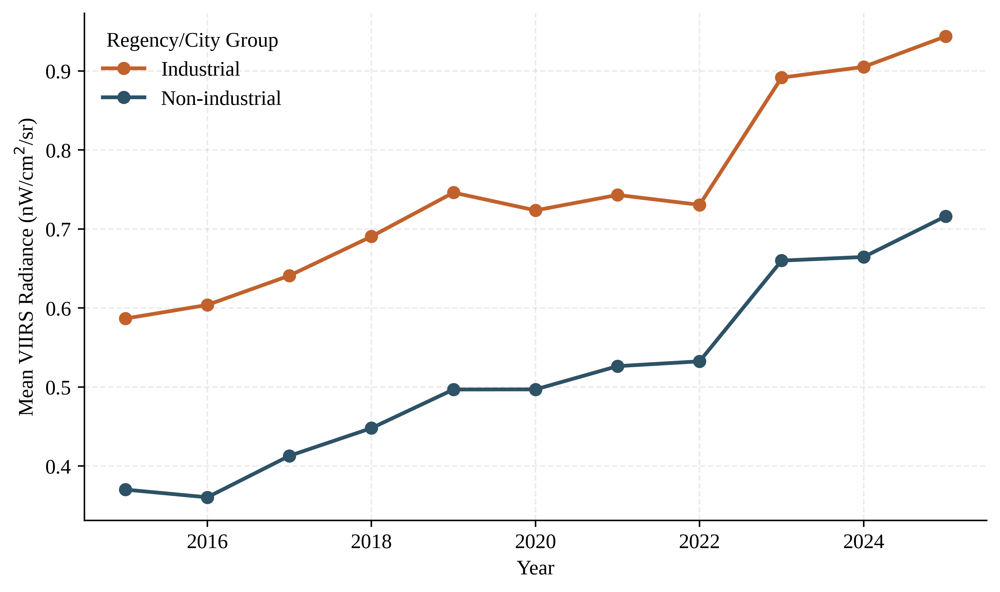

In [10]:
trend = (df.groupby(["year", "industrial_dummy"])["viirs_radiance_raw"]
           .mean().reset_index())

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for grp, color, label in [(1, COLOR_INDUSTRIAL, "Industrial"),
                           (0, COLOR_NONINDUSTRIAL, "Non-industrial")]:
    sub = trend[trend["industrial_dummy"] == grp]
    ax.plot(sub["year"], sub["viirs_radiance_raw"], marker="o",
            color=color, label=label, linewidth=2)
ax.set_xlabel("Year")
ax.set_ylabel("Mean VIIRS Radiance (nW/cm$^2$/sr)")
ax.legend(title="Regency/City Group")
fig.tight_layout()
save_figure(fig, "Figure_3")
plt.show()

In [11]:
corr_all = df[["viirs_mean_radiance", "log_grdp_current"]].corr().iloc[0, 1]
print(f"Pearson correlation of log NTL (SOL) and log(GRDP, current prices), all observations: r = {corr_all:.3f}")

Pearson correlation of log NTL (SOL) and log(GRDP, current prices), all observations: r = 0.781


### Figures 1 and 2

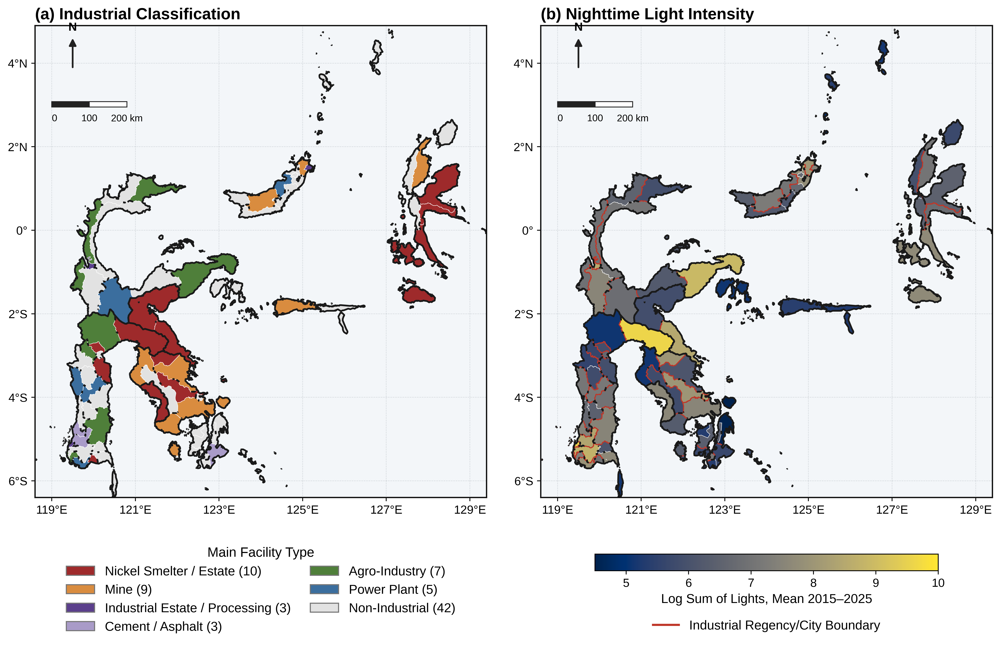

In [12]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

MAP_STYLE = {"font.family": "sans-serif", "font.sans-serif": ["Liberation Sans", "Arial", "DejaVu Sans"],
             "axes.grid": False, "axes.spines.top": True, "axes.spines.right": True}
MAP_BG = "#F3F6F9"

def format_map(ax):
    ax.set_xlim(118.6, 129.4); ax.set_ylim(-6.4, 4.9)
    ax.set_facecolor(MAP_BG)
    ax.set_xticks(range(119, 130, 2)); ax.set_yticks(range(-6, 5, 2))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}°E"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "0°" if v == 0 else f"{abs(v):.0f}°{'N' if v > 0 else 'S'}"))
    ax.grid(True, color="#B8BEC4", linestyle=":", linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(""); ax.set_ylabel("")
    for s in ax.spines.values():
        s.set_linewidth(1.2); s.set_color("#111111")
    ax.annotate("", xy=(119.5, 4.65), xytext=(119.5, 3.85),
                arrowprops=dict(arrowstyle="-|>", color="#222222", lw=1.6, mutation_scale=14))
    ax.text(119.5, 4.72, "N", ha="center", va="bottom", fontsize=11, fontweight="bold")
    km = 1 / 111.32
    ax.add_patch(plt.Rectangle((119.0, 2.95), 100 * km, 0.13, facecolor="#222222", edgecolor="#222222", lw=0.8))
    ax.add_patch(plt.Rectangle((119.0 + 100 * km, 2.95), 100 * km, 0.13, facecolor="white", edgecolor="#222222", lw=0.8))
    for d, lab in [(0, "0"), (100, "100"), (200, "200 km")]:
        ax.text(119.0 + d * km, 2.78, lab, ha="center" if d else "left", va="top", fontsize=9)

facilities = pd.read_csv(find_file("industrial_facilities"))
TYPE_GROUP = {"NS": "Nickel Smelter / Estate", "NE": "Nickel Smelter / Estate", "MN": "Mine",
              "IE": "Industrial Estate / Processing", "PR": "Industrial Estate / Processing",
              "CM": "Cement / Asphalt", "AS": "Cement / Asphalt", "AG": "Agro-Industry", "PP": "Power Plant"}
GROUP_COLORS = {"Nickel Smelter / Estate": "#9E2A2B", "Mine": "#D98C3F", "Industrial Estate / Processing": "#5B3F8C",
                "Cement / Asphalt": "#A99BC8", "Agro-Industry": "#4F7F3A", "Power Plant": "#3B6E9E",
                "Non-Industrial": "#E2E2E2"}
facility_group = facilities.set_index("regency")["type"].map(TYPE_GROUP)
assert set(facility_group.index) == set(df.loc[df["industrial_dummy"] == 1, "regency"])

gmap = gdf_bounds.copy()
gmap["group"] = gmap["regency"].map(facility_group).fillna("Non-Industrial")
gmap["mean_log_sol"] = gmap["regency"].map(df.groupby("regency")["viirs_mean_radiance"].mean())
gmap["industrial"] = gmap["regency"].map(df.groupby("regency")["industrial_dummy"].first())
provinces = gmap.dissolve(by="province_geo")
counts = gmap.loc[gmap["industrial"].notna(), "group"].value_counts()

with plt.rc_context(MAP_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(16, 10.5))
    ax = axes[0]
    for grp, col in GROUP_COLORS.items():
        sel = gmap[gmap["group"] == grp]
        if len(sel):
            sel.plot(ax=ax, color=col, edgecolor="white", linewidth=0.4)
    provinces.boundary.plot(ax=ax, color="#1A1A1A", linewidth=1.6)
    format_map(ax)
    ax.set_title("(a) Industrial Classification", loc="left", fontsize=15, fontweight="bold")
    order = ["Nickel Smelter / Estate", "Mine", "Industrial Estate / Processing", "Cement / Asphalt",
             "Agro-Industry", "Power Plant", "Non-Industrial"]
    handles = [Patch(facecolor=GROUP_COLORS[g], edgecolor="#777777", label=f"{g} ({counts.get(g, 0)})") for g in order]
    ax.legend(handles=handles, title="Main Facility Type", loc="upper center", bbox_to_anchor=(0.5, -0.08),
              ncol=2, frameon=False, fontsize=12, title_fontsize=12.5, handlelength=2.2, columnspacing=1.5)

    ax = axes[1]
    gmap.plot(ax=ax, column="mean_log_sol", cmap="cividis", vmin=4.5, vmax=10, edgecolor="white", linewidth=0.4)
    gmap[gmap["industrial"] == 1].boundary.plot(ax=ax, color="#BF3729", linewidth=1.0)
    provinces.boundary.plot(ax=ax, color="#1A1A1A", linewidth=1.6)
    format_map(ax)
    ax.set_title("(b) Nighttime Light Intensity", loc="left", fontsize=15, fontweight="bold")
    sm = plt.cm.ScalarMappable(cmap="cividis", norm=plt.Normalize(4.5, 10))
    cax = ax.inset_axes([0.12, -0.155, 0.76, 0.035])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_label("Log Sum of Lights, Mean 2015–2025", fontsize=12); cb.ax.tick_params(labelsize=11)
    ax.legend(handles=[Line2D([0], [0], color="#BF3729", lw=2, label="Industrial Regency/City Boundary")],
              loc="upper center", bbox_to_anchor=(0.5, -0.235), frameon=False, fontsize=12)
    fig.subplots_adjust(wspace=0.12, bottom=0.2)
    save_figure(fig, "Figure_1")
    plt.show()

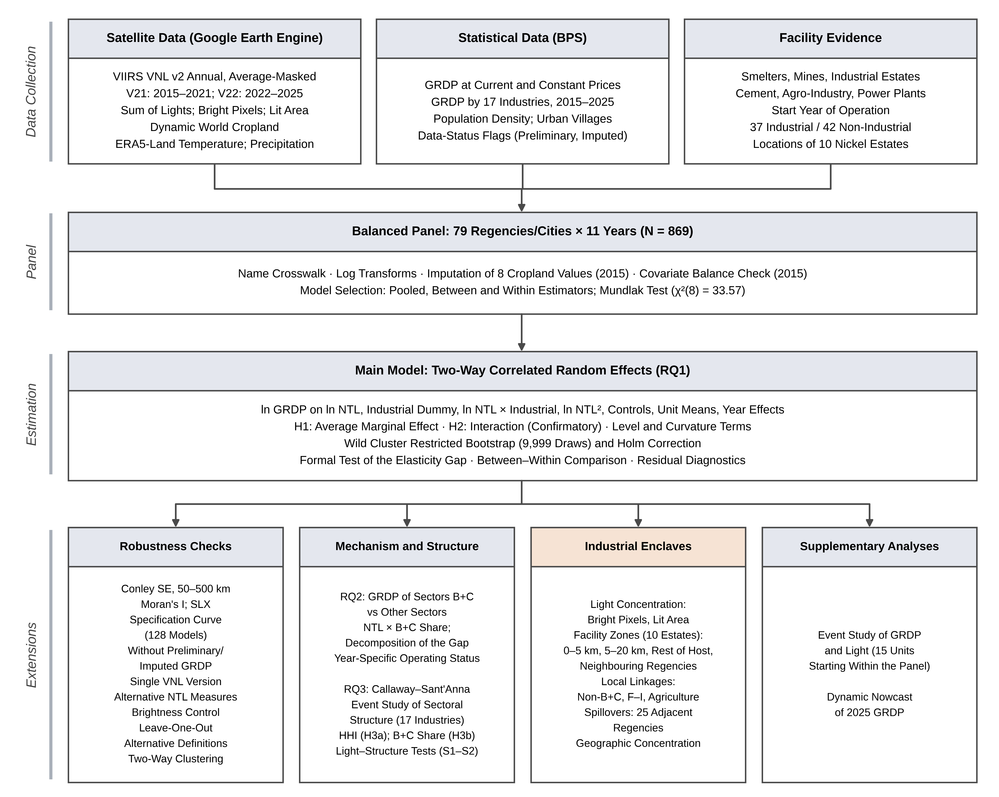

In [13]:
BOX_HEAD = "#E4E7EE"
EDGE = "#4A4A4A"
NEW_HEAD = "#F6E3D4"

def box(ax, x, y, w, h, title, lines, head_h=0.05, fs=11.2, head=BOX_HEAD):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor="white", edgecolor=EDGE, lw=1.4))
    ax.add_patch(plt.Rectangle((x, y + h - head_h), w, head_h, facecolor=head, edgecolor=EDGE, lw=1.4))
    ax.text(x + w / 2, y + h - head_h / 2, title, ha="center", va="center", fontsize=fs + 1, fontweight="bold")
    ax.text(x + w / 2, y + (h - head_h) / 2, "\n".join(lines), ha="center", va="center", fontsize=fs, linespacing=1.7)

def arrow(ax, x0, y0, x1, y1, head=True):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>" if head else "-", color=EDGE, lw=1.6, mutation_scale=14, shrinkA=0, shrinkB=0))

with plt.rc_context({"font.family": "sans-serif", "font.sans-serif": ["Liberation Sans", "Arial", "DejaVu Sans"]}):
    fig, ax = plt.subplots(figsize=(17, 13.6))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    xs, w = [0.062, 0.375, 0.688], 0.297
    box(ax, xs[0], 0.800, w, 0.185, "Satellite Data (Google Earth Engine)",
        ["VIIRS VNL v2 Annual, Average-Masked", "V21: 2015–2021; V22: 2022–2025", "Sum of Lights; Bright Pixels; Lit Area",
         "Dynamic World Cropland", "ERA5-Land Temperature; Precipitation"])
    box(ax, xs[1], 0.800, w, 0.185, "Statistical Data (BPS)",
        ["GRDP at Current and Constant Prices", "GRDP by 17 Industries, 2015–2025",
         "Population Density; Urban Villages", "Data-Status Flags (Preliminary, Imputed)"])
    box(ax, xs[2], 0.800, w, 0.185, "Facility Evidence",
        ["Smelters, Mines, Industrial Estates", "Cement, Agro-Industry, Power Plants", "Start Year of Operation",
         "37 Industrial / 42 Non-Industrial", "Locations of 10 Nickel Estates"])
    for x in xs:
        arrow(ax, x + w / 2, 0.800, x + w / 2, 0.768, head=False)
    arrow(ax, xs[0] + w / 2, 0.768, xs[2] + w / 2, 0.768, head=False)
    arrow(ax, 0.5225, 0.768, 0.5225, 0.738)
    box(ax, 0.062, 0.608, 0.923, 0.130, "Balanced Panel: 79 Regencies/Cities × 11 Years (N = 869)",
        ["Name Crosswalk · Log Transforms · Imputation of 8 Cropland Values (2015) · Covariate Balance Check (2015)",
         "Model Selection: Pooled, Between and Within Estimators; Mundlak Test (χ²(8) = 33.57)"])
    arrow(ax, 0.5225, 0.608, 0.5225, 0.560)
    box(ax, 0.062, 0.395, 0.923, 0.165, "Main Model: Two-Way Correlated Random Effects (RQ1)",
        ["ln GRDP on ln NTL, Industrial Dummy, ln NTL × Industrial, ln NTL², Controls, Unit Means, Year Effects",
         "H1: Average Marginal Effect · H2: Interaction (Confirmatory) · Level and Curvature Terms",
         "Wild Cluster Restricted Bootstrap (9,999 Draws) and Holm Correction",
         "Formal Test of the Elasticity Gap · Between–Within Comparison · Residual Diagnostics"])
    arrow(ax, 0.5225, 0.395, 0.5225, 0.365, head=False)
    xb, wb = [0.062, 0.297, 0.532, 0.767], 0.218
    arrow(ax, xb[0] + wb / 2, 0.365, xb[3] + wb / 2, 0.365, head=False)
    for x in xb:
        arrow(ax, x + wb / 2, 0.365, x + wb / 2, 0.335)
    box(ax, xb[0], 0.009, wb, 0.326, "Robustness Checks",
        ["Conley SE, 50–500 km", "Moran's I; SLX", "Specification Curve", "(128 Models)", "Without Preliminary/", "Imputed GRDP",
         "Single VNL Version", "Alternative NTL Measures", "Brightness Control", "Leave-One-Out", "Alternative Definitions", "Two-Way Clustering"], fs=10.3)
    box(ax, xb[1], 0.009, wb, 0.326, "Mechanism and Structure",
        ["RQ2: GRDP of Sectors B+C", "vs Other Sectors", "NTL × B+C Share;", "Decomposition of the Gap",
         "Year-Specific Operating Status", "", "RQ3: Callaway–Sant'Anna", "Event Study of Sectoral", "Structure (17 Industries)",
         "HHI (H3a); B+C Share (H3b)", "Light–Structure Tests (S1–S2)"], fs=10.3)
    box(ax, xb[2], 0.009, wb, 0.326, "Industrial Enclaves",
        ["Light Concentration:", "Bright Pixels, Lit Area", "Facility Zones (10 Estates):", "0–5 km, 5–20 km, Rest of Host,",
         "Neighbouring Regencies", "Local Linkages:", "Non-B+C, F–I, Agriculture", "Spillovers: 25 Adjacent", "Regencies",
         "Geographic Concentration"], fs=10.3, head=NEW_HEAD)
    box(ax, xb[3], 0.009, wb, 0.326, "Supplementary Analyses",
        ["Event Study of GRDP", "and Light (15 Units", "Starting Within the Panel)", "",
         "Dynamic Nowcast", "of 2025 GRDP"], fs=10.3)
    for y0, y1, lab in [(0.805, 0.98, "Data Collection"), (0.615, 0.735, "Panel"), (0.405, 0.555, "Estimation"),
                        (0.015, 0.33, "Extensions")]:
        ax.plot([0.044, 0.044], [y0, y1], color="#A9B0B9", lw=3)
        ax.text(0.025, (y0 + y1) / 2, lab, rotation=90, ha="center", va="center", fontsize=13, style="italic", color="#444444")
    save_figure(fig, "Figure_2")
    plt.show()

### 6b. Placement of industrial estates

In [14]:
df_2015 = df[df["year"] == 2015].copy()

BALANCE_COVARIATES = {
    "density_raw": "Population density (people/km2)",
    "crops_frac_mean": "Cropland fraction",
    "precip_raw": "Annual precipitation (mm)",
    "tmin_mean_C": "Mean minimum temperature (C)",
    "tmax_mean_C": "Mean maximum temperature (C)",
    "pct_urban": "Urban villages (%)",
}

balance_results = []
for columns_, label in BALANCE_COVARIATES.items():
    group1 = df_2015.loc[df_2015["industrial_dummy"] == 1, columns_].dropna()
    group0 = df_2015.loc[df_2015["industrial_dummy"] == 0, columns_].dropna()
    t_stat, p_ttest = scipy_stats.ttest_ind(group1, group0, equal_var=False)
    u_stat, p_mwu = scipy_stats.mannwhitneyu(group1, group0, alternative="two-sided")
    balance_results.append(dict(
        variable=label, mean_industrial=group1.mean(), mean_non_industrial=group0.mean(),
        p_value_ttest=p_ttest, p_value_mannwhitney=p_mwu,
        balanced_5pct=(p_ttest >= 0.05) and (p_mwu >= 0.05),
    ))

table_balance = pd.DataFrame(balance_results)
print("=== Covariate balance, 2015 (industrial vs non-industrial) ===")
print(table_balance.to_string(index=False))

n_unbalanced = (~table_balance["balanced_5pct"]).sum()
if n_unbalanced == 0:
    print("\n-> All covariates BALANCED (p >= 0.05, t-test and Mann-Whitney) -- "
          "no strong evidence that the two groups differ in baseline characteristics "
          "other than their industrial status.")
else:
    unbalanced = table_balance.loc[~table_balance["balanced_5pct"], "variable"].tolist()
    print(f"\n-> {n_unbalanced} covariates NOT balanced (p < 0.05 in either test): "
          f"{unbalanced}. This does not invalidate the model (these covariates are "
          f"controlled in all specifications), but it means the two groups "
          f"differ structurally from the start of the panel -- a stronger reason "
          f"to control for them explicitly (as done), and to "
          f"to read H2/H3 cautiously as within-model associations, not claims "
          f"purely causal.")

=== Covariate balance, 2015 (industrial vs non-industrial) ===
                       variable  mean_industrial  mean_non_industrial  p_value_ttest  p_value_mannwhitney  balanced_5pct
Population density (people/km2)       370.728108           375.681667       0.983665             0.058582           True
              Cropland fraction         0.088967             0.072870       0.132863             0.095855           True
      Annual precipitation (mm)      2459.795384          2184.396877       0.069828             0.074556           True
   Mean minimum temperature (C)        21.952322            22.773189       0.067972             0.066905           True
   Mean maximum temperature (C)        27.739705            27.728145       0.966926             0.572127           True
             Urban villages (%)        25.968378            32.459762       0.252664             0.539183           True

-> All covariates BALANCED (p >= 0.05, t-test and Mann-Whitney) -- no strong evidence tha

## 7. Baseline models: pooled OLS, fixed effects and random effects

In [15]:
panel_idx = df.set_index(["regency", "year"]).sort_index()

BASE_REGRESSORS = ["viirs_mean_radiance", "viirs2", "industrial_dummy",
                    "viirs_x_industrial", "pop_density_per_km2",
                    "crops_frac_mean", "precip_annual_mm", "tmin_mean_C",
                    "tmax_mean_C", "pct_urban"]

def fit_pooled(data, y_col, regs):
    X = data[regs].assign(const=1.0)
    return PooledOLS(data[y_col], X).fit(cov_type="clustered", cluster_entity=True)

def fit_fe(data, y_col, regs, entity=True, time=True):
    X = data[regs].assign(const=1.0)
    return PanelOLS(data[y_col], X, entity_effects=entity, time_effects=time,
                     drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)

def fit_re(data, y_col, regs):
    X = data[regs].assign(const=1.0)
    return RandomEffects(data[y_col], X).fit(cov_type="clustered", cluster_entity=True)

data_cc = panel_idx.dropna(subset=["log_grdp_current"] + BASE_REGRESSORS)

res_pooled = fit_pooled(data_cc, "log_grdp_current", BASE_REGRESSORS)
res_fe     = fit_fe(data_cc, "log_grdp_current", BASE_REGRESSORS)
res_re     = fit_re(data_cc, "log_grdp_current", BASE_REGRESSORS)

print(f"N observations (complete case, rows with NaN in any regressor dropped): {len(data_cc)}")
print("\n--- Pooled OLS ---");  print(res_pooled.params)
print("\n--- Fixed effects (pct_urban dropped automatically, time-invariant -> absorbed by FE) ---")
print(res_fe.params)
print("\n--- Random Effects ---"); print(res_re.params)

N observations (complete case, rows with NaN in any regressor dropped): 869

--- Pooled OLS ---
viirs_mean_radiance   -0.228743
viirs2                 0.055991
industrial_dummy       0.610785
viirs_x_industrial    -0.045998
pop_density_per_km2    0.276410
crops_frac_mean        0.442890
precip_annual_mm       0.098174
tmin_mean_C           -0.053625
tmax_mean_C            0.012774
pct_urban             -0.006613
const                  6.715344
Name: parameter, dtype: float64

--- Fixed effects (pct_urban dropped automatically, time-invariant -> absorbed by FE) ---
viirs_mean_radiance   -0.478546
viirs2                 0.050124
viirs_x_industrial     0.101676
pop_density_per_km2    0.004818
crops_frac_mean       -0.388356
precip_annual_mm       0.086244
tmin_mean_C           -0.038316
tmax_mean_C            0.042930
const                  8.551504
Name: parameter, dtype: float64

--- Random Effects ---
viirs_mean_radiance   -0.359561
viirs2                 0.067888
industrial_dummy     

## 8. Mundlak test

In [16]:
TIME_VARYING = ["viirs_mean_radiance", "viirs2", "viirs_x_industrial",
                 "pop_density_per_km2",
                 "crops_frac_mean", "precip_annual_mm", "tmin_mean_C", "tmax_mean_C"]

def add_group_means(data, cols):
    data = data.copy()
    means = data.groupby(level=0)[cols].transform("mean")
    means.columns = [f"{c}_bar" for c in cols]
    return pd.concat([data, means], axis=1)

data_cre = add_group_means(data_cc, TIME_VARYING)
MEAN_COLS = [f"{c}_bar" for c in TIME_VARYING]

X_cre = data_cre[BASE_REGRESSORS + MEAN_COLS].assign(const=1.0)
res_cre_test = RandomEffects(data_cre["log_grdp_current"], X_cre).fit(
    cov_type="clustered", cluster_entity=True)

wald = res_cre_test.wald_test(formula=" = ".join(MEAN_COLS) + " = 0" if len(MEAN_COLS)==1
                               else ", ".join(f"{c}=0" for c in MEAN_COLS))
print(wald)

alpha = 0.05
if wald.pval < alpha:
    decision = "FE (Fixed Effects)"
    reason = (f"Mundlak test p-value = {wald.pval:.4f} < {alpha} -> x_bar jointly significant "
              "-> unobserved heterogeneity correlated with regressors -> RE biased, FE preferred. "
              "BUT because FE cannot estimate industrial_dummy and pct_urban (time-invariant), "
              "the CRE model (RE + x_bar) above is used as a statistically valid compromise.")
else:
    decision = "RE (Random Effects) / CRE"
    reason = (f"Mundlak test p-value = {wald.pval:.4f} >= {alpha} -> x_bar NOT jointly significant "
              "-> no strong evidence of heterogeneity-regressor correlation -> RE consistent and efficient.")

print(f"\nAUTOMATIC DECISION: {decision}")
print(reason)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 33.5685
P-value: 0.0000
Distributed: chi2(8)

AUTOMATIC DECISION: FE (Fixed Effects)
Mundlak test p-value = 0.0000 < 0.05 -> x_bar jointly significant -> unobserved heterogeneity correlated with regressors -> RE biased, FE preferred. BUT because FE cannot estimate industrial_dummy and pct_urban (time-invariant), the CRE model (RE + x_bar) above is used as a statistically valid compromise.


## 8b. Between estimator and Hausman test

In [17]:
BETWEEN_REGRESSORS = ["viirs_mean_radiance", "viirs2", "pop_density_per_km2",
                       "crops_frac_mean"]

X_between = data_cc[BETWEEN_REGRESSORS].assign(const=1.0)
res_between = BetweenOLS(data_cc["log_grdp_current"], X_between).fit(
    cov_type="robust")
print("--- Between estimator (regency means) ---")
print(res_between.summary)

--- Between estimator (regency means) ---
                         BetweenOLS Estimation Summary                          
Dep. Variable:       log_grdp_current   R-squared:                        0.6631
Estimator:                 BetweenOLS   R-squared (Between):              0.6631
No. Observations:                  79   R-squared (Within):               0.6861
Date:                Thu, Nov 12 2026   R-squared (Overall):              0.6656
Time:                        17:51:33   Log-likelihood                   -61.499
Cov. Estimator:                Robust                                           
                                        F-statistic:                      36.407
Entities:                          79   P-value                           0.0000
Avg Obs:                       11.000   Distribution:                    F(4,74)
Min Obs:                       11.000                                           
Max Obs:                       11.000   F-statistic (robust):      

### Between estimator with the industrial interaction

In [18]:
BETWEEN_REGRESSORS_H3 = ["viirs_mean_radiance", "industrial_dummy", "viirs_x_industrial",
                          "pop_density_per_km2", "crops_frac_mean"]
X_between_h3 = data_cc[BETWEEN_REGRESSORS_H3].assign(const=1.0)
res_between_h3 = BetweenOLS(data_cc["log_grdp_current"], X_between_h3).fit(cov_type="robust")
print("--- Between estimator + industrial interaction (cross-sectional, H3 test) ---")
print(res_between_h3.summary)

--- Between estimator + industrial interaction (cross-sectional, H3 test) ---
                         BetweenOLS Estimation Summary                          
Dep. Variable:       log_grdp_current   R-squared:                        0.6924
Estimator:                 BetweenOLS   R-squared (Between):              0.6924
No. Observations:                  79   R-squared (Within):               0.6399
Date:                Thu, Nov 12 2026   R-squared (Overall):              0.6867
Time:                        17:51:34   Log-likelihood                   -57.899
Cov. Estimator:                Robust                                           
                                        F-statistic:                      32.866
Entities:                          79   P-value                           0.0000
Avg Obs:                       11.000   Distribution:                    F(5,73)
Min Obs:                       11.000                                           
Max Obs:                       

In [19]:
vi = "viirs_x_industrial"
table_between_within = pd.DataFrame({
    "variation_source": ["Between (cross-sectional, across regencies/cities)",
                        "Within/FE (over time within regencies/cities)"],
    "coefficient": [res_between_h3.params.get(vi, np.nan), res_fe.params.get(vi, np.nan)],
    "std_error": [res_between_h3.std_errors.get(vi, np.nan), res_fe.std_errors.get(vi, np.nan)],
    "p_value": [res_between_h3.pvalues.get(vi, np.nan), res_fe.pvalues.get(vi, np.nan)],
})
table_between_within["significant_5%"] = table_between_within["p_value"] < 0.05
print("=== NTL x industrial elasticity (viirs_x_industrial): between vs within ===")
print(table_between_within.to_string(index=False))

both_significant = table_between_within["significant_5%"].all()
either_significant = table_between_within["significant_5%"].any()
if both_significant:
    print("\n-> The NTL elasticity differs between industrial and non-industrial regencies/cities, BOTH "
          "cross-sectional AND over time.")
elif either_significant:
    side = table_between_within.loc[table_between_within["significant_5%"], "variation_source"].iloc[0]
    print(f"\n-> Elasticity difference detected only on the side: {side}. "
          "The other side is not statistically significant at 5%.")
else:
    print("\n-> No significant evidence (5%) on either side (between or within) "
          "that the NTL elasticity differs between industrial and non-industrial regencies/cities.")

=== NTL x industrial elasticity (viirs_x_industrial): between vs within ===
                                  variation_source  coefficient  std_error  p_value  significant_5%
Between (cross-sectional, across regencies/cities)    -0.020390   0.119569 0.865064           False
     Within/FE (over time within regencies/cities)     0.101676   0.040500 0.012260            True

-> Elasticity difference detected only on the side: Within/FE (over time within regencies/cities). The other side is not statistically significant at 5%.


In [20]:
def stars(p):
    if p < 0.01: return "***"
    if p < 0.05: return "**"
    if p < 0.10: return "*"
    return ""

def model_cols(res, all_vars):
    b, se, p = res.params, res.std_errors, res.pvalues
    out = {}
    for v in all_vars:
        if v in b.index:
            out[v] = f"{b[v]:.4f}{stars(p[v])}\n({se[v]:.4f})"
        else:
            out[v] = "-"
    out["N"] = int(res.nobs)
    out["R2"] = f"{res.rsquared:.3f}"
    return out

all_vars_t2 = ["viirs_mean_radiance", "viirs2", "industrial_dummy", "viirs_x_industrial",
                "pop_density_per_km2", "crops_frac_mean", "precip_annual_mm",
                "tmin_mean_C", "tmax_mean_C", "pct_urban", "const"]

table2 = pd.DataFrame({
    "Pooled OLS": model_cols(res_pooled, all_vars_t2),
    "Between": model_cols(res_between, all_vars_t2),
    "Within (FE)": model_cols(res_fe, all_vars_t2),
})
print("Table 2. Pooled, Between, and Within Estimates of log(PDRB)-NTL Elasticities")
print("(standard errors in parentheses; *** p<0.01, ** p<0.05, * p<0.10)\n")
table2

Table 2. Pooled, Between, and Within Estimates of log(PDRB)-NTL Elasticities
(standard errors in parentheses; *** p<0.01, ** p<0.05, * p<0.10)



,Pooled OLS,Between,Within (FE)
viirs_mean_radiance,-0.2287\n(0.4095),-0.3523\n(0.6347),-0.4785***\n(0.1558)
viirs2,0.0560*\n(0.0325),0.0651\n(0.0472),0.0501***\n(0.0164)
industrial_dummy,0.6108\n(0.7073),-,-
viirs_x_industrial,-0.0460\n(0.1034),-,0.1017**\n(0.0405)
pop_density_per_km2,0.2764***\n(0.0636),0.1171*\n(0.0628),0.0048\n(0.0166)
crops_frac_mean,0.4429\n(1.9041),3.6177\n(2.4715),-0.3884\n(0.3968)
precip_annual_mm,0.0982\n(0.1388),-,0.0862**\n(0.0411)
tmin_mean_C,-0.0536\n(0.0378),-,-0.0383\n(0.0560)
tmax_mean_C,0.0128\n(0.0656),-,0.0429\n(0.0272)
pct_urban,-0.0066*\n(0.0034),-,-


In [21]:
HAUSMAN_REGRESSORS = ["viirs_mean_radiance", "viirs2", "pop_density_per_km2",
                       "crops_frac_mean", "precip_annual_mm", "tmin_mean_C", "tmax_mean_C"]

res_fe_h = fit_fe(data_cc, "log_grdp_current", HAUSMAN_REGRESSORS)
res_re_h = fit_re(data_cc, "log_grdp_current", HAUSMAN_REGRESSORS)

common = res_fe_h.params.index.intersection(res_re_h.params.index)
b_fe = res_fe_h.params[common].values
b_re = res_re_h.params[common].values
V_fe = res_fe_h.cov.loc[common, common].values
V_re = res_re_h.cov.loc[common, common].values

diff = b_fe - b_re
V_diff = V_fe - V_re
try:
    chi2_stat = float(diff.T @ np.linalg.pinv(V_diff) @ diff)
    dof = len(common)
    from scipy import stats as sstats
    p_hausman = 1 - sstats.chi2.cdf(chi2_stat, dof)
    table_hausman = pd.DataFrame({"b_FE": b_fe, "b_RE": b_re, "difference": diff}, index=common)
    print(table_hausman)
    print(f"\nChi2({dof}) = {chi2_stat:.4f}, p-value = {p_hausman:.4f}")
    if p_hausman < 0.05:
        print("-> Reject H0: FE consistent, RE biased -- in line with the Mundlak test (Section 8).")
    else:
        print("-> Fail to reject H0: RE consistent and efficient.")
except np.linalg.LinAlgError:
    print("V_diff not positive definite (common in small samples) -- use the "
          "Mundlak test (Section 8) as the main reference, consistent with the same limitation "
          "(V_b-V_B is not positive definite).")

                         b_FE      b_RE  difference
viirs_mean_radiance -0.465911 -0.361775   -0.104136
viirs2               0.056577  0.064373   -0.007795
pop_density_per_km2  0.011201  0.082229   -0.071028
crops_frac_mean     -0.649521 -2.198830    1.549309
precip_annual_mm     0.085797  0.220092   -0.134295
tmin_mean_C         -0.045494 -0.025330   -0.020164
tmax_mean_C          0.039613  0.094940   -0.055326
const                8.750858  4.392458    4.358400

Chi2(8) = -6.3100, p-value = 1.0000
-> Fail to reject H0: RE consistent and efficient.


## 9. Specification comparison and final specification

In [22]:
CANDIDATE_SPECS = {
    "linear_no_urban":     dict(use_quad=False, use_urban=False),
    "linear_with_urban":   dict(use_quad=False, use_urban=True),
    "quadratic_no_urban":  dict(use_quad=True,  use_urban=False),
    "quadratic_with_urban":dict(use_quad=True,  use_urban=True),
}

CORE_CONTROLS = ["pop_density_per_km2", "crops_frac_mean",
                  "precip_annual_mm", "tmin_mean_C", "tmax_mean_C"]

def build_design(data, use_quad, use_urban):
    regs = ["viirs_mean_radiance", "industrial_dummy", "viirs_x_industrial"] + CORE_CONTROLS
    if use_quad:
        regs = regs + ["viirs2"]
    if use_urban:
        regs = regs + ["pct_urban"]
    X = pd.get_dummies(data[regs + ["province", "year"]],
                        columns=["province", "year"], drop_first=True)
    return X.astype(float), data["log_grdp_current"].astype(float)

groups = data_cc.reset_index()["regency"]

### 9a. Number of folds for GroupKFold

In [23]:
K_CANDIDATES = [3, 4, 5, 6, 7, 8, 10]

X_probe, y_probe = build_design(data_cc.reset_index(), use_quad=True, use_urban=True)

k_results = []
for k in K_CANDIDATES:
    gkf_k = GroupKFold(n_splits=k)
    rmses_k = []
    for train_idx, test_idx in gkf_k.split(X_probe, y_probe, groups=groups):
        model_k = LinearRegression().fit(X_probe.iloc[train_idx], y_probe.iloc[train_idx])
        pred_k = model_k.predict(X_probe.iloc[test_idx])
        rmses_k.append(mean_squared_error(y_probe.iloc[test_idx], pred_k) ** 0.5)
    rmse_mean_k, rmse_std_k = np.mean(rmses_k), np.std(rmses_k)
    k_results.append(dict(K=k, rmse_mean=rmse_mean_k, rmse_std=rmse_std_k,
                         coef_variation=rmse_std_k / rmse_mean_k))

table_k = pd.DataFrame(k_results).sort_values("coef_variation").reset_index(drop=True)
print("Comparison of K (sorted from most stable CV):")
print(table_k)

K_OPTIMAL = int(table_k.iloc[0]["K"])
print(f"\nSelected optimal K: K={K_OPTIMAL} (lowest coefficient-of-variation RMSE "
      f"= {table_k.iloc[0]['coef_variation']:.4f}). This K is used throughout the "
      f"notebook -- for the GroupKFold specification search below.")

gkf = GroupKFold(n_splits=K_OPTIMAL)

tuning_results = []
for name, cfg in CANDIDATE_SPECS.items():
    X, y = build_design(data_cc.reset_index(), **cfg)
    rmses = []
    for train_idx, test_idx in gkf.split(X, y, groups=groups):
        model = LinearRegression().fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[test_idx])
        rmses.append(mean_squared_error(y.iloc[test_idx], pred) ** 0.5)
    tuning_results.append(dict(specification=name, cv_rmse_mean=np.mean(rmses), cv_rmse_std=np.std(rmses)))

table_tuning = pd.DataFrame(tuning_results).sort_values("cv_rmse_mean").reset_index(drop=True)
print("Cross-validated RMSE by specification "
      "(diagnostic comparison only, not used to drop variables):")
print(table_tuning)

selected_specification = "quadratic_with_urban"
USE_QUAD = CANDIDATE_SPECS[selected_specification]["use_quad"]
USE_URBAN = CANDIDATE_SPECS[selected_specification]["use_urban"]
print(f"\nFinal specification used: {selected_specification} "
      f"(use_quad={USE_QUAD}, use_urban={USE_URBAN}) -- FIXED (not from "
      f"lowest CV RMSE), so that viirs^2 (H4) and pct_urban are always "
      f"in the final model.")

Comparison of K (sorted from most stable CV):
    K  rmse_mean  rmse_std  coef_variation
0   3   0.517181  0.045499        0.087976
1   5   0.519377  0.069259        0.133350
2   6   0.508906  0.091339        0.179481
3   7   0.517547  0.114402        0.221046
4  10   0.509352  0.125401        0.246198
5   4   0.544392  0.142647        0.262031
6   8   0.509339  0.159896        0.313927

Selected optimal K: K=3 (lowest coefficient-of-variation RMSE = 0.0880). This K is used throughout the notebook -- for the GroupKFold specification search below.


Cross-validated RMSE by specification (diagnostic comparison only, not used to drop variables):
          specification  cv_rmse_mean  cv_rmse_std
0     linear_with_urban      0.506319     0.032226
1       linear_no_urban      0.507759     0.032426
2  quadratic_with_urban      0.517181     0.045499
3    quadratic_no_urban      0.519198     0.046867

Final specification used: quadratic_with_urban (use_quad=True, use_urban=True) -- FIXED (not from lowest CV RMSE), so that viirs^2 (H4) and pct_urban are always in the final model.


## 10. Final model: two-way CRE (Mundlak)

In [24]:
final_regs = ["viirs_mean_radiance", "industrial_dummy", "viirs_x_industrial"] + CORE_CONTROLS
final_time_varying = ["viirs_mean_radiance", "viirs_x_industrial"] + CORE_CONTROLS
if USE_QUAD:
    final_regs = final_regs + ["viirs2"]
    final_time_varying = final_time_varying + ["viirs2"]
if USE_URBAN:
    final_regs = final_regs + ["pct_urban"]

def add_year_dummies(data):
    year = data.index.get_level_values("year")
    dummies = pd.get_dummies(year, prefix="yr", drop_first=True).astype(float)
    dummies.index = data.index
    return pd.concat([data, dummies], axis=1), list(dummies.columns)

data_final = add_group_means(data_cc, final_time_varying)
mean_cols_final = [f"{c}_bar" for c in final_time_varying]
data_final, YEAR_COLS = add_year_dummies(data_final)

FINAL_X_COLS = final_regs + mean_cols_final + YEAR_COLS
ONEWAY_X_COLS = final_regs + mean_cols_final

X_final = data_final[FINAL_X_COLS].assign(const=1.0)
model_final = RandomEffects(data_final["log_grdp_current"], X_final)
res_final = model_final.fit(cov_type="clustered", cluster_entity=True)

res_final_oneway = RandomEffects(
    data_final["log_grdp_current"], data_final[ONEWAY_X_COLS].assign(const=1.0)
).fit(cov_type="clustered", cluster_entity=True)

print(res_final.summary)

                        RandomEffects Estimation Summary                        
Dep. Variable:       log_grdp_current   R-squared:                        0.8433
Estimator:              RandomEffects   R-squared (Between):              0.7298
No. Observations:                 869   R-squared (Within):               0.8488
Date:                Thu, Nov 12 2026   R-squared (Overall):              0.7427
Time:                        17:51:34   Log-likelihood                    552.87
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      161.40
Entities:                          79   P-value                           0.0000
Avg Obs:                       11.000   Distribution:                  F(28,840)
Min Obs:                       11.000                                           
Max Obs:                       11.000   F-statistic (robust):             142.98
                            

In [25]:
summary_final = pd.DataFrame({
    "coefficient": res_final.params,
    "std_error": res_final.std_errors,
    "p_value": res_final.pvalues,
}).loc[[c for c in final_regs if c in res_final.params.index]]
summary_final["significant_5%"] = summary_final["p_value"] < 0.05
summary_final

,coefficient,std_error,p_value,significant_5%
viirs_mean_radiance,-0.478546,0.149351,0.001406,True
industrial_dummy,0.568085,0.910246,0.532731,False
viirs_x_industrial,0.101676,0.038827,0.008985,True
pop_density_per_km2,0.004818,0.015878,0.761616,False
crops_frac_mean,-0.388356,0.380400,0.307589,False
precip_annual_mm,0.086244,0.039389,0.028830,True
tmin_mean_C,-0.038316,0.053666,0.475441,False
tmax_mean_C,0.042930,0.026079,0.100105,False
viirs2,0.050124,0.015722,0.001485,True
pct_urban,-0.006526,0.003907,0.095236,False


## 11. Robustness: GRDP at constant prices

In [26]:
data_final_adhk = data_final.dropna(subset=["log_grdp_constant"])
X_adhk = data_final_adhk[FINAL_X_COLS].assign(const=1.0)
res_adhk = RandomEffects(data_final_adhk["log_grdp_constant"], X_adhk).fit(
    cov_type="clustered", cluster_entity=True)

comparison = pd.DataFrame({
    "GRDP current prices (main)": res_final.params[final_regs],
    "GRDP current prices p-value": res_final.pvalues[final_regs],
    "GRDP constant prices (robustness)": res_adhk.params[final_regs],
    "GRDP constant prices p-value": res_adhk.pvalues[final_regs],
})
comparison

,GRDP current prices (main),GRDP current prices p-value,GRDP constant prices (robustness),GRDP constant prices p-value
viirs_mean_radiance,-0.478546,0.001406,-0.480317,0.000765
industrial_dummy,0.568085,0.532731,0.654329,0.464743
viirs_x_industrial,0.101676,0.008985,0.088686,0.016638
pop_density_per_km2,0.004818,0.761616,0.005520,0.734356
crops_frac_mean,-0.388356,0.307589,-0.444571,0.218137
precip_annual_mm,0.086244,0.028830,0.105652,0.010162
tmin_mean_C,-0.038316,0.475441,-0.026046,0.606049
tmax_mean_C,0.042930,0.100105,0.031513,0.135307
viirs2,0.050124,0.001485,0.050753,0.000894
pct_urban,-0.006526,0.095236,-0.005703,0.137728


## 12. Hypothesis tests

In [27]:
from scipy.stats import norm

def linear_combination(res, weights):
    name = list(weights.keys())
    g = np.array([weights[n] for n in name])
    est = float(g @ res.params[name].values)
    se = float(np.sqrt(g @ res.cov.loc[name, name].values @ g))
    return est, se, 2 * norm.sf(abs(est / se))

def ntl_marginal_effect(res, data):
    v_all = data["viirs_mean_radiance"].mean()
    i_all = data["industrial_dummy"].mean()
    v_non = data.loc[data["industrial_dummy"] == 0, "viirs_mean_radiance"].mean()
    v_ind = data.loc[data["industrial_dummy"] == 1, "viirs_mean_radiance"].mean()
    has_quadratic = "viirs2" in res.params.index
    def weights(v, i):
        b = {"viirs_mean_radiance": 1.0, "viirs_x_industrial": i}
        if has_quadratic:
            b["viirs2"] = 2 * v
        return b
    return {"AME (all regencies/cities)": linear_combination(res, weights(v_all, i_all)),
            "Marginal effect, non-industrial": linear_combination(res, weights(v_non, 0.0)),
            "Marginal effect, industrial": linear_combination(res, weights(v_ind, 1.0))}

def status(est, p, direction=None):
    direction_ok = True if direction is None else ((est > 0) == (direction == "positive"))
    if p < 0.05 and direction_ok:
        return "SUPPORTED (p<0.05)"
    if p < 0.10 and direction_ok:
        return "NOT SUPPORTED at 5% (significant at 10% only)"
    return "NOT SUPPORTED"

rows_hyp = []
for label_model, res in [("Two-way CRE (MAIN)", res_final),
                          ("One-way CRE (comparison)", res_final_oneway)]:
    ame, se_ame, p_ame = ntl_marginal_effect(res, data_final)["AME (all regencies/cities)"]
    test = [("H1", "AME NTL", ame, se_ame, p_ame, "positive")]
    for h, var, direction in [("H2", "industrial_dummy", "positive"),
                         ("H3", "viirs_x_industrial", None),
                         ("H4", "viirs2", None)]:
        test.append((h, var, res.params[var], res.std_errors[var], res.pvalues[var], direction))
    for h, var, est, se, p, direction in test:
        rows_hyp.append(dict(model=label_model, hypothesis=h, quantity=var,
                              estimate_=est, std_error=se, p_value=p,
                              status=status(est, p, direction)))

table_hypotheses = pd.DataFrame(rows_hyp)
print("=== Hypothesis tests, GRDP (regency/city, current prices) ===\n")
for _, r in table_hypotheses.iterrows():
    print(f"[{r['model']:26s}] {r['hypothesis']}  {r['quantity']:18s} "
          f"est={r['estimate_']:+.4f}  SE={r['std_error']:.4f}  p={r['p_value']:.4f}  -> {r['status']}")

print("\nNTL marginal effect by group (main model, two-way CRE):")
for name, (est, se, p) in ntl_marginal_effect(res_final, data_final).items():
    print(f"  {name:35s} est={est:+.4f}  SE={se:.4f}  p={p:.4f}")
print("\nNote: p-values close to 0.05 (e.g. 0.04-0.06) should be read as "
      "weak/marginal evidence, not certainty -- check how consistent the result is in the "
      "specification curve (Section 12c).")

=== Hypothesis tests, GRDP (regency/city, current prices) ===

[Two-way CRE (MAIN)        ] H1  AME NTL            est=+0.2364  SE=0.0860  p=0.0060  -> SUPPORTED (p<0.05)
[Two-way CRE (MAIN)        ] H2  industrial_dummy   est=+0.5681  SE=0.9102  p=0.5327  -> NOT SUPPORTED
[Two-way CRE (MAIN)        ] H3  viirs_x_industrial est=+0.1017  SE=0.0388  p=0.0090  -> SUPPORTED (p<0.05)
[Two-way CRE (MAIN)        ] H4  viirs2             est=+0.0501  SE=0.0157  p=0.0015  -> SUPPORTED (p<0.05)
[One-way CRE (comparison)  ] H1  AME NTL            est=+0.5045  SE=0.0417  p=0.0000  -> SUPPORTED (p<0.05)
[One-way CRE (comparison)  ] H2  industrial_dummy   est=+0.5681  SE=0.9049  p=0.5303  -> NOT SUPPORTED
[One-way CRE (comparison)  ] H3  viirs_x_industrial est=-0.0645  SE=0.0500  p=0.1977  -> NOT SUPPORTED
[One-way CRE (comparison)  ] H4  viirs2             est=+0.0671  SE=0.0132  p=0.0000  -> SUPPORTED (p<0.05)

NTL marginal effect by group (main model, two-way CRE):
  AME (all regencies/cities)   

## 12b. Wild cluster restricted bootstrap

In [28]:
def quasi_demean(y, X, theta):
    ent = y.index.get_level_values(0)
    th = theta["theta"].reindex(ent).values
    ys = y.values - th * y.groupby(level=0).transform("mean").values
    Xs = X.values - th[:, None] * X.groupby(level=0).transform("mean").values
    return ys, Xs, pd.factorize(ent)[0]

def vcov_crv1(Xs, u, clusters, XtXi):
    G = clusters.max() + 1
    N, K = Xs.shape
    score = np.zeros((G, K))
    np.add.at(score, clusters, Xs * u[:, None])
    return (G / (G - 1)) * ((N - 1) / (N - K)) * XtXi @ score.T @ score @ XtXi

def wild_cluster_bootstrap(y, X, theta, g, B=9999, seed=2026):
    ys, Xs, clusters = quasi_demean(y, X, theta)
    XtXi = np.linalg.inv(Xs.T @ Xs)
    b = XtXi @ Xs.T @ ys
    V = vcov_crv1(Xs, ys - Xs @ b, clusters, XtXi)
    t_obs = (g @ b) / np.sqrt(g @ V @ g)
    b_r = b - XtXi @ g * (g @ b) / (g @ XtXi @ g)
    fit_r, u_r = Xs @ b_r, ys - Xs @ b_r
    A = XtXi @ Xs.T
    rng = np.random.default_rng(seed)
    G = clusters.max() + 1
    t_boot = np.empty(B)
    for i in range(B):
        yb = fit_r + u_r * rng.choice([-1.0, 1.0], size=G)[clusters]
        bb = A @ yb
        t_boot[i] = (g @ bb) / np.sqrt(g @ vcov_crv1(Xs, yb - Xs @ bb, clusters, XtXi) @ g)
    return b, t_obs, float(np.mean(np.abs(t_boot) >= abs(t_obs)))

def hypothesis_weights(columns_, data):
    g = {}
    v_all = data["viirs_mean_radiance"].mean(); i_all = data["industrial_dummy"].mean()
    h1 = np.zeros(len(columns_))
    h1[columns_.index("viirs_mean_radiance")] = 1.0
    h1[columns_.index("viirs_x_industrial")] = i_all
    if "viirs2" in columns_:
        h1[columns_.index("viirs2")] = 2 * v_all
    g["H1 (AME NTL)"] = h1
    for h, var in [("H2 (industrial_dummy)", "industrial_dummy"),
                   ("H3 (viirs_x_industrial)", "viirs_x_industrial"),
                   ("H4 (viirs2)", "viirs2")]:
        vec = np.zeros(len(columns_)); vec[columns_.index(var)] = 1.0; g[h] = vec
    return g

rows_wcb = []
for label_model, res, x_cols in [("Two-way CRE (MAIN)", res_final, FINAL_X_COLS),
                                   ("One-way CRE (comparison)", res_final_oneway, ONEWAY_X_COLS)]:
    y_m = data_final["log_grdp_current"]
    X_m = data_final[x_cols].assign(const=1.0)
    ys, Xs, _ = quasi_demean(y_m, X_m, res.theta)
    difference = np.abs(np.linalg.lstsq(Xs, ys, rcond=None)[0] - res.params[X_m.columns].values).max()
    assert difference < 1e-8, f"RE replication by quasi-demeaning failed (difference {difference})"
    for h, g in hypothesis_weights(list(X_m.columns), data_final).items():
        _, t_obs, p_boot = wild_cluster_bootstrap(y_m, X_m, res.theta, g)
        p_asymptotic = 2 * norm.sf(abs(t_obs))
        rows_wcb.append(dict(model=label_model, hypothesis=h, t_stat=t_obs,
                              p_value_crv1=p_asymptotic, p_value_wcr_bootstrap=p_boot,
                              significant_5pct_bootstrap=p_boot < 0.05))

table_wcb = pd.DataFrame(rows_wcb)
print("Wild cluster restricted bootstrap (9,999 replications, Rademacher weights, clusters = regencies/cities)")
print("RE replicated by quasi-demeaning: OK (coefficients identical to the CRE model)\n")
print(table_wcb.round(4).to_string(index=False))
print("\nRead p_value_wcr_bootstrap as the more reliable p-value with 79 clusters. "
      "If it differs from the CRV1 p-value, the bootstrap version is reported in the paper.")

Wild cluster restricted bootstrap (9,999 replications, Rademacher weights, clusters = regencies/cities)
RE replicated by quasi-demeaning: OK (coefficients identical to the CRE model)

                   model              hypothesis  t_stat  p_value_crv1  p_value_wcr_bootstrap  significant_5pct_bootstrap
      Two-way CRE (MAIN)            H1 (AME NTL)  2.7318        0.0063                 0.0023                        True
      Two-way CRE (MAIN)   H2 (industrial_dummy)  0.6205        0.5349                 0.5816                       False
      Two-way CRE (MAIN) H3 (viirs_x_industrial)  2.6036        0.0092                 0.0126                        True
      Two-way CRE (MAIN)             H4 (viirs2)  3.1697        0.0015                 0.0221                        True
One-way CRE (comparison)            H1 (AME NTL) 12.0282        0.0000                 0.0000                        True
One-way CRE (comparison)   H2 (industrial_dummy)  0.6242        0.5325              

## 12c. Specification curve

In [29]:
import itertools

POWER_PLANTS = ["Jeneponto", "Sidenreng Rappang", "Poso"]
OPTIONS = {
    "outcome":    [("log_grdp_current", "GRDP, current prices"), ("log_grdp_constant", "GRDP, constant prices")],
    "definition": [(False, "Industrial: broad (37)"), (True, "Industrial: narrow (34)")],
    "quadratic":  [(True, "With NTL squared"), (False, "Without NTL squared")],
    "urban":      [(True, "With urban share"), (False, "Without urban share")],
    "year_fe":    [(True, "Year effects"), (False, "No year effects")],
    "sample":     [(False, "Sample 2015-2025"), (True, "Excluding 2020-2021")],
    "cluster":    [(False, "SE clustered by regency/city"), (True, "SE two-way clustered")],
}

def estimate_specification(outcome, narrow, quad, urban, year_fe, drop_covid, twoway):
    d = df.copy()
    if narrow:
        d.loc[d["regency"].isin(POWER_PLANTS), "industrial_dummy"] = 0
    if drop_covid:
        d = d[~d["year"].isin([2020, 2021])]
    d["viirs_x_industrial"] = d["viirs_mean_radiance"] * d["industrial_dummy"]
    regs = ["viirs_mean_radiance", "industrial_dummy", "viirs_x_industrial"] + CORE_CONTROLS
    tv = ["viirs_mean_radiance", "viirs_x_industrial"] + CORE_CONTROLS
    if quad:
        regs, tv = regs + ["viirs2"], tv + ["viirs2"]
    if urban:
        regs = regs + ["pct_urban"]
    d = d.set_index(["regency", "year"]).sort_index()
    d = add_group_means(d, tv)
    x_cols = regs + [f"{c}_bar" for c in tv]
    if year_fe:
        d, year_cols = add_year_dummies(d)
        x_cols = x_cols + year_cols
    kw = dict(cov_type="clustered", cluster_entity=True)
    if twoway:
        kw["cluster_time"] = True
    res = RandomEffects(d[outcome], d[x_cols].assign(const=1.0)).fit(**kw)
    return res, d

rows_sc = []
for combo in itertools.product(*[[option for option, _ in v] for v in OPTIONS.values()]):
    outcome, narrow, quad, urban, year_fe, drop_covid, twoway = combo
    res_s, d_s = estimate_specification(*combo)
    ame, se_ame, p_ame = ntl_marginal_effect(res_s, d_s)["AME (all regencies/cities)"]
    h_results = {"H1": (ame, se_ame, p_ame)}
    for h, var in [("H2", "industrial_dummy"), ("H3", "viirs_x_industrial"), ("H4", "viirs2")]:
        if var in res_s.params.index:
            h_results[h] = (res_s.params[var], res_s.std_errors[var], res_s.pvalues[var])
    for h, (est, se, p) in h_results.items():
        rows_sc.append(dict(hypothesis=h, estimate=est, se=se, p_value=p,
                             **dict(zip(OPTIONS.keys(), combo))))

spec_curve = pd.DataFrame(rows_sc)
hypothesis_direction = {"H1": 1, "H2": 1, "H3": None, "H4": None}

sc_summary = (spec_curve.groupby("hypothesis")
                .agg(n_specifications=("estimate", "size"),
                     median_estimate=("estimate", "median"),
                     share_positive=("estimate", lambda s: (s > 0).mean()),
                     share_sig_5pct=("p_value", lambda s: (s < 0.05).mean()),
                     share_sig_10pct=("p_value", lambda s: (s < 0.10).mean()))
                .round(3))
print("Specification curve summary (all specifications, no selection):")
print(sc_summary)

print("\nShare significant at 5% by analytic choice:")
for h in ["H1", "H2", "H3", "H4"]:
    sub = spec_curve[spec_curve["hypothesis"] == h]
    cut = {k: sub.groupby(k)["p_value"].apply(lambda s: round((s < 0.05).mean(), 2)).to_dict()
                for k in OPTIONS}
    print(f"  {h}: {cut}")

Specification curve summary (all specifications, no selection):
            n_specifications  median_estimate  share_positive  share_sig_5pct  share_sig_10pct
hypothesis                                                                                    
H1                       128            0.269           1.000             1.0            1.000
H2                       128            0.288           0.938             0.0            0.000
H3                       128            0.090           0.875             0.5            0.516
H4                        64            0.056           1.000             1.0            1.000

Share significant at 5% by analytic choice:
  H1: {'outcome': {'log_grdp_constant': 1.0, 'log_grdp_current': 1.0}, 'definition': {False: 1.0, True: 1.0}, 'quadratic': {False: 1.0, True: 1.0}, 'urban': {False: 1.0, True: 1.0}, 'year_fe': {False: 1.0, True: 1.0}, 'sample': {False: 1.0, True: 1.0}, 'cluster': {False: 1.0, True: 1.0}}
  H2: {'outcome': {'log_grdp_con

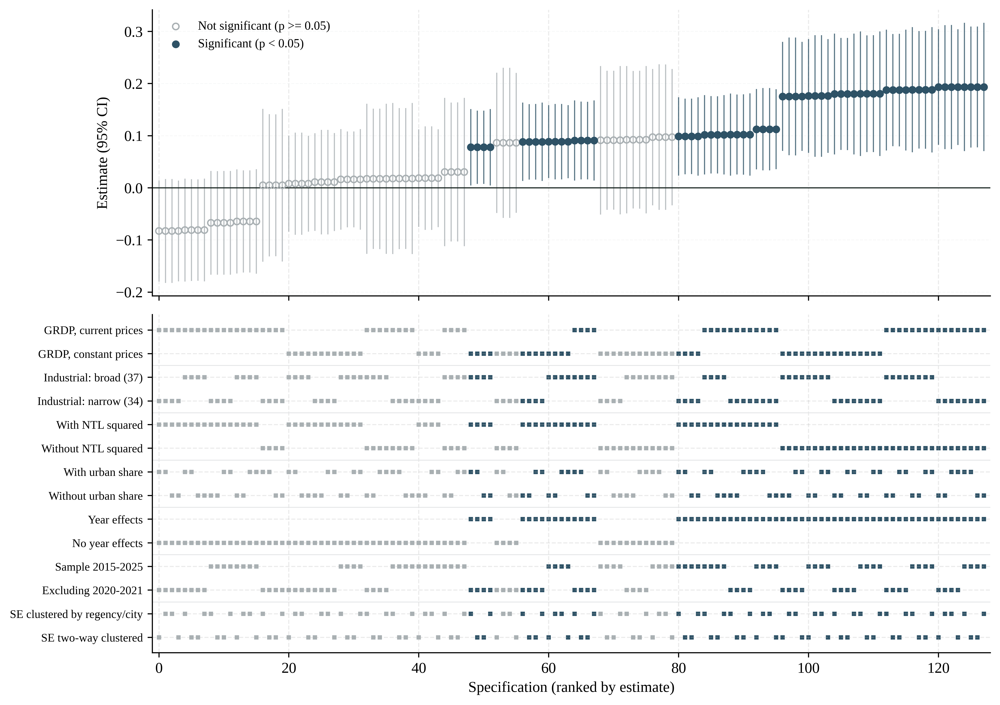

In [30]:
HYPOTHESIS_TITLES = {
    "H1": "H1: Average Marginal Effect of NTL on GRDP",
    "H2": "H2: Industrial-Status Premium in GRDP",
    "H3": "H3: Difference in NTL Elasticity (NTL x Industrial)",
    "H4": "H4: Curvature of the NTL-GRDP Relationship (NTL Squared)",
}
COLOR_NOT_SIGNIF = "#A9B0B3"

def plot_spec_curve(h, figure_number):
    sub = spec_curve[spec_curve["hypothesis"] == h].sort_values("estimate").reset_index(drop=True)
    x = np.arange(len(sub))
    signif = sub["p_value"] < 0.05
    ci = 1.96 * sub["se"]

    rows_option = [(k, option, label) for k, v in OPTIONS.items() for option, label in v]
    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(11, 8.5), sharex=True,
        gridspec_kw={"height_ratios": [2.2, 2.6], "hspace": 0.06})

    for mask, colors, fill, label in [
            (~signif, COLOR_NOT_SIGNIF, "none", "Not significant (p >= 0.05)"),
            (signif, COLOR_NONINDUSTRIAL, COLOR_NONINDUSTRIAL, "Significant (p < 0.05)")]:
        ax_top.errorbar(x[mask], sub["estimate"][mask], yerr=ci[mask], fmt="none",
                        ecolor=colors, elinewidth=0.8, alpha=0.8)
        ax_top.scatter(x[mask], sub["estimate"][mask], s=22, facecolors=fill,
                       edgecolors=colors, linewidths=1.0, label=label, zorder=3)
    ax_top.axhline(0, color=COLOR_NEUTRAL, linewidth=0.8)
    ax_top.set_ylabel("Estimate (95% CI)")
    ax_top.grid(axis="y", color="#E3E5E6", linewidth=0.6)
    ax_top.spines[["top", "right"]].set_visible(False)
    ax_top.legend(loc="upper left", frameon=False, fontsize=9)

    for j, (k, option, label) in enumerate(rows_option):
        active = (sub[k] == option).values
        ax_bot.scatter(x[active], np.full(active.sum(), j), s=10,
                       color=np.where(signif[active], COLOR_NONINDUSTRIAL, COLOR_NOT_SIGNIF),
                       marker="s", linewidths=0)
    ax_bot.set_yticks(range(len(rows_option)))
    ax_bot.set_yticklabels([label for _, _, label in rows_option], fontsize=8.5)
    ax_bot.invert_yaxis()
    for bounds in np.arange(1.5, len(rows_option) - 1, 2):
        ax_bot.axhline(bounds, color="#E3E5E6", linewidth=0.6)
    ax_bot.set_xlabel("Specification (ranked by estimate)")
    ax_bot.spines[["top", "right"]].set_visible(False)
    ax_bot.set_xlim(-1, len(sub))
    fig.tight_layout()
    save_figure(fig, f"Figure_{figure_number}")
    plt.show()

plot_spec_curve("H3", 5)

## 12d. Spatial dependence: Moran's I, Conley SE and SLX model

In [31]:
SPATIAL_OK = HAS_MAP
if not SPATIAL_OK:
    print("Boundary file not uploaded -- Section 12d skipped.")
else:
    UNIT_SP = sorted(data_final.index.get_level_values(0).unique())
    geo_sp = gdf_bounds.set_index("regency").loc[UNIT_SP]
    centroid_sp = (geo_sp.to_crs("+proj=aeqd +lat_0=-1.5 +lon_0=122.5 +units=m")
                   .geometry.centroid.to_crs(4326))
    lat_r, lon_r = np.radians(centroid_sp.y.values), np.radians(centroid_sp.x.values)
    _a = (np.sin((lat_r[:, None] - lat_r[None]) / 2) ** 2 + np.cos(lat_r[:, None]) *
          np.cos(lat_r[None]) * np.sin((lon_r[:, None] - lon_r[None]) / 2) ** 2)
    DIST_KM = 2 * 6371.0 * np.arcsin(np.sqrt(_a))
    n_sp = len(UNIT_SP)

    def w_knn(k):
        W = np.zeros((n_sp, n_sp))
        for i in range(n_sp):
            W[i, np.argsort(DIST_KM[i])[1:k + 1]] = 1.0
        return W / W.sum(1, keepdims=True)

    def w_invdist(cutoff_km):
        W = np.where((DIST_KM > 0) & (DIST_KM <= cutoff_km), 1 / np.maximum(DIST_KM, 1e-9), 0.0)
        rs = W.sum(1, keepdims=True)
        return np.divide(W, rs, out=np.zeros_like(W), where=rs > 0)

    geo_utm = geo_sp.to_crs(32750)
    W_queen = np.zeros((n_sp, n_sp))
    for i in range(n_sp):
        neighbours_ = geo_utm.geometry.intersects(geo_utm.geometry.iloc[i].buffer(1)).values.copy()
        neighbours_[i] = False
        W_queen[i, neighbours_] = 1.0
    n_islands = int((W_queen.sum(1) == 0).sum())
    rs = W_queen.sum(1, keepdims=True)
    W_queen = np.divide(W_queen, rs, out=np.zeros_like(W_queen), where=rs > 0)

    W_MATRICES = {"KNN k=5 (main)": w_knn(5),
                 "Inverse distance <= 200 km": w_invdist(200),
                 "Queen contiguity": W_queen}
    print(f"Distance to nearest neighbour: median {np.median(np.sort(DIST_KM, 1)[:, 1]):.1f} km, "
          f"max {np.sort(DIST_KM, 1)[:, 1].max():.1f} km")
    print(f"Queen contiguity: {n_islands} island regencies/cities without land neighbours "
          f"(excluded from the queen test only)")

Distance to nearest neighbour: median 32.9 km, max 156.5 km
Queen contiguity: 11 island regencies/cities without land neighbours (excluded from the queen test only)


In [32]:
def moran_permutation(z, W, n_perm=9999, seed=2026):
    exists = W.sum(1) > 0
    z = z[exists] - z[exists].mean(); W = W[np.ix_(exists, exists)]
    n, S0 = len(z), W.sum()
    stat = lambda v: n / S0 * (v @ W @ v) / (v @ v)
    I = stat(z)
    rng = np.random.default_rng(seed)
    sim = np.array([stat(rng.permutation(z)) for _ in range(n_perm)])
    p = (1 + np.sum(np.abs(sim - sim.mean()) >= abs(I - sim.mean()))) / (n_perm + 1)
    return I, -1 / (n - 1), p

if SPATIAL_OK:
    X_sp = data_final[FINAL_X_COLS].assign(const=1.0)
    resid_sp = pd.DataFrame(index=data_final.index)
    resid_sp["total"] = data_final["log_grdp_current"].values - X_sp.values @ res_final.params[X_sp.columns].values
    resid_sp["regency_effect"] = resid_sp.groupby(level=0)["total"].transform("mean")
    resid_sp["idiosyncratic"] = resid_sp["total"] - resid_sp["regency_effect"]

    rows_moran = []
    regency_effect = resid_sp.groupby(level=0)["regency_effect"].first().loc[UNIT_SP].values
    for w_name, W in W_MATRICES.items():
        I, EI, p = moran_permutation(regency_effect, W)
        rows_moran.append(dict(W=w_name, residual="Regency/city effect (time-averaged)",
                                year="all", moran_I=I, E_I=EI, p_value=p))
        for t in sorted(data_final.index.get_level_values(1).unique()):
            r_t = resid_sp.xs(t, level=1).loc[UNIT_SP]
            for col_, lab in [("total", "Total residual"), ("idiosyncratic", "Idiosyncratic residual")]:
                I, EI, p = moran_permutation(r_t[col_].values, W, n_perm=1999)
                rows_moran.append(dict(W=w_name, residual=lab, year=t, moran_I=I, E_I=EI, p_value=p))
    table_moran = pd.DataFrame(rows_moran)

    print("(a) Moran's I of regency effects (residuals averaged by regency/city, n=79):")
    print(table_moran[table_moran["year"] == "all"][["W", "moran_I", "E_I", "p_value"]]
          .round(4).to_string(index=False))
    print("\n(b) Moran's I by year (11 years): mean I and number of years significant at 5%:")
    print(table_moran[table_moran["year"] != "all"]
          .groupby(["W", "residual"])
          .agg(mean_I=("moran_I", "mean"), I_min=("moran_I", "min"), I_max=("moran_I", "max"),
               n_years_sig_5pct=("p_value", lambda x: int((x < 0.05).sum())))
          .round(3).to_string())

(a) Moran's I of regency effects (residuals averaged by regency/city, n=79):
                         W  moran_I     E_I  p_value
            KNN k=5 (main)   0.0822 -0.0128   0.1349
Inverse distance <= 200 km   0.0890 -0.0128   0.0864
          Queen contiguity   0.1093 -0.0149   0.1733

(b) Moran's I by year (11 years): mean I and number of years significant at 5%:
                                                   mean_I  I_min  I_max  n_years_sig_5pct
W                          residual                                                      
Inverse distance <= 200 km Idiosyncratic residual   0.027 -0.058  0.143                 2
                           Total residual           0.086  0.024  0.147                 4
KNN k=5 (main)             Idiosyncratic residual   0.023 -0.039  0.119                 1
                           Total residual           0.081  0.011  0.150                 4
Queen contiguity           Idiosyncratic residual   0.071 -0.055  0.218                 2


In [33]:
if SPATIAL_OK:
    y_sp = data_final["log_grdp_current"]
    ys_sp, Xs_sp, clusters_sp = quasi_demean(y_sp, X_sp, res_final.theta)
    XtXi_sp = np.linalg.inv(Xs_sp.T @ Xs_sp)
    b_sp = XtXi_sp @ Xs_sp.T @ ys_sp
    u_sp = ys_sp - Xs_sp @ b_sp
    score_sp = Xs_sp * u_sp[:, None]
    idx_unit = np.array([UNIT_SP.index(k) for k in data_final.index.get_level_values(0)])
    idx_year = data_final.index.get_level_values(1).values
    same_unit = idx_unit[:, None] == idx_unit[None]
    same_year = idx_year[:, None] == idx_year[None]

    def vcov_conley(cutoff_km, mode):
        K = np.clip(1 - DIST_KM / cutoff_km, 0, None)[np.ix_(idx_unit, idx_unit)]
        if mode == "within-year":
            weights = np.where(same_unit, 1.0, np.where(same_year, K, 0.0))
        else:
            weights = np.where(same_unit, 1.0, K)
        return XtXi_sp @ (score_sp.T @ weights @ score_sp) @ XtXi_sp

    V_crv1_sp = vcov_crv1(Xs_sp, u_sp, clusters_sp, XtXi_sp)
    vector_h = hypothesis_weights(list(X_sp.columns), data_final)
    CUTOFFS_KM = [50, 100, 200, 300, 500]
    rows_conley = []
    for h, g in vector_h.items():
        est = g @ b_sp
        se = np.sqrt(g @ V_crv1_sp @ g)
        rows_conley.append(dict(hypothesis=h, SE_type="Cluster by regency/city (CRV1)",
                                 cutoff_km=np.nan, estimate_=est, std_error=se))
        for mode in ["within-year", "all-years"]:
            for c in CUTOFFS_KM:
                var = g @ vcov_conley(c, mode) @ g
                rows_conley.append(dict(hypothesis=h, SE_type=f"Conley {mode}", cutoff_km=c,
                                         estimate_=est, std_error=np.sqrt(var) if var > 0 else np.nan))
    table_conley = pd.DataFrame(rows_conley)
    table_conley["p_value"] = 2 * norm.sf(np.abs(table_conley["estimate_"] / table_conley["std_error"]))
    table_conley["label"] = np.where(table_conley["cutoff_km"].isna(), table_conley["SE_type"],
                                     table_conley["SE_type"] + " " + table_conley["cutoff_km"]
                                     .fillna(0).astype(int).astype(str) + " km")
    print("H1-H4 p-values under different SEs (same point estimates, only SEs change):")
    print(table_conley.pivot(index="label", columns="hypothesis", values="p_value")
          .reindex(table_conley["label"].unique()).round(4).to_string())
    print("\nRange of Conley p-values (all cutoffs and variants):")
    print(table_conley[table_conley["SE_type"].str.startswith("Conley")]
          .groupby("hypothesis")["p_value"].agg(["min", "max"]).round(4).to_string())

H1-H4 p-values under different SEs (same point estimates, only SEs change):
hypothesis                      H1 (AME NTL)  H2 (industrial_dummy)  H3 (viirs_x_industrial)  H4 (viirs2)
label                                                                                                    
Cluster by regency/city (CRV1)        0.0063                 0.5349                   0.0092       0.0015
Conley within-year 50 km              0.0052                 0.5252                   0.0078       0.0012
Conley within-year 100 km             0.0052                 0.5318                   0.0080       0.0012
Conley within-year 200 km             0.0051                 0.5532                   0.0081       0.0012
Conley within-year 300 km             0.0051                 0.5747                   0.0091       0.0010
Conley within-year 500 km             0.0054                 0.5908                   0.0109       0.0009
Conley all-years 50 km                0.0057                 0.5375         

In [34]:
if SPATIAL_OK:
    W_main = W_MATRICES["KNN k=5 (main)"]
    data_slx = data_cc.copy()
    data_slx["W_ntl"] = np.nan
    for t in sorted(data_slx.index.get_level_values(1).unique()):
        v_t = data_slx.xs(t, level=1)["viirs_mean_radiance"].loc[UNIT_SP].values
        data_slx.loc[(UNIT_SP, t), "W_ntl"] = W_main @ v_t
    tv_slx = final_time_varying + ["W_ntl"]
    data_slx = add_group_means(data_slx, tv_slx)
    data_slx, _ = add_year_dummies(data_slx)
    slx_cols = final_regs + ["W_ntl"] + [f"{c}_bar" for c in tv_slx] + YEAR_COLS
    X_slx = data_slx[slx_cols].assign(const=1.0)
    res_slx = RandomEffects(data_slx["log_grdp_current"], X_slx).fit(cov_type="clustered", cluster_entity=True)

    vector_slx = hypothesis_weights(list(X_slx.columns), data_slx)
    g_spill = np.zeros(len(X_slx.columns)); g_spill[list(X_slx.columns).index("W_ntl")] = 1.0
    vector_slx = {"Spillover (W*NTL)": g_spill, **vector_slx}
    rows_slx = []
    for h, g in vector_slx.items():
        b_h, t_h, p_h = wild_cluster_bootstrap(data_slx["log_grdp_current"], X_slx, res_slx.theta, g)
        rows_slx.append(dict(hypothesis=h, estimate_=float(g @ b_h), t_stat=t_h,
                              p_value_crv1=2 * norm.sf(abs(t_h)), p_value_wcr_bootstrap=p_h))
    table_slx = pd.DataFrame(rows_slx)
    print("SLX model (two-way CRE + W*NTL and its Mundlak mean), WCR bootstrap, 9,999 replications:")
    print(table_slx.round(4).to_string(index=False))
    print("\nComparison, main model without W*NTL (Section 12b):")
    print(table_wcb[table_wcb["model"].str.contains("MAIN")][["hypothesis", "t_stat", "p_value_wcr_bootstrap"]]
          .round(4).to_string(index=False))

SLX model (two-way CRE + W*NTL and its Mundlak mean), WCR bootstrap, 9,999 replications:
             hypothesis  estimate_  t_stat  p_value_crv1  p_value_wcr_bootstrap
      Spillover (W*NTL)     0.0075  0.0969        0.9228                 0.9365
           H1 (AME NTL)     0.2348  2.4186        0.0156                 0.0014
  H2 (industrial_dummy)     0.5476  0.6050        0.5452                 0.5921
H3 (viirs_x_industrial)     0.1024  2.6247        0.0087                 0.0110
            H4 (viirs2)     0.0500  3.1113        0.0019                 0.0233

Comparison, main model without W*NTL (Section 12b):
             hypothesis  t_stat  p_value_wcr_bootstrap
           H1 (AME NTL)  2.7318                 0.0023
  H2 (industrial_dummy)  0.6205                 0.5816
H3 (viirs_x_industrial)  2.6036                 0.0126
            H4 (viirs2)  3.1697                 0.0221


## 12e. Sensitivity to preliminary and imputed GRDP

In [35]:
def estimate_subsample(data_sub, y_col):
    d = add_group_means(data_sub.dropna(subset=[y_col]), final_time_varying)
    d, year_col = add_year_dummies(d)
    columns_ = final_regs + [f"{c}_bar" for c in final_time_varying] + year_col
    X = d[columns_].assign(const=1.0)
    res = RandomEffects(d[y_col], X).fit(cov_type="clustered", cluster_entity=True)
    rows = []
    for h, g in hypothesis_weights(list(X.columns), d).items():
        b_h, t_h, p_h = wild_cluster_bootstrap(d[y_col], X, res.theta, g)
        est = float(g @ b_h)
        rows.append(dict(hypothesis=h, estimate_=est, std_error=abs(est / t_h),
                          p_value_crv1=2 * norm.sf(abs(t_h)), p_value_wcr_bootstrap=p_h))
    return pd.DataFrame(rows), len(d)

reg_idx = data_cc.index.get_level_values(0)
yr_idx = data_cc.index.get_level_values(1)
is_sultra_2020 = (data_cc["province"].str.contains("Tenggara").values) & (yr_idx == 2020)
is_imputasi_adhk = (((reg_idx == "Kota Makassar") & (yr_idx == 2020)) |
                    ((reg_idx == "Pinrang") & (yr_idx == 2025)))
assert is_imputasi_adhk.sum() == 2 and is_sultra_2020.sum() == 17

SUBSAMPLES = [
    ("A. Main sample, 2015-2025", "log_grdp_current", np.ones(len(data_cc), bool)),
    ("B. Excl. 2025 (very preliminary)", "log_grdp_current", yr_idx <= 2024),
    ("C. Excl. 2024-2025 (all preliminary)", "log_grdp_current", yr_idx <= 2023),
    ("D. C + excl. Sultra 2020", "log_grdp_current", (yr_idx <= 2023) & ~is_sultra_2020),
    ("E. Constant prices, all obs.", "log_grdp_constant", np.ones(len(data_cc), bool)),
    ("F. Constant prices, excl. 2 imputed values", "log_grdp_constant", ~is_imputasi_adhk),
    ("G. Constant prices, final & non-imputed only", "log_grdp_constant",
     ~is_imputasi_adhk & (yr_idx <= 2023) & ~is_sultra_2020),
]
sens_results = []
for name, y_col, mask in SUBSAMPLES:
    t, n_obs = estimate_subsample(data_cc[mask], y_col)
    t.insert(0, "N", n_obs); t.insert(0, "sample", name)
    sens_results.append(t)
table_sensitivity = pd.concat(sens_results, ignore_index=True)

print("H1-H4 point estimates by subsample:")
print(table_sensitivity.pivot(index="sample", columns="hypothesis", values="estimate_")
      .reindex([s[0] for s in SUBSAMPLES]).round(3).to_string())
print("\np-value WCR bootstrap per subsampel:")
print(table_sensitivity.pivot(index="sample", columns="hypothesis", values="p_value_wcr_bootstrap")
      .reindex([s[0] for s in SUBSAMPLES]).round(3).to_string())
print("\nN per subsampel:", table_sensitivity.groupby("sample", sort=False)["N"].first().to_dict())

H1-H4 point estimates by subsample:
hypothesis                                    H1 (AME NTL)  H2 (industrial_dummy)  H3 (viirs_x_industrial)  H4 (viirs2)
sample                                                                                                                 
A. Main sample, 2015-2025                            0.236                  0.568                    0.102        0.050
B. Excl. 2025 (very preliminary)                     0.215                  0.578                    0.103        0.046
C. Excl. 2024-2025 (all preliminary)                 0.175                  0.586                    0.111        0.039
D. C + excl. Sultra 2020                             0.179                  0.582                    0.112        0.040
E. Constant prices, all obs.                         0.237                  0.654                    0.089        0.051
F. Constant prices, excl. 2 imputed values           0.236                  0.657                    0.089        0.051
G. C

## 12f. TWFE event study around the start of operations

In [36]:
df_es = df.copy()
EXCLUDE_EVENT_STUDY = sorted(df_es.loc[df_es["industrial_dummy"].eq(1) & df_es["start_year"].isna(),
                                       "regency"].unique())

df_es["used_event_study"] = df_es["industrial_dummy"].eq(1) & \
    df_es["start_year"].notna() & \
    ~df_es["regency"].isin(EXCLUDE_EVENT_STUDY)

df_es["event_time"] = np.where(
    df_es["used_event_study"],
    df_es["year"] - df_es["start_year"],
    np.nan,
)

def bin_event_time(t):
    if pd.isna(t):
        return None
    if t <= -3:
        return "lead3plus"
    if t == -2:
        return "lead2"
    if t == -1:
        return None
    if t == 0:
        return "lag0"
    if t == 1:
        return "lag1"
    if t == 2:
        return "lag2"
    return "lag3plus"

df_es["event_bin"] = df_es["event_time"].apply(bin_event_time)

BIN_ORDER = ["lead3plus", "lead2", "lag0", "lag1", "lag2", "lag3plus"]
for b in BIN_ORDER:
    df_es[f"d_{b}"] = (df_es["event_bin"] == b).astype(float)

n_used = df_es.loc[df_es["year"] == df_es["year"].min(), "used_event_study"].sum()
print(f"Regencies/cities in the event study (industrial, start_year known): {n_used}")
print(f"Regencies/cities excluded (industrial but start year unknown): {EXCLUDE_EVENT_STUDY}")
print(f"Control regencies/cities (non-industrial, all bin dummies 0): "
      f"{int((1 - df_es['industrial_dummy']).sum() // df_es['year'].nunique())}")
print("\nObservations by relative-time bin:")
print(df_es["event_bin"].value_counts().reindex(BIN_ORDER))

Regencies/cities in the event study (industrial, start_year known): 37
Regencies/cities excluded (industrial but start year unknown): []
Control regencies/cities (non-industrial, all bin dummies 0): 42

Observations by relative-time bin:
event_bin
lead3plus     45
lead2         14
lag0          17
lag1          18
lag2          18
lag3plus     280
Name: count, dtype: int64


In [37]:
EVENT_REGRESSORS = [f"d_{b}" for b in BIN_ORDER] + [
    "pop_density_per_km2", "crops_frac_mean", "precip_annual_mm",
    "tmin_mean_C", "tmax_mean_C",
]
panel_es = df_es.set_index(["regency", "year"]).sort_index()
data_es_cc = panel_es.dropna(subset=["log_grdp_current"] + EVENT_REGRESSORS)

X_es = data_es_cc[EVENT_REGRESSORS].assign(const=1.0)
res_event = PanelOLS(data_es_cc["log_grdp_current"], X_es,
                      entity_effects=True, time_effects=True,
                      drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)

print(f"N observations (complete case): {len(data_es_cc)}")
print(res_event.summary)

N observations (complete case): 869
                          PanelOLS Estimation Summary                           
Dep. Variable:       log_grdp_current   R-squared:                        0.1823
Estimator:                   PanelOLS   R-squared (Between):              0.1416
No. Observations:                 869   R-squared (Within):               0.2418
Date:                Thu, Nov 12 2026   R-squared (Overall):              0.1524
Time:                        17:54:01   Log-likelihood                    431.47
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      15.586
Entities:                          79   P-value                           0.0000
Avg Obs:                       11.000   Distribution:                  F(11,769)
Min Obs:                       11.000                                           
Max Obs:                       11.000   F-statistic (robust):            

In [38]:
bin_label = {"lead3plus": "≤ -3", "lead2": "-2", "lag0": "0",
             "lag1": "+1", "lag2": "+2", "lag3plus": "≥ +3"}
x_pos = {"lead3plus": -3, "lead2": -2, "lag0": 0, "lag1": 1, "lag2": 2, "lag3plus": 3}

## 12g. Callaway–Sant'Anna event study

In [39]:
try:
    from csdid.att_gt import ATTgt
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "csdid"], check=True)
    from csdid.att_gt import ATTgt
import contextlib, io, copy

df_cs = df.copy()
df_cs["log_ntl"] = df_cs["viirs_mean_radiance"]
START_YEAR = int(df_cs["year"].min())
df_cs["g"] = np.where(df_cs["industrial_dummy"].eq(0), 0, df_cs["start_year"])
used_cs = (~df_cs["regency"].isin(EXCLUDE_EVENT_STUDY)) & \
             ((df_cs["g"] == 0) | (df_cs["g"] > START_YEAR))
excluded_cs = sorted(df_cs.loc[~used_cs, "regency"].unique())
df_cs = df_cs[used_cs].copy()
df_cs["g"] = df_cs["g"].astype(int)
df_cs["id"] = pd.factorize(df_cs["regency"])[0] + 1

cohort_size = df_cs.drop_duplicates("id")["g"].value_counts().sort_index()
print(f"CS sample: {df_cs['id'].nunique()} regencies/cities, {len(df_cs)} observations")
print(f"Excluded ({len(excluded_cs)}): always treated (start <= {START_YEAR}) and unknown start year")
print("Cohort sizes (0 = never treated):", cohort_size.to_dict())

def run_cs(y, controls="nevertreated", min_e=-5, max_e=5):
    with contextlib.redirect_stdout(io.StringIO()):
        np.random.seed(2026)
        m = ATTgt(yname=y, tname="year", idname="id", gname="g", data=df_cs,
                  control_group=controls, clustervar="id", biters=9999, cband=True
                  ).fit(est_method="reg", base_period="universal")
        attgt = pd.DataFrame({k: m.results[k] for k in ["group", "year", "att", "se"]})
        np.random.seed(2026)
        din = copy.deepcopy(m.aggte(typec="dynamic", min_e=min_e, max_e=max_e,
                                    cband=True, biters=9999).atte)
        np.random.seed(2026)
        sim = copy.deepcopy(m.aggte(typec="simple", biters=9999).atte)
        np.random.seed(2026)
        grp = copy.deepcopy(m.aggte(typec="group", biters=9999).atte)
    es = pd.DataFrame({"e": np.asarray(din["egt"]).astype(int), "att": din["att_egt"],
                       "se": np.ravel(din["se_egt"])})
    es["band_lo"] = es["att"] - din["crit_val_egt"] * es["se"]
    es["band_hi"] = es["att"] + din["crit_val_egt"] * es["se"]
    return dict(attgt=attgt, es=es, crit=din["crit_val_egt"],
                att_simple=float(np.ravel(sim["overall_att"])[0]),
                se_simple=float(np.ravel(sim["overall_se"])[0]),
                att_dyn=float(np.ravel(din["overall_att"])[0]),
                se_dyn=float(np.ravel(din["overall_se"])[0]),
                group=pd.Series(np.asarray(grp["att_egt"]), index=np.asarray(grp["egt"]).astype(int)))

cs_results = {}
for y in ["log_grdp_current", "log_grdp_constant", "log_ntl"]:
    for controls in ["nevertreated", "notyettreated"]:
        cs_results[(y, controls)] = run_cs(y, controls)

width = df_cs.pivot(index="id", columns="year", values="log_grdp_current")
cohort_id = df_cs.drop_duplicates("id").set_index("id")["g"]
g_check, t_check = 2020, 2022
dy = width[t_check] - width[g_check - 1]
manual_ = dy[cohort_id == g_check].mean() - dy[cohort_id == 0].mean()
package = cs_results[("log_grdp_current", "nevertreated")]["attgt"].query("group==@g_check and year==@t_check")["att"].iloc[0]
assert abs(manual_ - package) < 1e-10, (manual_, package)
print(f"\nCheck ATT(g={g_check}, t={t_check}): manual {manual_:.5f} = package {package:.5f}  OK")

CS sample: 57 regencies/cities, 627 observations
Excluded (22): always treated (start <= 2015) and unknown start year
Cohort sizes (0 = never treated): {0: 42, 2016: 1, 2017: 1, 2018: 3, 2019: 1, 2020: 3, 2021: 2, 2022: 2, 2023: 1, 2024: 1}



Check ATT(g=2020, t=2022): manual 0.84867 = package 0.84867  OK


In [40]:
rows_cs = []
for (y, controls), r in cs_results.items():
    es = r["es"]; pre = es[es["e"] < -1]; post = es[es["e"] >= 0]
    rows_cs.append(dict(
        outcome=y, controls=controls,
        ATT_overall=r["att_simple"], SE=r["se_simple"],
        p_value=2 * norm.sf(abs(r["att_simple"] / r["se_simple"])),
        ATT_dynamic_mean=r["att_dyn"],
        p_value_dynamic=2 * norm.sf(abs(r["att_dyn"] / r["se_dyn"])),
        pre_band_excludes_0=int(((pre["band_lo"] > 0) | (pre["band_hi"] < 0)).sum()),
        post_band_excludes_0=int(((post["band_lo"] > 0) | (post["band_hi"] < 0)).sum())))
table_cs = pd.DataFrame(rows_cs)
print("Callaway & Sant'Anna: aggregate ATT (simple = weighted mean of all post-treatment ATT(g,t))")
print(table_cs.round(4).to_string(index=False))

print("\nCS event study, log GRDP at current prices, never-treated controls (95% simultaneous band):")
print(cs_results[("log_grdp_current", "nevertreated")]["es"].round(4).to_string(index=False))
print("\nCS event study, log NTL (SOL), never-treated controls:")
print(cs_results[("log_ntl", "nevertreated")]["es"].round(4).to_string(index=False))

print("\nATT by cohort (log GRDP at current prices, never treated) and number of regencies/cities per cohort:")
print(pd.DataFrame({"ATT_cohort": cs_results[("log_grdp_current", "nevertreated")]["group"],
                    "ATT_cohort_NTL": cs_results[("log_ntl", "nevertreated")]["group"],
                    "n_regencies": cohort_size.drop(0)}).round(3).to_string())

Callaway & Sant'Anna: aggregate ATT (simple = weighted mean of all post-treatment ATT(g,t))
          outcome      controls  ATT_overall     SE  p_value  ATT_dynamic_mean  p_value_dynamic  pre_band_excludes_0  post_band_excludes_0
 log_grdp_current  nevertreated       0.2493 0.1523   0.1017            0.2679           0.1666                    0                     0
 log_grdp_current notyettreated       0.2477 0.1523   0.1038            0.2662           0.1689                    0                     0
log_grdp_constant  nevertreated       0.2496 0.1480   0.0917            0.2709           0.1519                    0                     1
log_grdp_constant notyettreated       0.2485 0.1480   0.0932            0.2697           0.1544                    0                     1
          log_ntl  nevertreated       0.4528 0.1109   0.0000            0.3740           0.0024                    4                     3
          log_ntl notyettreated       0.4328 0.1081   0.0001            0.

In [41]:
panel_es_cs = df_es[df_es["regency"].isin(df_cs["regency"].unique())] \
    .set_index(["regency", "year"]).sort_index()
data_es_cs = panel_es_cs.dropna(subset=["log_grdp_current"] + EVENT_REGRESSORS)
res_event_cs = PanelOLS(data_es_cs["log_grdp_current"], data_es_cs[EVENT_REGRESSORS].assign(const=1.0),
                        entity_effects=True, time_effects=True, drop_absorbed=True
                        ).fit(cov_type="clustered", cluster_entity=True)
bin_vars = [f"d_{b}" for b in BIN_ORDER]
es_comparison = pd.DataFrame({
    "TWFE_all_units (Sec. 12f)": res_event.params.reindex(bin_vars),
    "p_TWFE_all_units": res_event.pvalues.reindex(bin_vars),
    "TWFE_CS_sample": res_event_cs.params.reindex(bin_vars),
    "p_TWFE_CS_sample": res_event_cs.pvalues.reindex(bin_vars),
})
print("TWFE event study: all units vs CS sample (without always-treated):")
print(es_comparison.round(4).to_string())

TWFE event study: all units vs CS sample (without always-treated):
             TWFE_all_units (Sec. 12f)  p_TWFE_all_units  TWFE_CS_sample  p_TWFE_CS_sample
d_lead3plus                    -0.0661            0.2043         -0.0689            0.1956
d_lead2                        -0.0096            0.5626         -0.0042            0.7992
d_lag0                          0.0173            0.7965          0.0504            0.0331
d_lag1                          0.1067            0.3454          0.1342            0.1349
d_lag2                          0.1991            0.1984          0.2359            0.1043
d_lag3plus                      0.3944            0.0284          0.3721            0.0441


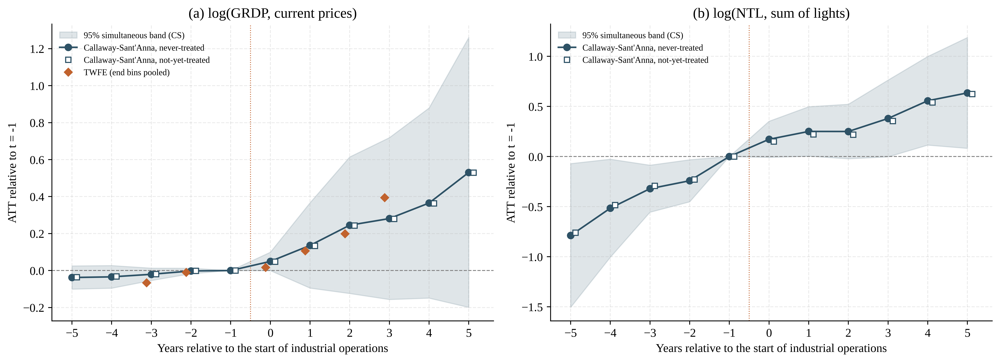

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (y, title_) in zip(axes, [("log_grdp_current", "(a) log(GRDP, current prices)"),
                                  ("log_ntl", "(b) log(NTL, sum of lights)")]):
    es = cs_results[(y, "nevertreated")]["es"]
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(-0.5, color=COLOR_INDUSTRIAL, linestyle=":", linewidth=0.8)
    ax.fill_between(es["e"], es["band_lo"].fillna(0), es["band_hi"].fillna(0),
                    color=COLOR_NONINDUSTRIAL, alpha=0.15, label="95% simultaneous band (CS)")
    ax.plot(es["e"], es["att"], "o-", color=COLOR_NONINDUSTRIAL, label="Callaway-Sant'Anna, never-treated")
    es_nyt = cs_results[(y, "notyettreated")]["es"]
    ax.plot(es_nyt["e"] + 0.12, es_nyt["att"], "s", color=COLOR_NONINDUSTRIAL, mfc="white",
            markersize=5, label="Callaway-Sant'Anna, not-yet-treated")
    if y == "log_grdp_current":
        xs = [x_pos[b] for b in BIN_ORDER]
        ax.plot(np.array(xs) - 0.12, res_event.params.reindex(bin_vars).values, "D", color=COLOR_INDUSTRIAL,
                markersize=5, label="TWFE (end bins pooled)")
    ax.set_xticks(range(-5, 6))
    ax.set_xlabel("Years relative to the start of industrial operations")
    ax.set_ylabel("ATT relative to t = -1")
    ax.set_title(title_)
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, "Figure_9")
plt.show()

## 12h. Validation of the industrial classification with sectoral GRDP

In [43]:
FILE_SECTOR = find_file("GRDP_sectoral_share", required=False)
SECTOR_OK = FILE_SECTOR is not None
if not SECTOR_OK:
    print("File GRDP_sectoral_share_BC_2015_2023.xlsx not uploaded -- Section 12h skipped.")
else:
    sector = pd.read_excel(FILE_SECTOR, sheet_name="Data Long (raw)")
    SECTOR_NAME_MAP = {
        "Baubau": "Kota Baubau", "Bitung": "Kota Bitung", "Kendari": "Kota Kendari",
        "Kepulauan Siau Tagulandang Biaro": "Siau Tagulandang Biaro",
        "Kotamobagu": "Kota Kotamobagu", "Makassar": "Kota Makassar", "Manado": "Kota Manado",
        "Palopo": "Kota Palopo", "Palu": "Kota Palu", "Pangkep": "Pangkajene Dan Kepulauan",
        "Parepare": "Kota Parepare", "Sidrap": "Sidenreng Rappang", "Ternate": "Kota Ternate",
        "Tidore Kepulauan": "Kota Tidore Kepulauan", "Tolitoli": "Toli-Toli", "Tomohon": "Kota Tomohon",
    }
    sector["regency"] = sector["regency"].replace(SECTOR_NAME_MAP)
    assert set(sector["regency"]) == set(df["regency"]), "name not matched"
    assert len(sector) == 79 * 9 and not sector.duplicated(["regency", "year"]).any()

    width_bc = sector.pivot(index="regency", columns="year", values="share_BC_total")
    sector_units = (df.drop_duplicates("regency")
                     .set_index("regency")[["province", "industrial_dummy"]])
    th0 = sector[sector["year"] == 2015].set_index("regency")
    sector_units["share_B_2015"] = th0["share_B"]
    sector_units["share_C_2015"] = th0["share_C"]
    sector_units["share_BC_2015"] = width_bc[2015]
    sector_units["share_BC_mean"] = width_bc.mean(axis=1)
    sector_units["share_BC_2023"] = width_bc[2023]
    sector_units["rank_BC_2015"] = sector_units["share_BC_2015"].rank(ascending=False, method="first")
    N_IND = int(sector_units["industrial_dummy"].sum())
    sector_units["industrial_top38_BC"] = (sector_units["rank_BC_2015"] <= N_IND).astype(int)
    sector_units["consistent"] = sector_units["industrial_dummy"] == sector_units["industrial_top38_BC"]

    from scipy.stats import mannwhitneyu
    from sklearn.metrics import roc_auc_score
    rows = []
    for col_, lab in [("share_BC_2015", "B+C share 2015 (main measure)"),
                     ("share_BC_mean", "Mean B+C share 2015-2023"),
                     ("share_BC_2023", "B+C share 2023")]:
        g1 = sector_units.loc[sector_units["industrial_dummy"] == 1, col_]
        g0 = sector_units.loc[sector_units["industrial_dummy"] == 0, col_]
        rows.append(dict(size_=lab, median_industrial=g1.median(), median_non_industrial=g0.median(),
                          mean_industrial=g1.mean(), mean_non_industrial=g0.mean(),
                          p_mann_whitney=mannwhitneyu(g1, g0).pvalue,
                          AUC=roc_auc_score(sector_units["industrial_dummy"], sector_units[col_])))
    table_sector_validation = pd.DataFrame(rows)
    print("Share of sectors B+C in GRDP at current prices (%), industrial vs non-industrial:")
    print(table_sector_validation.round(4).to_string(index=False))
    print(f"\nCross-tabulation: documented definition vs {N_IND} regencies/cities with the highest 2015 B+C share")
    print(pd.crosstab(sector_units["industrial_dummy"], sector_units["industrial_top38_BC"],
                      rownames=["industrial_dummy"], colnames=[f"top-{N_IND} B+C share 2015"]))
    print(f"Agreement: {sector_units['consistent'].sum()} of 79 regencies/cities "
          f"({sector_units['consistent'].mean():.1%})")
    inconsistent = sector_units[~sector_units["consistent"]].sort_values("share_BC_2015", ascending=False)
    print("\nInconsistent regencies/cities (reviewed manually, not dropped):")
    print(inconsistent[["province", "industrial_dummy", "share_B_2015", "share_C_2015",
                           "share_BC_2015", "share_BC_2023"]].round(2).to_string())

Share of sectors B+C in GRDP at current prices (%), industrial vs non-industrial:
                        size_  median_industrial  median_non_industrial  mean_industrial  mean_non_industrial  p_mann_whitney    AUC
B+C share 2015 (main measure)              19.16                 8.6250          22.4827              10.2731          0.0001 0.7651
     Mean B+C share 2015-2023              20.30                 8.2183          25.8660               9.8741          0.0000 0.8134
               B+C share 2023              21.33                 8.2250          30.8695               9.3019          0.0000 0.8436

Cross-tabulation: documented definition vs 37 regencies/cities with the highest 2015 B+C share
top-37 B+C share 2015   0   1
industrial_dummy             
0                      30  12
1                      12  25
Agreement: 55 of 79 regencies/cities (69.6%)

Inconsistent regencies/cities (reviewed manually, not dropped):
                                  province  industrial_dummy

In [44]:
if SECTOR_OK:
    def data_alt_definitions(dummy=None, save=None):
        d = data_cc.copy()
        if save is not None:
            d = d[d.index.get_level_values(0).isin(save)]
        if dummy is not None:
            d["industrial_dummy"] = d.index.get_level_values(0).map(dummy).astype(float)
        d["viirs_x_industrial"] = d["viirs_mean_radiance"] * d["industrial_dummy"]
        return d

    DEFINITIONS = [
        (f"A. Documented ({N_IND})", data_alt_definitions()),
        (f"B. Top-{N_IND} by B+C share 2015", data_alt_definitions(dummy=sector_units["industrial_top38_BC"])),
        (f"C. Consistent units only ({int(sector_units['consistent'].sum())})",
         data_alt_definitions(save=sector_units.index[sector_units["consistent"]])),
        ("D. Continuous: B+C share 2015 (per 10 pp)",
         data_alt_definitions(dummy=sector_units["share_BC_2015"] / 10)),
    ]
    def_results = []
    for name, d_alt in DEFINITIONS:
        t, n_obs = estimate_subsample(d_alt, "log_grdp_current")
        t.insert(0, "N", n_obs); t.insert(0, "definition", name)
        def_results.append(t)
    table_sector_definitions = pd.concat(def_results, ignore_index=True)
    def_order = [x[0] for x in DEFINITIONS]
    print("H1-H4 by industrial definition (two-way CRE, identical to the main model):")
    print(table_sector_definitions.pivot(index="definition", columns="hypothesis", values="estimate_")
          .reindex(def_order).round(3).to_string())
    print("\np-value WCR bootstrap:")
    print(table_sector_definitions.pivot(index="definition", columns="hypothesis", values="p_value_wcr_bootstrap")
          .reindex(def_order).round(3).to_string())
    print("\nNote: in definition D, H2 = difference in log GRDP per 10 pp of B+C share and H3 = difference in the "
          "NTL elasticity per 10 pp of B+C share (not a two-group difference).")

H1-H4 by industrial definition (two-way CRE, identical to the main model):
hypothesis                                 H1 (AME NTL)  H2 (industrial_dummy)  H3 (viirs_x_industrial)  H4 (viirs2)
definition                                                                                                          
A. Documented (37)                                0.236                  0.568                    0.102        0.050
B. Top-37 by B+C share 2015                       0.255                 -0.115                    0.078        0.049
C. Consistent units only (55)                     0.240                  1.277                    0.124        0.053
D. Continuous: B+C share 2015 (per 10 pp)         0.278                  0.421                    0.013        0.053

p-value WCR bootstrap:
hypothesis                                 H1 (AME NTL)  H2 (industrial_dummy)  H3 (viirs_x_industrial)  H4 (viirs2)
definition                                                                        

## 12i. NTL measure, operating status and sectoral GRDP

In [45]:
CONTROLS_V31 = [c for c in final_time_varying if c not in ("viirs_mean_radiance", "viirs_x_industrial", "viirs2")]
TI_V31 = [c for c in final_regs if c not in final_time_varying]

def cre_v31(data, y, tv, ti=TI_V31):
    d = data.dropna(subset=[y] + tv + ti).copy()
    d = add_group_means(d, tv)
    d, year_col = add_year_dummies(d)
    X = d[tv + ti + [f"{c}_bar" for c in tv] + year_col].assign(const=1.0)
    res = RandomEffects(d[y], X).fit(cov_type="clustered", cluster_entity=True)
    return res, d, X

def test_v31(res, d, X, y, combination):
    col_ = list(X.columns); rows = []
    for name, weights in combination.items():
        g = np.zeros(len(col_))
        for k, v in weights.items():
            g[col_.index(k)] = v
        b_h, t_h, p_h = wild_cluster_bootstrap(d[y], X, res.theta, g)
        est = float(g @ b_h)
        rows.append(dict(quantity_=name, estimate_=est, std_error=abs(est / t_h),
                          p_value_crv1=2 * norm.sf(abs(t_h)), p_value_wcr_bootstrap=p_h, N=len(d)))
    return pd.DataFrame(rows)

def hypothesis_combination(d, ntl, inter, square, ind="industrial_dummy"):
    v, i = d[ntl].mean(), d[ind].mean()
    return {"H1: AME NTL": {ntl: 1, inter: i, square: 2 * v}, "H2: industrial dummy": {ind: 1},
            "H3: NTL x industrial": {inter: 1}, "H4: NTL squared": {square: 1},
            "NTL effect, industrial": {ntl: 1, inter: 1, square: 2 * v},
            "NTL effect, non-industrial": {ntl: 1, square: 2 * v}}

year_v31 = data_cc.index.get_level_values(1)
v31_results = []

def replace_ntl(data, value):
    d = data.copy()
    d["viirs_mean_radiance"] = value.loc[d.index] if isinstance(value, pd.Series) else value
    d["viirs2"] = d["viirs_mean_radiance"] ** 2
    d["viirs_x_industrial"] = d["viirs_mean_radiance"] * d["industrial_dummy"]
    return d

old = np.log1p(data_cc["viirs_vcmcfg_old"])
size_ = [("A. ln(sum of lights), VNL masked [main]", data_cc, "main"),
          ("B. ln(1+mean radiance), VNL masked", replace_ntl(data_cc, np.log1p(data_cc["ntl_mean_masked"])), "alt"),
          ("C. ln(1+mean radiance), old monthly VCMCFG", replace_ntl(data_cc, old), "old"),
          ("D. ln(1+mean radiance), old VCMCFG, excl. 2016",
           replace_ntl(data_cc, old)[year_v31 != 2016], "old")]
print("Median radiance by year: VNL masked vs old VCMCFG data (2016 anomaly check):")
print(pd.DataFrame({"VNL masked": data_cc["ntl_mean_masked"].groupby(level=1).median(),
                    "old VCMCFG": data_cc["viirs_vcmcfg_old"].groupby(level=1).median()}).round(3).T.to_string())

for name, d_in, _ in size_:
    res, d, X = cre_v31(d_in, "log_grdp_current", ["viirs_mean_radiance", "viirs_x_industrial", "viirs2"] + CONTROLS_V31)
    t = test_v31(res, d, X, "log_grdp_current", hypothesis_combination(d, "viirs_mean_radiance", "viirs_x_industrial", "viirs2"))
    t.insert(0, "specification", name); t.insert(0, "analysis", "1. NTL measure")
    v31_results.append(t)

unit_v31 = data_cc.groupby(level=0)[["industrial_dummy", "start_year"]].first()
without_year = unit_v31.index[(unit_v31["industrial_dummy"] == 1) & unit_v31["start_year"].isna()]
print("\nIndustrial regencies/cities without a start year:", list(without_year))
YEAR_VARIANTS = ([("3 unknown excluded", None), ("3 unknown = active from 2015", 2015)] if len(without_year)
                else [("all start years sourced", None)])
for var_name, fill in YEAR_VARIANTS:
    d_in = data_cc.copy()
    if fill is None:
        d_in = d_in[~d_in.index.get_level_values(0).isin(without_year)]
    reg_i = d_in.index.get_level_values(0)
    start_ = reg_i.map(unit_v31["start_year"]).values.astype(float)
    if fill is not None:
        start_ = np.where(reg_i.isin(without_year), fill, start_)
    d_in["active"] = ((d_in["industrial_dummy"].values == 1) &
                     (d_in.index.get_level_values(1).values >= np.nan_to_num(start_, nan=9999))).astype(float)
    d_in["ntl_x_active"] = d_in["viirs_mean_radiance"] * d_in["active"]
    switches = int((d_in.groupby(level=0)["active"].nunique() > 1).sum())
    print(f"[{var_name}] regencies/cities ever active: {int(d_in.groupby(level=0)['active'].max().sum())}, "
          f"switching status within the panel: {switches}, share of active observations: {d_in['active'].mean():.3f}")
    tv = ["viirs_mean_radiance", "ntl_x_active", "active", "viirs2"] + CONTROLS_V31
    res, d, X = cre_v31(d_in, "log_grdp_current", tv)
    v, a = d["viirs_mean_radiance"].mean(), d["active"].mean()
    t = test_v31(res, d, X, "log_grdp_current", {
        "NTL x active (operating)": {"ntl_x_active": 1}, "Active (level shift)": {"active": 1},
        "H1: AME NTL": {"viirs_mean_radiance": 1, "ntl_x_active": a, "viirs2": 2 * v}})
    t.insert(0, "specification", f"E. NTL x active only ({var_name})"); t.insert(0, "analysis", "2. Operating status")
    v31_results.append(t)
    tv = ["viirs_mean_radiance", "viirs_x_industrial", "ntl_x_active", "active", "viirs2"] + CONTROLS_V31
    res, d, X = cre_v31(d_in, "log_grdp_current", tv)
    t = test_v31(res, d, X, "log_grdp_current", {
        "NTL x industrial (type)": {"viirs_x_industrial": 1}, "NTL x active (operating)": {"ntl_x_active": 1},
        "Active (level shift)": {"active": 1}})
    t.insert(0, "specification", f"F. Type + operating ({var_name})"); t.insert(0, "analysis", "2. Operating status")
    v31_results.append(t)

if SECTOR_OK:
    share_ = sector.set_index(["regency", "year"])[["share_BC_total"]]
    d_sec = data_cc.join(share_, how="inner")
    total = d_sec["grdp_current_bn"]
    d_sec["log_grdp_BC"] = np.log(total * d_sec["share_BC_total"] / 100)
    d_sec["log_grdp_nonBC"] = np.log(total * (1 - d_sec["share_BC_total"] / 100))
    print(f"\nSectoral sample: N = {len(d_sec)} (79 regencies/cities x 2015-2023)")
    for y, lab in [("log_grdp_current", "G. Total GRDP, 2015-2023"), ("log_grdp_BC", "H. GRDP sectors B+C"),
                   ("log_grdp_nonBC", "I. GRDP excl. B+C")]:
        res, d, X = cre_v31(d_sec, y, ["viirs_mean_radiance", "viirs_x_industrial", "viirs2"] + CONTROLS_V31)
        t = test_v31(res, d, X, y, hypothesis_combination(d, "viirs_mean_radiance", "viirs_x_industrial", "viirs2"))
        t.insert(0, "specification", lab); t.insert(0, "analysis", "3. Sectoral GRDP")
        v31_results.append(t)
else:
    print("Sectoral GRDP file not uploaded -- mechanism test (3) skipped.")

table_v31 = pd.concat(v31_results, ignore_index=True)
pd.set_option("display.width", 220)
for an, t in table_v31.groupby("analysis", sort=False):
    print(f"\n=== {an} ===")
    print(t.drop(columns="analysis").round(4).to_string(index=False))

Median radiance by year: VNL masked vs old VCMCFG data (2016 anomaly check):
year         2015   2016   2017   2018   2019   2020   2021   2022  2023   2024   2025
VNL masked  0.043  0.043  0.063  0.070  0.080  0.095  0.101  0.110  0.15  0.131  0.148
old VCMCFG  0.113  0.053  0.257  0.267  0.242  0.312  0.341  0.305  0.41  0.327  0.310



Industrial regencies/cities without a start year: []
[all start years sourced] regencies/cities ever active: 37, switching status within the panel: 15, share of active observations: 0.383



Sectoral sample: N = 711 (79 regencies/cities x 2015-2023)



=== 1. NTL measure ===
                                 specification                  quantity_  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap   N
       A. ln(sum of lights), VNL masked [main]                H1: AME NTL     0.2364     0.0865        0.0063                 0.0023 869
       A. ln(sum of lights), VNL masked [main]       H2: industrial dummy     0.5681     0.9155        0.5349                 0.5816 869
       A. ln(sum of lights), VNL masked [main]       H3: NTL x industrial     0.1017     0.0391        0.0092                 0.0126 869
       A. ln(sum of lights), VNL masked [main]            H4: NTL squared     0.0501     0.0158        0.0015                 0.0221 869
       A. ln(sum of lights), VNL masked [main]     NTL effect, industrial     0.2905     0.0966        0.0026                 0.0000 869
       A. ln(sum of lights), VNL masked [main] NTL effect, non-industrial     0.1888     0.0811        0.0200                 0.0291 869
            B. ln

## 12j. Strict industrial definition

In [46]:
INDUSTRIAL_WEAK_EVIDENCE = ["Kolaka Utara"]
unit_ind = data_cc.groupby(level=0)["industrial_dummy"].first()
assert set(INDUSTRIAL_WEAK_EVIDENCE) <= set(unit_ind[unit_ind == 1].index), "name not matched / not industrial"
industrial_strict = unit_ind.index[(unit_ind == 1) & ~unit_ind.index.isin(INDUSTRIAL_WEAK_EVIDENCE)]
print(f"Strict industrial: {len(industrial_strict)} regencies/cities -> {sorted(industrial_strict)}")

d_s1 = data_cc.copy()
d_s1["industrial_dummy"] = d_s1.index.get_level_values(0).isin(industrial_strict).astype(float)
d_s1["viirs_x_industrial"] = d_s1["viirs_mean_radiance"] * d_s1["industrial_dummy"]
d_s2 = d_s1[~d_s1.index.get_level_values(0).isin(INDUSTRIAL_WEAK_EVIDENCE)]

strict_results = []
d_original = data_cc.copy()
d_original["industrial_dummy"] = d_original["industrial_dummy_original"].astype(float)
d_original["viirs_x_industrial"] = d_original["viirs_mean_radiance"] * d_original["industrial_dummy"]
n_k = len(industrial_strict)
for name, d_in in [("A0. Original classification (38 vs 41)", d_original),
                   ("A. Corrected v35, main (37 vs 42)", data_cc),
                   (f"S1. Strict, weak units reclassified ({n_k} vs {79 - n_k})", d_s1),
                   (f"S2. Strict, weak units dropped ({n_k} vs 42)", d_s2)]:
    t, n_obs = estimate_subsample(d_in, "log_grdp_current")
    t.insert(0, "N", n_obs); t.insert(0, "definition", name)
    strict_results.append(t)
table_strict = pd.concat(strict_results, ignore_index=True)
strict_order = table_strict["definition"].unique()
print("\nH1-H4 estimates:")
print(table_strict.pivot(index="definition", columns="hypothesis", values="estimate_").reindex(strict_order).round(3).to_string())
print("\np-value WCR bootstrap:")
print(table_strict.pivot(index="definition", columns="hypothesis", values="p_value_wcr_bootstrap").reindex(strict_order).round(3).to_string())
print("\nN:", table_strict.groupby("definition", sort=False)["N"].first().to_dict())

Strict industrial: 36 regencies/cities -> ['Banggai', 'Bantaeng', 'Bolaang Mongondow', 'Bombana', 'Bone', 'Buol', 'Buton', 'Donggala', 'Halmahera Selatan', 'Halmahera Tengah', 'Halmahera Timur', 'Halmahera Utara', 'Jeneponto', 'Kolaka', 'Konawe', 'Konawe Kepulauan', 'Konawe Selatan', 'Konawe Utara', 'Kota Bitung', 'Kota Makassar', 'Kota Palu', 'Luwu', 'Luwu Timur', 'Luwu Utara', 'Maros', 'Minahasa Selatan', 'Minahasa Utara', 'Morowali', 'Morowali Utara', 'Pangkajene Dan Kepulauan', 'Pinrang', 'Poso', 'Pulau Taliabu', 'Sidenreng Rappang', 'Takalar', 'Toraja Utara']



H1-H4 estimates:
hypothesis                                      H1 (AME NTL)  H2 (industrial_dummy)  H3 (viirs_x_industrial)  H4 (viirs2)
definition                                                                                                               
A0. Original classification (38 vs 41)                 0.241                  0.271                    0.091        0.051
A. Corrected v35, main (37 vs 42)                      0.236                  0.568                    0.102        0.050
S1. Strict, weak units reclassified (36 vs 43)         0.236                  0.105                    0.104        0.049
S2. Strict, weak units dropped (36 vs 42)              0.238                  0.385                    0.105        0.049

p-value WCR bootstrap:
hypothesis                                      H1 (AME NTL)  H2 (industrial_dummy)  H3 (viirs_x_industrial)  H4 (viirs2)
definition                                                                                              

## 12k. Multiple testing, VNL version and brightness

In [47]:
p_main = table_wcb[table_wcb["model"].str.contains("MAIN")].set_index("hypothesis")["p_value_wcr_bootstrap"]
order = p_main.sort_values()
m = len(order)
holm = np.minimum(1, np.maximum.accumulate([(m - i) * p for i, p in enumerate(order.values)]))
table_holm = pd.DataFrame({"p_WCR": order.values, "p_Holm": holm}, index=order.index).reindex(p_main.index)
table_holm["role"] = ["confirmatory" if h.startswith("H3") else "supporting" for h in table_holm.index]
print("(1) Holm correction for 4 hypotheses (main model, WCR bootstrap p-values):")
print(table_holm.round(4).to_string())

year_k = data_cc.index.get_level_values(1)
assert set(data_cc.loc[year_k <= 2021, "source_collection"]) == {"NOAA/VIIRS/DNB/ANNUAL_V21"}
table_v21, n_v21 = estimate_subsample(data_cc[year_k <= 2021], "log_grdp_current")
print(f"\n(2) Main model, 2015-2021 only (V21), N = {n_v21}:")
print(table_v21.round(4).to_string(index=False))

d_bright = data_cc.copy()
bright_i = d_bright.groupby(level=0)["viirs_mean_radiance"].transform("mean")
bright_c = bright_i - d_bright.groupby(level=0)["viirs_mean_radiance"].mean().mean()
d_bright["ntl_x_bright"] = d_bright["viirs_mean_radiance"] * bright_c
mean_brightness = d_bright.groupby(level=0)[["viirs_mean_radiance", "industrial_dummy"]].mean().groupby("industrial_dummy").mean()
print("\n(3) Mean ln(SOL) by group (0 = non-industrial, 1 = industrial):")
print(mean_brightness.round(3).to_string())
tv = ["viirs_mean_radiance", "viirs_x_industrial", "ntl_x_bright", "viirs2"] + CONTROLS_V31
res_t, d_t, X_t = cre_v31(d_bright, "log_grdp_current", tv)
table_brightness = test_v31(res_t, d_t, X_t, "log_grdp_current", {
    "H3: NTL x industrial (controlling brightness)": {"viirs_x_industrial": 1},
    "NTL x mean brightness": {"ntl_x_bright": 1},
    "H4: NTL squared": {"viirs2": 1}})
print("\nMain model + NTL x mean regency brightness:")
print(table_brightness.round(4).to_string(index=False))

(1) Holm correction for 4 hypotheses (main model, WCR bootstrap p-values):
                          p_WCR  p_Holm          role
hypothesis                                           
H1 (AME NTL)             0.0023  0.0092    supporting
H2 (industrial_dummy)    0.5816  0.5816    supporting
H3 (viirs_x_industrial)  0.0126  0.0378  confirmatory
H4 (viirs2)              0.0221  0.0442    supporting



(2) Main model, 2015-2021 only (V21), N = 553:
             hypothesis  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap
           H1 (AME NTL)     0.0633     0.0350        0.0702                 0.0849
  H2 (industrial_dummy)     0.6267     0.7921        0.4288                 0.4751
H3 (viirs_x_industrial)     0.0858     0.0353        0.0149                 0.0117
            H4 (viirs2)     0.0143     0.0087        0.1017                 0.1038

(3) Mean ln(SOL) by group (0 = non-industrial, 1 = industrial):
                  viirs_mean_radiance
industrial_dummy                     
0.0                              6.31
1.0                              7.05



Main model + NTL x mean regency brightness:
                                    quantity_  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap   N
H3: NTL x industrial (controlling brightness)     0.1058     0.0411        0.0101                 0.0079 869
                        NTL x mean brightness    -0.0577     0.0379        0.1279                 0.2353 869
                              H4: NTL squared     0.0751     0.0211        0.0004                 0.0385 869


## 12l. Leave-one-out

In [48]:
reg_idx_loo = data_cc.index.get_level_values(0)
unit_ind_loo = data_cc.groupby(level=0)["industrial_dummy"].first()
industrial_loo = sorted(unit_ind_loo.index[unit_ind_loo == 1])
prov_loo = data_cc.groupby(level=0)["province"].first()

def h3_without(mask_drop):
    t, n_obs = estimate_subsample(data_cc[~mask_drop], "log_grdp_current")
    r = t[t["hypothesis"].str.startswith("H3")].iloc[0]
    return r["estimate_"], r["std_error"], r["p_value_wcr_bootstrap"], n_obs

rows_loo = []
for reg in industrial_loo:
    est, se, p, n = h3_without(np.asarray(reg_idx_loo == reg))
    rows_loo.append(dict(kind="regencies/cities", dropped=reg, province=prov_loo[reg], N=n,
                          H3=est, se=se, p_WCR=p))
for prov in sorted(prov_loo.unique()):
    est, se, p, n = h3_without(np.asarray(reg_idx_loo.map(prov_loo) == prov))
    rows_loo.append(dict(kind="province", dropped=prov, province=prov, N=n, H3=est, se=se, p_WCR=p))
table_loo = pd.DataFrame(rows_loo)
h3_main = float(res_final.params["viirs_x_industrial"])

for kind, t in table_loo.groupby("kind", sort=False):
    print(f"=== Dropping one {kind} ({len(t)} estimates) ===")
    print(f"H3 main model: {h3_main:+.3f}")
    print(f"H3 range: {t['H3'].min():+.3f} s.d. {t['H3'].max():+.3f}; positive: {int((t['H3'] > 0).sum())}/{len(t)}; "
          f"significant at 5% (WCR): {int((t['p_WCR'] < 0.05).sum())}/{len(t)}; max WCR p: {t['p_WCR'].max():.3f}")
    print(t.assign(shift=t["H3"] - h3_main).sort_values("shift")
           [["dropped", "province", "N", "H3", "se", "p_WCR"]].round(4).to_string(index=False))
    print()

=== Dropping one regencies/cities (37 estimates) ===
H3 main model: +0.102
H3 range: +0.074 s.d. +0.123; positive: 37/37; significant at 5% (WCR): 37/37; max WCR p: 0.037
                 dropped          province   N     H3     se  p_WCR
        Halmahera Tengah      Maluku Utara 858 0.0743 0.0260 0.0081
                 Banggai   Sulawesi Tengah 858 0.0891 0.0363 0.0251
              Luwu Timur  Sulawesi Selatan 858 0.0918 0.0372 0.0207
        Konawe Kepulauan Sulawesi Tenggara 858 0.0972 0.0438 0.0350
          Morowali Utara   Sulawesi Tengah 858 0.0976 0.0430 0.0369
                Morowali   Sulawesi Tengah 858 0.0980 0.0369 0.0113
           Kota Makassar  Sulawesi Selatan 858 0.0999 0.0388 0.0129
        Minahasa Selatan    Sulawesi Utara 858 0.1000 0.0390 0.0143
            Toraja Utara  Sulawesi Selatan 858 0.1006 0.0394 0.0156
             Kota Bitung    Sulawesi Utara 858 0.1011 0.0392 0.0144
       Halmahera Selatan      Maluku Utara 858 0.1014 0.0406 0.0180
             

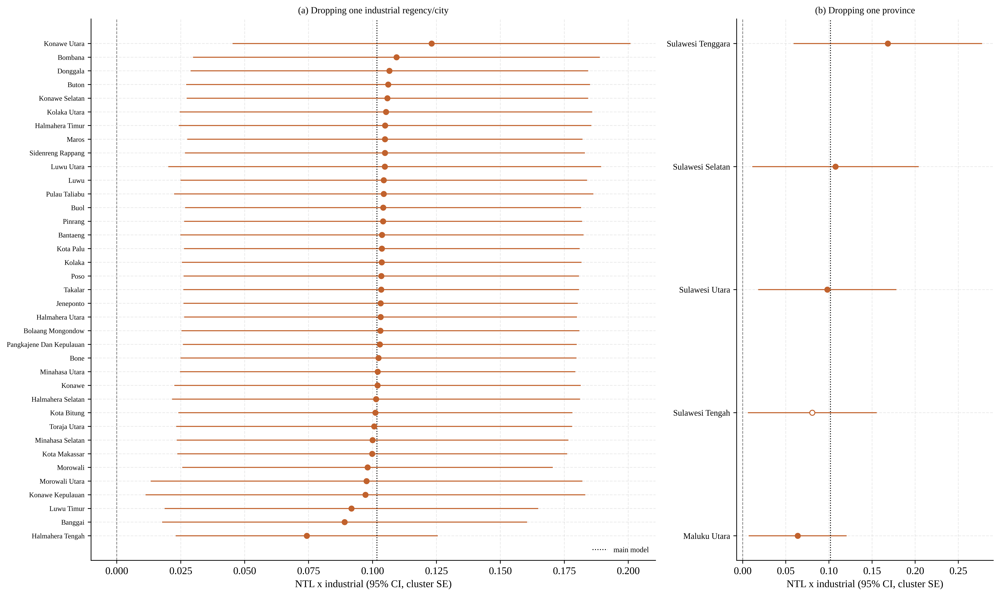

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [2.2, 1]})
for ax, kind, title_ in [(axes[0], "regencies/cities", "(a) Dropping one industrial regency/city"),
                          (axes[1], "province", "(b) Dropping one province")]:
    t = table_loo[table_loo["kind"] == kind].sort_values("H3")
    ypos = np.arange(len(t))
    for yy, (_, r) in zip(ypos, t.iterrows()):
        ax.plot([r.H3 - 1.96 * r.se, r.H3 + 1.96 * r.se], [yy, yy], color=COLOR_INDUSTRIAL, linewidth=1.1)
        ax.scatter(r.H3, yy, color=COLOR_INDUSTRIAL if r.p_WCR < 0.05 else "white",
                   edgecolor=COLOR_INDUSTRIAL, s=30, zorder=3)
    ax.axvline(h3_main, color="black", linestyle=":", linewidth=1, label="main model")
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_yticks(ypos); ax.set_yticklabels(t["dropped"], fontsize=7.5 if kind == "regencies/cities" else 9)
    ax.set_xlabel("NTL x industrial (95% CI, cluster SE)")
    ax.set_title(title_, fontsize=10)
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
save_figure(fig, "Figure_4")
plt.show()

## 12m. Sectoral structure (17 industries)

In [50]:
FILE_17 = find_file("GRDP_17_industries", required=False)
SECTOR17_OK = FILE_17 is not None
if not SECTOR17_OK:
    print("File GRDP_17_industries_current_prices_2015_2025.csv not uploaded -- Section 12m skipped.")
else:
    KAT17 = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M_N", "O", "P", "Q", "R_S_T_U"]
    s17 = pd.read_csv(FILE_17)
    tot17 = s17[KAT17].sum(axis=1, min_count=17)
    share17 = s17[KAT17].div(tot17, axis=0)
    s17["HHI"] = 100 * (share17 ** 2).sum(axis=1, min_count=17)
    s17["DIV"] = 100 * (-(share17 * np.log(share17.where(share17 > 0))).sum(axis=1, min_count=1) / np.log(17))
    s17.loc[tot17.isna(), "DIV"] = np.nan
    s17["share_BC17"] = 100 * (s17["B"] + s17["C"]) / tot17
    s17 = s17.sort_values(["regency", "year"])
    share17.index = s17.index if share17.index.equals(s17.index) else share17.index
    lag = share17.loc[s17.index].groupby(s17["regency"]).shift(1)
    s17["SCI"] = 100 * 0.5 * (share17.loc[s17.index] - lag).abs().sum(axis=1, min_count=17)
    s17.loc[lag.isna().any(axis=1), "SCI"] = np.nan

    check = s17.merge(panel[["regency", "year", "grdp_current_bn"]], on=["regency", "year"])
    rel = (check[KAT17].sum(axis=1, min_count=17) / 1000 / check["grdp_current_bn"] - 1) * 100
    print(f"Unit-years: {len(s17)}; all 17 industries complete: {int(tot17.notna().sum())}; "
          f"difference between the 17-industry sum and panel GRDP: max {rel.abs().max():.3f}%")
    print("Documented corrections:", int((s17["correction"].fillna("") != "").sum()), "unit-years")

    d17 = data_cc.join(s17.set_index(["regency", "year"])[["HHI", "DIV", "SCI", "share_BC17"]], how="left")
    d17 = d17.sort_index()
    d17["dntl"] = d17.groupby(level=0)["viirs_mean_radiance"].diff()
    d17["dntl_x_ind"] = d17["dntl"] * d17["industrial_dummy"]

    print("\nMean HHI, entropy and SCI by group and year:")
    summary17 = (d17.assign(group=np.where(d17["industrial_dummy"] == 1, "Industrial", "Non-industrial"))
                 .groupby(["group", d17.index.get_level_values(1)])[["HHI", "DIV", "SCI", "share_BC17"]].mean())
    print(summary17.round(2).unstack(0).to_string())

Unit-years: 869; all 17 industries complete: 868; difference between the 17-industry sum and panel GRDP: max 0.044%
Documented corrections: 12 unit-years

Mean HHI, entropy and SCI by group and year:
             HHI                       DIV                       SCI                share_BC17               
group Industrial Non-industrial Industrial Non-industrial Industrial Non-industrial Industrial Non-industrial
year                                                                                                         
2015       23.25          19.67      66.94          71.97        NaN            NaN      22.48          10.27
2016       22.84          19.61      67.30          72.03       2.15           1.32      22.68          10.15
2017       22.69          19.47      67.34          72.16       1.76           0.99      23.53          10.15
2018       22.78          19.25      67.26          72.35       2.87           1.22      24.74           9.95
2019       22.17          18.9

In [51]:
if SECTOR17_OK:
    def structure_test(data, y, tv, combination, label):
        res, d, X = cre_v31(data, y, tv)
        t = test_v31(res, d, X, y, combination)
        t.insert(0, "specification", label)
        return t

    TV_H5 = ["viirs_mean_radiance", "viirs_x_industrial"] + CONTROLS_V31
    K_H5 = {"H5: NTL x industrial (on HHI)": {"viirs_x_industrial": 1},
            "NTL effect on HHI, industrial": {"viirs_mean_radiance": 1, "viirs_x_industrial": 1},
            "NTL effect on HHI, non-industrial": {"viirs_mean_radiance": 1}}
    K_DIV = {"H5 alt: NTL x industrial (on entropy)": {"viirs_x_industrial": 1},
             "NTL effect on entropy, industrial": {"viirs_mean_radiance": 1, "viirs_x_industrial": 1},
             "NTL effect on entropy, non-industrial": {"viirs_mean_radiance": 1}}
    TV_H6 = ["dntl", "dntl_x_ind"]
    K_H6 = {"H6: dNTL x industrial (on SCI)": {"dntl_x_ind": 1},
            "dNTL effect on SCI, industrial": {"dntl": 1, "dntl_x_ind": 1},
            "dNTL effect on SCI, non-industrial": {"dntl": 1}}

    results17 = [structure_test(d17, "HHI", TV_H5, K_H5, "A. Main: HHI, 2015-2025"),
               structure_test(d17, "SCI", TV_H6, K_H6, "B. Main: SCI, 2016-2025")]
    main17 = pd.concat(results17, ignore_index=True)
    pk = main17["quantity_"].str.startswith(("H5:", "H6:"))
    p_raw = main17.loc[pk, "p_value_wcr_bootstrap"].values
    order = np.argsort(p_raw); m = len(p_raw); p_holm = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, min(1.0, (m - r) * p_raw[i])); p_holm[i] = run
    main17["p_holm"] = np.nan
    main17.loc[pk, "p_holm"] = p_holm
    print("=== H5-H6 (Holm over H5 and H6) ===")
    print(main17.round(4).to_string(index=False))

    year17 = d17.index.get_level_values(1)
    reg17 = d17.index.get_level_values(0)
    prov17 = d17.groupby(level=0)["province"].first()
    robust17 = [structure_test(d17, "DIV", TV_H5, K_DIV, "C. Entropy instead of HHI"),
                structure_test(d17[year17 <= 2021], "HHI", TV_H5, K_H5, "D. HHI, 2015-2021 (V21 only)"),
                structure_test(d17[year17 <= 2021], "SCI", TV_H6, K_H6, "D. SCI, 2016-2021 (V21 only)"),
                structure_test(d17[~reg17.isin(["Morowali", "Halmahera Tengah"])], "HHI", TV_H5, K_H5,
                             "E. HHI, excl. Morowali & Halmahera Tengah"),
                structure_test(d17[~reg17.isin(["Morowali", "Halmahera Tengah"])], "SCI", TV_H6, K_H6,
                             "E. SCI, excl. Morowali & Halmahera Tengah")]
    for prov in sorted(prov17.unique()):
        robust17.append(structure_test(d17[np.asarray(reg17.map(prov17) != prov)], "HHI", TV_H5, K_H5,
                                     f"F. HHI, without {prov}"))
    table_robust17 = pd.concat(robust17, ignore_index=True)
    print("\n=== Robustness checks (all reported) ===")
    print(table_robust17[table_robust17["quantity_"].str.contains("H5|H6")].round(4).to_string(index=False))

    d17m = d17.dropna(subset=["share_BC17"]).copy()
    d17m["log_grdp_BC17"] = np.log(d17m["grdp_current_bn"] * d17m["share_BC17"] / 100)
    d17m["log_grdp_nonBC17"] = np.log(d17m["grdp_current_bn"] * (1 - d17m["share_BC17"] / 100))
    mech17 = []
    for y, lab in [("log_grdp_BC17", "GRDP sectors B+C (17-sector data, 2015-2025)"),
                   ("log_grdp_nonBC17", "GRDP excl. B+C (17-sector data, 2015-2025)")]:
        res, d, X = cre_v31(d17m, y, ["viirs_mean_radiance", "viirs_x_industrial", "viirs2"] + CONTROLS_V31)
        t = test_v31(res, d, X, y, hypothesis_combination(d, "viirs_mean_radiance", "viirs_x_industrial", "viirs2"))
        t.insert(0, "specification", lab); mech17.append(t)
    table_mech17 = pd.concat(mech17, ignore_index=True)
    print("\n=== B+C mechanism repeated with the 17-industry data ===")
    print(table_mech17[table_mech17["quantity_"].str.contains("H3|effect")].round(4).to_string(index=False))

=== H5-H6 (Holm over H5 and H6) ===
          specification                          quantity_  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap   N  p_holm
A. Main: HHI, 2015-2025      H5: NTL x industrial (on HHI)     1.9691     1.0791        0.0680                 0.0984 868  0.1968
A. Main: HHI, 2015-2025      NTL effect on HHI, industrial     3.1692     1.4256        0.0262                 0.0427 868     NaN
A. Main: HHI, 2015-2025  NTL effect on HHI, non-industrial     1.2000     0.7770        0.1225                 0.1616 868     NaN
B. Main: SCI, 2016-2025     H6: dNTL x industrial (on SCI)     0.0097     0.6641        0.9883                 0.9881 789  0.9881
B. Main: SCI, 2016-2025     dNTL effect on SCI, industrial    -0.0723     0.6809        0.9155                 0.9176 789     NaN
B. Main: SCI, 2016-2025 dNTL effect on SCI, non-industrial    -0.0820     0.1936        0.6718                 0.6564 789     NaN



=== Robustness checks (all reported) ===
                            specification                             quantity_  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap   N
                C. Entropy instead of HHI H5 alt: NTL x industrial (on entropy)    -2.2277     1.0506        0.0340                 0.0606 868
             D. HHI, 2015-2021 (V21 only)         H5: NTL x industrial (on HHI)     0.4252     0.9359        0.6496                 0.6984 553
             D. SCI, 2016-2021 (V21 only)        H6: dNTL x industrial (on SCI)    -0.8420     0.7282        0.2476                 0.2595 474
E. HHI, excl. Morowali & Halmahera Tengah         H5: NTL x industrial (on HHI)     0.5481     0.7527        0.4665                 0.4894 846
E. SCI, excl. Morowali & Halmahera Tengah        H6: dNTL x industrial (on SCI)     0.5148     0.6278        0.4122                 0.4416 769
             F. HHI, without Maluku Utara         H5: NTL x industrial (on HHI)     1.0975     1.007


=== B+C mechanism repeated with the 17-industry data ===
                               specification                  quantity_  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap   N
GRDP sectors B+C (17-sector data, 2015-2025)       H3: NTL x industrial     0.3534     0.0967        0.0003                 0.0005 868
GRDP sectors B+C (17-sector data, 2015-2025)     NTL effect, industrial     0.5620     0.1387        0.0001                 0.0002 868
GRDP sectors B+C (17-sector data, 2015-2025) NTL effect, non-industrial     0.2086     0.1211        0.0850                 0.1284 868
  GRDP excl. B+C (17-sector data, 2015-2025)       H3: NTL x industrial     0.0062     0.0118        0.5974                 0.5995 868
  GRDP excl. B+C (17-sector data, 2015-2025)     NTL effect, industrial     0.0220     0.0191        0.2513                 0.3953 868
  GRDP excl. B+C (17-sector data, 2015-2025) NTL effect, non-industrial     0.0157     0.0219        0.4724                 0.5306 8

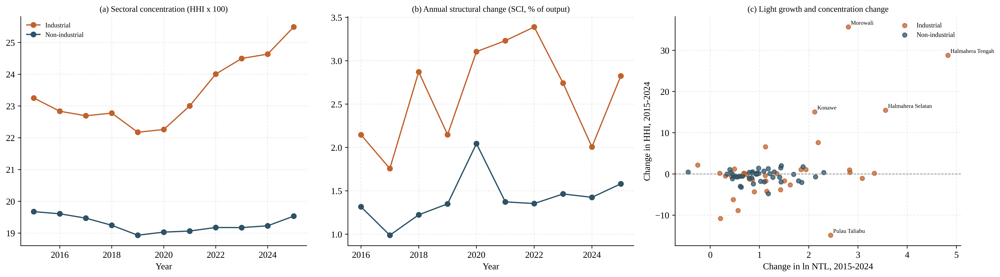

In [52]:
if SECTOR17_OK:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    g = (d17.assign(group=np.where(d17["industrial_dummy"] == 1, "Industrial", "Non-industrial"))
         .groupby(["group", d17.index.get_level_values(1)])[["HHI", "SCI"]].mean().reset_index())
    g.columns = ["group", "year", "HHI", "SCI"]
    for grp, col in [("Industrial", COLOR_INDUSTRIAL), ("Non-industrial", COLOR_NONINDUSTRIAL)]:
        s = g[g["group"] == grp]
        axes[0].plot(s["year"], s["HHI"], marker="o", color=col, label=grp)
        axes[1].plot(s["year"], s["SCI"], marker="o", color=col, label=grp)
    axes[0].set_title("(a) Sectoral concentration (HHI x 100)", fontsize=10); axes[0].set_xlabel("Year")
    axes[1].set_title("(b) Annual structural change (SCI, % of output)", fontsize=10); axes[1].set_xlabel("Year")
    axes[0].legend(fontsize=8)
    start, end = 2015, 2024
    u = d17.reset_index()
    w = u[u["year"].isin([start, end])].pivot_table(index="regency", columns="year",
                                                         values=["viirs_mean_radiance", "HHI"])
    ind_u = u.groupby("regency")["industrial_dummy"].first()
    dx = w[("viirs_mean_radiance", end)] - w[("viirs_mean_radiance", start)]
    dy = w[("HHI", end)] - w[("HHI", start)]
    for grp, col in [(1, COLOR_INDUSTRIAL), (0, COLOR_NONINDUSTRIAL)]:
        mk = ind_u.reindex(dx.index) == grp
        axes[2].scatter(dx[mk], dy[mk], color=col, alpha=0.75, s=28,
                        label="Industrial" if grp == 1 else "Non-industrial")
    for nm in dy.abs().sort_values(ascending=False).index[:5]:
        axes[2].annotate(nm, (dx[nm], dy[nm]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    axes[2].axhline(0, color="gray", linewidth=0.8, linestyle="--")
    axes[2].set_xlabel(f"Change in ln NTL, {start}-{end}"); axes[2].set_ylabel(f"Change in HHI, {start}-{end}")
    axes[2].set_title("(c) Light growth and concentration change", fontsize=10)
    axes[2].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, "Figure_10")
    plt.show()

### Figure 6

Regencies/cities by change in B+C share, 2015-2024 (pp):
bin
Below −5     6
−5 to 0     39
0 to 5      24
5 to 15      3
15 to 40     4
Above 40     3


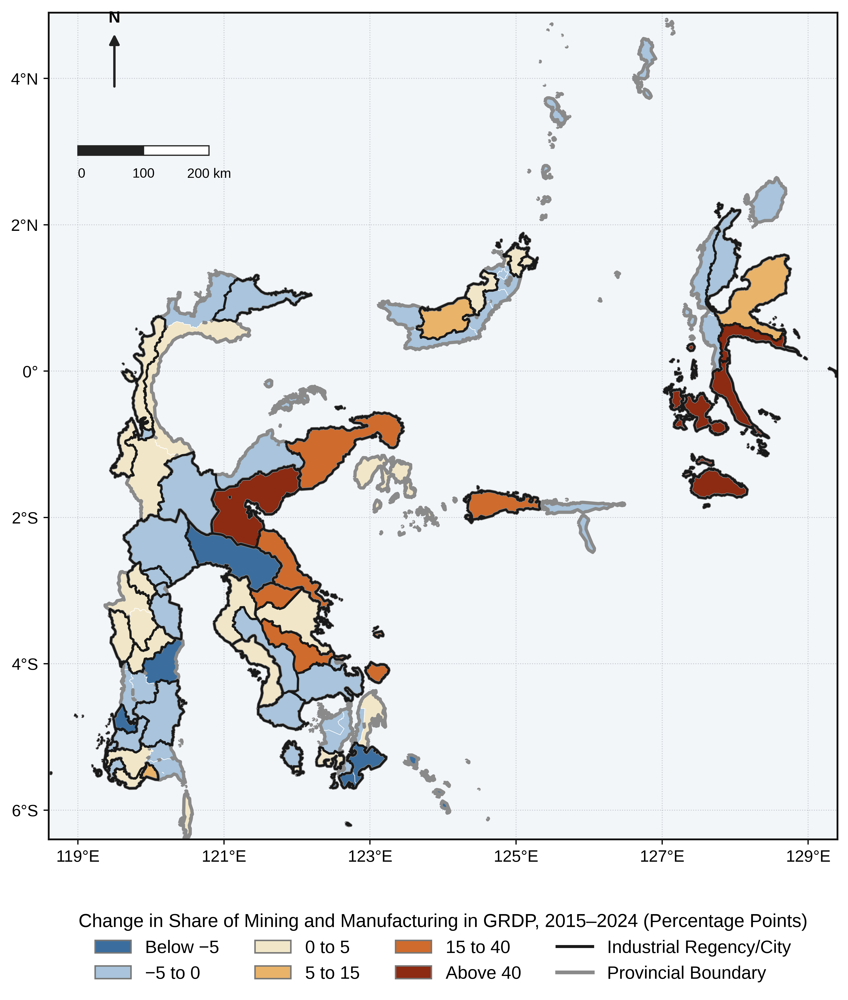

In [53]:
if SECTOR17_OK and HAS_MAP:
    share_bc = d17["share_BC17"].unstack()
    change_bc = (share_bc[2024] - share_bc[2015]).rename("change")
    BINS = [-np.inf, -5, 0, 5, 15, 40, np.inf]
    LABELS = ["Below −5", "−5 to 0", "0 to 5", "5 to 15", "15 to 40", "Above 40"]
    BIN_COLORS = ["#3B6E9E", "#A9C4DC", "#F1E6C8", "#E9B36A", "#CF6B2C", "#8C2A12"]
    g7 = gdf_bounds.merge(change_bc, left_on="regency", right_index=True, how="left")
    g7["bin"] = pd.cut(g7["change"], BINS, labels=LABELS)
    g7["industrial"] = g7["regency"].map(df.groupby("regency")["industrial_dummy"].first())
    print("Regencies/cities by change in B+C share, 2015-2024 (pp):")
    print(g7.loc[g7["change"].notna(), "bin"].value_counts().reindex(LABELS).to_string())
    with plt.rc_context(MAP_STYLE):
        fig, ax = plt.subplots(figsize=(10.5, 10))
        for lab, col in zip(LABELS, BIN_COLORS):
            sel = g7[g7["bin"] == lab]
            if len(sel):
                sel.plot(ax=ax, color=col, edgecolor="white", linewidth=0.4)
        g7.dissolve(by="province_geo").boundary.plot(ax=ax, color="#8A8A8A", linewidth=2.2)
        g7[g7["industrial"] == 1].boundary.plot(ax=ax, color="#191919", linewidth=1.5)
        format_map(ax)
        handles = [Patch(facecolor=c, edgecolor="#777777", label=l) for l, c in zip(LABELS, BIN_COLORS)]
        handles += [Line2D([0], [0], color="#191919", lw=2, label="Industrial Regency/City"),
                    Line2D([0], [0], color="#8A8A8A", lw=2.5, label="Provincial Boundary")]
        ax.legend(handles=handles, title="Change in Share of Mining and Manufacturing in GRDP, 2015–2024 (Percentage Points)",
                  loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4, frameon=False, fontsize=12, title_fontsize=12.5)
        save_figure(fig, "Figure_6")
        plt.show()

## 12n. Sectoral structure around the start of operations

In [54]:
if SECTOR17_OK:
    s17k = s17[["regency", "year", "HHI", "share_BC17"]]
    df_cs_original = df_cs.copy()
    cs17 = df_cs_original.merge(s17k, on=["regency", "year"], how="left")

    def cs_structure(data, y, controls="nevertreated"):
        global df_cs
        df_cs = data.copy()
        try:
            return run_cs(y, controls)
        finally:
            df_cs = df_cs_original

    def summary_cs(r):
        es = r["es"]; pre = es[es["e"] < -1]
        return dict(ATT=r["att_simple"], SE=r["se_simple"], p=2 * norm.sf(abs(r["att_simple"] / r["se_simple"])),
                    pre_band_excl_0=int(((pre["band_lo"] > 0) | (pre["band_hi"] < 0)).sum()))

    main_cs17 = cs17[cs17["year"] <= 2024]
    assert main_cs17[["HHI", "share_BC17"]].notna().all().all()
    n_treat = main_cs17.loc[main_cs17["g"] > 0, "regency"].nunique()
    n_ctrl = main_cs17.loc[main_cs17["g"] == 0, "regency"].nunique()
    print(f"Structure event-study sample: {n_treat} regencies/cities treated, {n_ctrl} never-treated, 2015-2024")

    es17_results = {}
    rows = []
    for y, lab in [("HHI", "H7: HHI"), ("share_BC17", "H8: B+C share")]:
        r = cs_structure(main_cs17, y)
        es17_results[y] = r
        rows.append(dict(test=lab, specification="Main: never-treated, 2015-2024", **summary_cs(r)))
    table_es17 = pd.DataFrame(rows)
    p_raw = table_es17["p"].values; order = np.argsort(p_raw); m_ = len(p_raw); ph = np.empty(m_); run = 0.0
    for k_, i_ in enumerate(order):
        run = max(run, min(1.0, (m_ - k_) * p_raw[i_])); ph[i_] = run
    table_es17["p_holm"] = ph
    print("\n=== H7-H8 (Holm over H7 and H8) ===")
    print(table_es17.round(4).to_string(index=False))
    for y in ["HHI", "share_BC17"]:
        print(f"\nEvent-time profile ({y}), never treated, 95% simultaneous band:")
        print(es17_results[y]["es"].round(4).to_string(index=False))

    rob = []
    for y, lab in [("HHI", "H7: HHI"), ("share_BC17", "H8: B+C share")]:
        rob.append(dict(test=lab, specification="Not-yet-treated controls", **summary_cs(cs_structure(main_cs17, y, "notyettreated"))))
        d25 = cs17[cs17["regency"] != "Luwu Utara"]
        rob.append(dict(test=lab, specification="2015-2025, excl. Luwu Utara", **summary_cs(cs_structure(d25, y))))
    table_rob_es17 = pd.DataFrame(rob)
    print("\n=== Robustness checks, H7-H8 ===")
    print(table_rob_es17.round(4).to_string(index=False))

    treatment = sorted(main_cs17.loc[main_cs17["g"] > 0, "regency"].unique())
    loo17 = []
    for y in ["HHI", "share_BC17"]:
        for reg in treatment:
            r = summary_cs(cs_structure(main_cs17[main_cs17["regency"] != reg], y))
            loo17.append(dict(outcome=y, dropped=reg, **r))
    table_loo17 = pd.DataFrame(loo17)
    print("\n=== Leave-one-treated-unit-out ===")
    for y, t in table_loo17.groupby("outcome", sort=False):
        print(f"{y}: ATT {t['ATT'].min():+.3f} s.d. {t['ATT'].max():+.3f}; positive {int((t['ATT'] > 0).sum())}/{len(t)}; "
              f"p<0.05: {int((t['p'] < 0.05).sum())}/{len(t)}")
        print(t.sort_values("ATT")[["dropped", "ATT", "SE", "p"]].round(4).to_string(index=False))

Structure event-study sample: 15 regencies/cities treated, 42 never-treated, 2015-2024



=== H7-H8 (Holm over H7 and H8) ===
         test                  specification     ATT     SE      p  pre_band_excl_0  p_holm
      H7: HHI Main: never-treated, 2015-2024  1.3808 2.1255 0.5159                0  0.5159
H8: B+C share Main: never-treated, 2015-2024 12.0963 4.3547 0.0055                0  0.0109

Event-time profile (HHI), never treated, 95% simultaneous band:
 e     att     se  band_lo  band_hi
-5  0.0460 0.5252  -1.0930   1.1851
-4 -0.0157 0.3639  -0.8049   0.7734
-3  0.0567 0.2663  -0.5208   0.6343
-2  0.2642 0.1435  -0.0469   0.5754
-1  0.0000    NaN      NaN      NaN
 0 -0.0078 0.6477  -1.4125   1.3968
 1  1.5093 2.1328  -3.1161   6.1348
 2  2.1506 3.0860  -4.5419   8.8432
 3  2.8904 3.6614  -5.0500  10.8308
 4  4.7853 4.6258  -5.2467  14.8173
 5 -0.4484 4.0805  -9.2977   8.4010

Event-time profile (share_BC17), never treated, 95% simultaneous band:
 e     att     se  band_lo  band_hi
-5 -3.5206 3.0600  -9.5181   2.4768
-4 -3.0094 2.7591  -8.4171   2.3984
-3 -1.5601


=== Robustness checks, H7-H8 ===
         test               specification     ATT     SE      p  pre_band_excl_0
      H7: HHI    Not-yet-treated controls  1.3624 2.1175 0.5200                0
      H7: HHI 2015-2025, excl. Luwu Utara  2.3807 2.5922 0.3584                0
H8: B+C share    Not-yet-treated controls 11.9853 4.3392 0.0057                0
H8: B+C share 2015-2025, excl. Luwu Utara 14.2093 4.9830 0.0044                0



=== Leave-one-treated-unit-out ===
HHI: ATT -0.097 s.d. +2.584; positive 14/15; p<0.05: 0/15
          dropped     ATT     SE      p
 Halmahera Tengah -0.0974 1.5314 0.9493
Halmahera Selatan  0.6937 2.2615 0.7590
           Konawe  0.9241 2.2706 0.6840
  Halmahera Timur  1.2851 2.2158 0.5619
 Konawe Kepulauan  1.3882 2.2064 0.5292
             Luwu  1.4095 2.1616 0.5144
            Buton  1.4485 2.2254 0.5151
     Konawe Utara  1.4606 2.2431 0.5150
 Minahasa Selatan  1.4822 2.3073 0.5206
        Kota Palu  1.4847 2.2475 0.5089
   Morowali Utara  1.6309 2.4246 0.5012
         Bantaeng  1.6701 2.3743 0.4818
       Luwu Utara  1.7056 2.3859 0.4747
Sidenreng Rappang  1.7123 2.4201 0.4792
    Pulau Taliabu  2.5844 2.1567 0.2308
share_BC17: ATT +9.051 s.d. +13.440; positive 15/15; p<0.05: 15/15
          dropped     ATT     SE      p
 Halmahera Tengah  9.0509 3.0812 0.0033
   Morowali Utara 10.6416 5.0450 0.0349
Halmahera Selatan 11.1848 4.7397 0.0183
           Konawe 11.3821 4.7902 0.0175

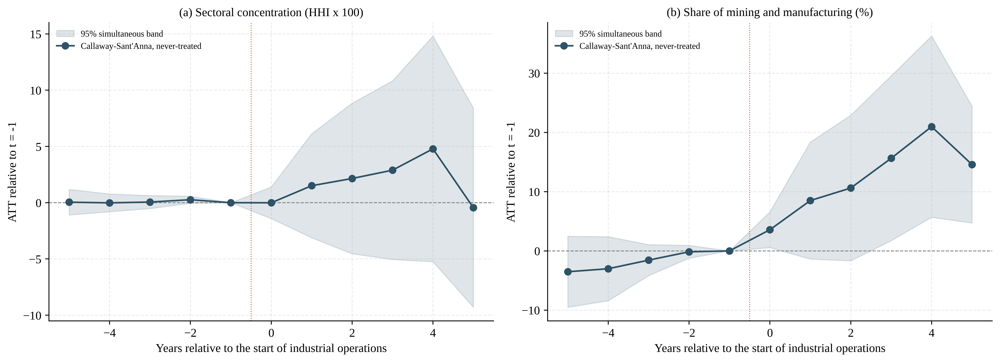

In [55]:
if SECTOR17_OK:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, (y, title_) in zip(axes, [("HHI", "(a) Sectoral concentration (HHI x 100)"),
                                      ("share_BC17", "(b) Share of mining and manufacturing (%)")]):
        es = es17_results[y]["es"]
        ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.axvline(-0.5, color=COLOR_INDUSTRIAL, linestyle=":", linewidth=0.8)
        ax.fill_between(es["e"], es["band_lo"].fillna(0), es["band_hi"].fillna(0), color=COLOR_NONINDUSTRIAL,
                        alpha=0.15, label="95% simultaneous band")
        ax.plot(es["e"], es["att"], "o-", color=COLOR_NONINDUSTRIAL, label="Callaway-Sant'Anna, never-treated")
        ax.set_xlabel("Years relative to the start of industrial operations"); ax.set_ylabel("ATT relative to t = -1")
        ax.set_title(title_, fontsize=11); ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    save_figure(fig, "Figure_7")
    plt.show()

## 12o. Elasticity gap: formal test, confidence intervals and between–within comparison

In [56]:
X_o = data_final[FINAL_X_COLS].assign(const=1.0)
y_o = data_final["log_grdp_current"]
col_o = list(X_o.columns)
v_ind_o = data_final.loc[data_final["industrial_dummy"] == 1, "viirs_mean_radiance"].mean()
v_non_o = data_final.loc[data_final["industrial_dummy"] == 0, "viirs_mean_radiance"].mean()

def vector(col_, weights):
    g = np.zeros(len(col_))
    for k, v in weights.items():
        g[col_.index(k)] = v
    return g

test_o = {
    "Elasticity gap at group means (e_I - e_N)": {"viirs_x_industrial": 1.0, "viirs2": 2 * (v_ind_o - v_non_o)},
    "Elasticity gap at common (pooled) mean": {"viirs_x_industrial": 1.0},
    "Between minus within: NTL x industrial (mean term)": {"viirs_x_industrial_bar": 1.0},
}
rows_o = []
for name, weights in test_o.items():
    g = vector(col_o, weights)
    b_h, t_h, p_h = wild_cluster_bootstrap(y_o, X_o, res_final.theta, g)
    est = float(g @ b_h); se = abs(est / t_h)
    rows_o.append(dict(quantity_=name, estimate_=est, std_error=se, ci_lo=est - 1.96 * se, ci_hi=est + 1.96 * se,
                        p_value_crv1=2 * norm.sf(abs(t_h)), p_value_wcr_bootstrap=p_h))
for v in ["viirs_mean_radiance", "viirs2", "viirs_x_industrial"]:
    g = vector(col_o, {v: 1.0, f"{v}_bar": 1.0})
    est = float(g @ res_final.params[col_o].values)
    se = float(np.sqrt(g @ res_final.cov.loc[col_o, col_o].values @ g))
    rows_o.append(dict(quantity_=f"Between component: {v}", estimate_=est, std_error=se,
                        ci_lo=est - 1.96 * se, ci_hi=est + 1.96 * se,
                        p_value_crv1=2 * norm.sf(abs(est / se)), p_value_wcr_bootstrap=np.nan))
table_o = pd.DataFrame(rows_o)
print(f"Mean ln SOL: industrial {v_ind_o:.3f}, non-industrial {v_non_o:.3f}, difference {v_ind_o - v_non_o:.3f}")
print(table_o.round(4).to_string(index=False))

ci_table5 = []
for name, (est, se, p) in ntl_marginal_effect(res_final, data_final).items():
    ci_table5.append(dict(quantity_=name, estimate_=est, ci_lo=est - 1.96 * se, ci_hi=est + 1.96 * se))
for v in ["industrial_dummy", "viirs_x_industrial", "viirs2"]:
    est, se = res_final.params[v], res_final.std_errors[v]
    ci_table5.append(dict(quantity_=v, estimate_=est, ci_lo=est - 1.96 * se, ci_hi=est + 1.96 * se))
print("\n95% CI (cluster SE) for Table 5:")
print(pd.DataFrame(ci_table5).round(3).to_string(index=False))

Mean ln SOL: industrial 7.050, non-industrial 6.310, difference 0.740
                                         quantity_  estimate_  std_error   ci_lo  ci_hi  p_value_crv1  p_value_wcr_bootstrap
         Elasticity gap at group means (e_I - e_N)     0.1759     0.0497  0.0785 0.2732        0.0004                 0.0003
            Elasticity gap at common (pooled) mean     0.1017     0.0391  0.0251 0.1782        0.0092                 0.0126
Between minus within: NTL x industrial (mean term)    -0.1394     0.1426 -0.4189 0.1401        0.3284                 0.3790
            Between component: viirs_mean_radiance    -0.1516     0.6874 -1.4989 1.1958        0.8255                    NaN
                         Between component: viirs2     0.0495     0.0518 -0.0521 0.1510        0.3399                    NaN
             Between component: viirs_x_industrial    -0.0377     0.1343 -0.3009 0.2255        0.7788                    NaN

95% CI (cluster SE) for Table 5:
                     

## 12p. Residual diagnostics

In [57]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_within = ["viirs_mean_radiance", "viirs2", "viirs_x_industrial"] + CONTROLS_V31
fe_p = PanelOLS(data_cc["log_grdp_current"], data_cc[X_within], entity_effects=True, time_effects=True
                ).fit(cov_type="clustered", cluster_entity=True)
assert abs(fe_p.params["viirs_x_industrial"] - res_final.params["viirs_x_industrial"]) < 1e-8
e_p = fe_p.resids

dd = data_cc[["log_grdp_current"] + X_within].groupby(level=0).diff().dropna()
yrs = pd.get_dummies(dd.index.get_level_values(1), drop_first=True).astype(float); yrs.index = dd.index
o_fd = sm.OLS(dd["log_grdp_current"], pd.concat([dd[X_within], yrs], axis=1)).fit()
u_fd = o_fd.resid.to_frame("u"); u_fd["u_lag"] = u_fd.groupby(level=0)["u"].shift(1); u_fd = u_fd.dropna()
o_w = sm.OLS(u_fd["u"], u_fd[["u_lag"]]).fit(cov_type="cluster",
                                              cov_kwds={"groups": pd.factorize(u_fd.index.get_level_values(0))[0]})
F_w = ((o_w.params["u_lag"] + 0.5) / o_w.bse["u_lag"]) ** 2
p_w = scipy_stats.f.sf(F_w, 1, u_fd.index.get_level_values(0).nunique() - 1)

E = e_p.unstack(0)
N_, T_ = E.shape[1], E.shape[0]
corr_ = E.corr().values; iu = np.triu_indices(N_, 1)
CD = np.sqrt(2 * T_ / (N_ * (N_ - 1))) * corr_[iu].sum()
p_cd = 2 * norm.sf(abs(CD))

s2_i = (E ** 2).mean(); s2 = (E.values ** 2).mean()
V_i = ((E ** 2 - s2_i) ** 2).sum() / (T_ * (T_ - 1))
W_het = (((s2_i - s2) ** 2) / V_i).sum(); p_het = scipy_stats.chi2.sf(W_het, N_)

Z = data_cc[["viirs_mean_radiance", "industrial_dummy"] + CONTROLS_V31 + ["pct_urban"]].copy()
Lc = Z["viirs_mean_radiance"] - Z["viirs_mean_radiance"].mean()
Z["viirs_mean_radiance"] = Lc; Z["viirs2"] = Lc ** 2; Z["viirs_x_industrial"] = Lc * Z["industrial_dummy"]
Z = Z.assign(const=1.0)
vif = {c: variance_inflation_factor(Z.values, i) for i, c in enumerate(Z.columns) if c != "const"}

fe_2w = PanelOLS(data_cc["log_grdp_current"], data_cc[X_within], entity_effects=True, time_effects=True
                 ).fit(cov_type="clustered", cluster_entity=True, cluster_time=True)

table_diag = pd.DataFrame([
    dict(test="Serial correlation (Wooldridge 2002), H0: no AR(1)", statistic=f"F(1,78) = {F_w:.2f}", p_value=p_w,
         note=f"coef. on lagged FD residual = {o_w.params['u_lag']:.3f} (-0.5 under H0)"),
    dict(test="Cross-sectional dependence (Pesaran CD)", statistic=f"CD = {CD:.2f}", p_value=p_cd,
         note=f"mean |rho| = {np.abs(corr_[iu]).mean():.3f}"),
    dict(test="Groupwise heteroskedasticity (modified Wald)", statistic=f"chi2(79) = {W_het:.0f}", p_value=p_het, note=""),
    dict(test="Max VIF (NTL centred)", statistic=f"{max(vif.values()):.2f}", p_value=np.nan,
         note="; ".join(f"{k} {v:.1f}" for k, v in vif.items())),
    dict(test="H2 with two-way clustered SE (regency, year)", statistic=f"{fe_2w.params['viirs_x_industrial']:.3f} "
         f"({fe_2w.std_errors['viirs_x_industrial']:.3f})", p_value=fe_2w.pvalues["viirs_x_industrial"], note=""),
])
print(table_diag.to_string(index=False))

                                              test         statistic      p_value                                                                                                                                                                                                   note
Serial correlation (Wooldridge 2002), H0: no AR(1)   F(1,78) = 96.06 3.044229e-15                                                                                                                                                    coef. on lagged FD residual = 0.473 (-0.5 under H0)
           Cross-sectional dependence (Pesaran CD)         CD = 4.05 5.080114e-05                                                                                                                                                                                     mean |rho| = 0.503
      Groupwise heteroskedasticity (modified Wald) chi2(79) = 120642 0.000000e+00                                                                            

## 12q. Role of mining and manufacturing (B+C)

In [58]:
dq = d17m.copy()
dq["S"] = dq["share_BC17"] / 100
dq["S_bar"] = dq.groupby(level=0)["S"].transform("mean")
dq["S_2015"] = dq.groupby(level=0)["S"].transform("first")
dq["ntl_x_Sbar"] = dq["viirs_mean_radiance"] * dq["S_bar"]
dq["ntl_x_S2015"] = dq["viirs_mean_radiance"] * dq["S_2015"]
TV_Q = ["viirs_mean_radiance", "viirs_x_industrial", "viirs2"] + CONTROLS_V31
rows_q = []
for label, tv, ti, key in [
        ("Base model, same sample (N = 868)", TV_Q, TI_V31, None),
        ("+ NTL x mean B+C share 2015-2025", TV_Q + ["ntl_x_Sbar"], TI_V31 + ["S_bar"], "ntl_x_Sbar"),
        ("+ NTL x 2015 B+C share (pre-determined)", TV_Q + ["ntl_x_S2015"], TI_V31 + ["S_2015"], "ntl_x_S2015")]:
    res, d, X = cre_v31(dq, "log_grdp_current", tv, ti)
    comb = {"NTL x industrial": {"viirs_x_industrial": 1}}
    if key:
        comb[f"NTL x B+C share ({key})"] = {key: 1}
    t = test_v31(res, d, X, "log_grdp_current", comb)
    t.insert(0, "specification", label); rows_q.append(t)
table_q = pd.concat(rows_q, ignore_index=True)
print(table_q.round(4).to_string(index=False))

def group_elasticity(data, y):
    res, d, X = cre_v31(data, y, ["viirs_mean_radiance", "viirs_x_industrial", "viirs2"] + CONTROLS_V31)
    v = d["viirs_mean_radiance"].mean(); b = res.params
    e_non = b["viirs_mean_radiance"] + 2 * b["viirs2"] * v
    return e_non + b["viirs_x_industrial"], e_non

def decomposition(data):
    e = {y: group_elasticity(data, y) for y in ["log_grdp_current", "log_grdp_BC17", "log_grdp_nonBC17"]}
    s_I = data.loc[data["industrial_dummy"] == 1, "share_BC17"].mean() / 100
    s_N = data.loc[data["industrial_dummy"] == 0, "share_BC17"].mean() / 100
    gap_obs = e["log_grdp_current"][0] - e["log_grdp_current"][1]
    contrib_BC = s_I * e["log_grdp_BC17"][0] - s_N * e["log_grdp_BC17"][1]
    contrib_non = (1 - s_I) * e["log_grdp_nonBC17"][0] - (1 - s_N) * e["log_grdp_nonBC17"][1]
    return dict(gap_observed=gap_obs, contribution_BC=contrib_BC, contribution_nonBC=contrib_non,
                gap_predicted=contrib_BC + contrib_non, share_I=s_I, share_N=s_N)

dec = decomposition(dq)
rng_q = np.random.default_rng(2026)
unit_q = dq.index.get_level_values(0).unique()
boot_q = []
for _ in range(499):
    choose = rng_q.choice(unit_q, size=len(unit_q), replace=True)
    part = []
    for j, u in enumerate(choose):
        s = dq.loc[[u]].copy()
        s.index = pd.MultiIndex.from_arrays([[f"{u}#{j}"] * len(s), s.index.get_level_values(1)],
                                            names=dq.index.names)
        part.append(s)
    boot_q.append(decomposition(pd.concat(part)))
boot_q = pd.DataFrame(boot_q)
print("\nDecomposition of the industrial - non-industrial elasticity gap (cluster bootstrap, 499 draws, 95% percentile CI):")
for k in ["gap_observed", "contribution_BC", "contribution_nonBC", "gap_predicted"]:
    lo, hi = np.percentile(boot_q[k], [2.5, 97.5])
    print(f"  {k:20s} {dec[k]:+.3f}  [{lo:+.3f}, {hi:+.3f}]")
print(f"  mean B+C share: industrial {dec['share_I']:.3f}, non-industrial {dec['share_N']:.3f}")
print(f"  share of the gap explained by the B+C component: {dec['contribution_BC'] / dec['gap_observed']:.2f}")

                          specification                     quantity_  estimate_  std_error  p_value_crv1  p_value_wcr_bootstrap   N
      Base model, same sample (N = 868)              NTL x industrial     0.1023     0.0397        0.0100                 0.0145 868
       + NTL x mean B+C share 2015-2025              NTL x industrial    -0.0190     0.0366        0.6042                 0.6335 868
       + NTL x mean B+C share 2015-2025  NTL x B+C share (ntl_x_Sbar)     0.9545     0.1877        0.0000                 0.0001 868
+ NTL x 2015 B+C share (pre-determined)              NTL x industrial     0.0991     0.0459        0.0309                 0.0326 868
+ NTL x 2015 B+C share (pre-determined) NTL x B+C share (ntl_x_S2015)     0.0630     0.3306        0.8489                 0.8688 868



Decomposition of the industrial - non-industrial elasticity gap (cluster bootstrap, 499 draws, 95% percentile CI):
  gap_observed         +0.102  [+0.037, +0.196]
  contribution_BC      +0.131  [+0.062, +0.206]
  contribution_nonBC   +0.002  [-0.023, +0.023]
  gap_predicted        +0.132  [+0.061, +0.213]
  mean B+C share: industrial 0.269, non-industrial 0.098
  share of the gap explained by the B+C component: 1.28


## 12r. Concentration of light within regencies

In [59]:
FILE_CONC = find_file("ntl_regency_concentration")
FILE_GEOM = find_file("regency_geometry")
FILE_RING = find_file("ntl_facility_rings")
conc = pd.read_csv(FILE_CONC)
conc = conc[conc["regency"] != "Danau"].rename(columns={"regency": "regency", "year": "year"})
conc["year"] = conc["year"].astype(int)
assert conc["regency"].nunique() == 79 and len(conc) == 869
check_sol = conc.merge(panel[["regency", "year", "ntl_sum_masked"]], on=["regency", "year"])
print(f"Consistency check, new GEE SOL vs panel SOL: log correlation = "
      f"{np.corrcoef(np.log(check_sol['sol']), np.log(check_sol['ntl_sum_masked']))[0, 1]:.5f}, "
      f"median ratio = {(check_sol['sol'] / check_sol['ntl_sum_masked']).median():.4f}")
conc["bright_share"] = 100 * conc["sol_ge10"] / conc["sol"]
conc["lit_area"] = 100 * conc["n_lit"] / conc["n_px"]
conc = conc.merge(panel.drop_duplicates("regency")[["regency", "industrial_dummy"]],
                  on="regency")
conc["group"] = np.where(conc["industrial_dummy"] == 1, "Industrial", "Non-industrial")
ring_r = conc.groupby(["group", "year"])[["bright_share", "lit_area"]].mean().unstack(0)
print("\nMean share of light from bright pixels (>= 10 nW/cm2/sr) and lit share of area (%):")
print(ring_r.loc[[2015, 2020, 2025]].round(2).to_string())

cs_kons = df_cs_original.merge(conc[["regency", "year", "bright_share", "lit_area"]],
                           on=["regency", "year"], how="left")
assert cs_kons[["bright_share", "lit_area"]].notna().all().all()
r_results = {}
rows_r = []
for y, lab in [("bright_share", "Share of light from bright pixels (%)"), ("lit_area", "Lit share of regency area (%)")]:
    r = cs_structure(cs_kons, y)
    r_results[y] = r
    rows_r.append(dict(outcome=lab, **summary_cs(r)))
table_r = pd.DataFrame(rows_r)
print("\nCallaway-Sant'Anna (15 regencies/cities starting 2016-2024 vs 42 never treated, 2015-2025):")
print(table_r.round(4).to_string(index=False))
for y in ["bright_share", "lit_area"]:
    print(f"\nEvent-time profile ({y}):")
    print(r_results[y]["es"].round(3).to_string(index=False))

Consistency check, new GEE SOL vs panel SOL: log correlation = 0.99993, median ratio = 0.9990

Mean share of light from bright pixels (>= 10 nW/cm2/sr) and lit share of area (%):
      bright_share                  lit_area               
group   Industrial Non-industrial Industrial Non-industrial
year                                                       
2015         15.11           8.61      13.31          15.65
2020         20.83           8.87      16.81          20.07
2025         22.49          12.41      21.17          22.85



Callaway-Sant'Anna (15 regencies/cities starting 2016-2024 vs 42 never treated, 2015-2025):
                              outcome    ATT     SE      p  pre_band_excl_0
Share of light from bright pixels (%) 4.9566 2.2871 0.0302                0
        Lit share of regency area (%) 1.5468 2.5074 0.5373                0

Event-time profile (bright_share):
 e     att    se  band_lo  band_hi
-5 -13.462 8.044  -31.718    4.793
-4  -2.908 7.953  -20.958   15.142
-3  -6.201 3.416  -13.953    1.552
-2  -6.086 3.536  -14.112    1.940
-1   0.000   NaN      NaN      NaN
 0   2.736 1.242   -0.081    5.554
 1   1.780 2.576   -4.067    7.627
 2   2.008 1.861   -2.215    6.231
 3   4.757 2.899   -1.822   11.336
 4   6.092 2.789   -0.238   12.421
 5   5.533 3.735   -2.944   14.010

Event-time profile (lit_area):
 e    att    se  band_lo  band_hi
-5  0.906 0.634   -0.553    2.365
-4  0.420 0.586   -0.928    1.768
-3 -0.031 0.568   -1.339    1.277
-2  0.360 0.276   -0.275    0.996
-1  0.000   NaN      

## 12s. Light around nickel smelters and estates

In [60]:
geom = pd.read_csv(FILE_GEOM)
geom = geom[geom["regency"] != "Danau"].set_index("regency")
neighbours_ = {k: [n for n in str(v).split(";") if n and n != "Danau" and n != "nan"]
            for k, v in geom["neighbours"].items()}
ring = pd.read_csv(FILE_RING)
ring["year"] = ring["year"].astype(int)
ring["host"] = ring["host"].astype(str)
ring = ring[ring["spec"] == "c5_r20"].copy()
ring["zone"] = ring["zone"].map({"core": "core_0_5km", "ring": "ring_5_20km", "rest_of_host": "rest_of_host"})
FACILITY_START = {"NS4": 2022}
sol_panel = panel.set_index(["regency", "year"])["ntl_sum_masked"]
start_year_ = panel.drop_duplicates("regency").set_index("regency")["start_year"]

rows_s = []
for (fid, host), r in ring.groupby(["fid", "host"]):
    z = r.pivot(index="year", columns="zone", values="sol")
    z["neighbours"] = [sum(sol_panel[(n, t)] for n in neighbours_[host]) for t in z.index]
    z["host_total"] = z[["core_0_5km", "ring_5_20km", "rest_of_host"]].sum(axis=1)
    for t in z.index:
        rows_s.append(dict(fid=fid, host=host, facility=r["facility"].iloc[0], year=t,
                            start=int(FACILITY_START.get(fid, start_year_[host])), **z.loc[t].to_dict()))
ms = pd.DataFrame(rows_s)
ms["core_share_host"] = 100 * ms["core_0_5km"] / ms["host_total"]
ms["core_ring_share_host"] = 100 * (ms["core_0_5km"] + ms["ring_5_20km"]) / ms["host_total"]
check_host = ms.merge(sol_panel.rename("sol_panel").reset_index(),
                    left_on=["host", "year"], right_on=["regency", "year"])
print(f"Check: sum of 3 zones vs regency SOL in the panel, median ratio = "
      f"{(check_host['host_total'] / check_host['sol_panel']).median():.3f} "
      f"(min {(check_host['host_total'] / check_host['sol_panel']).min():.3f})")

z_list = ["core_0_5km", "ring_5_20km", "rest_of_host", "neighbours"]
start = ms[ms["year"] == 2015].set_index("fid"); end = ms[ms["year"] == 2025].set_index("fid")
table_s = pd.DataFrame({"host": start["host"], "start": start["start"]})
for zname in z_list:
    table_s[f"dlog_{zname}"] = np.log(end[zname]) - np.log(start[zname])
table_s["core_share_2015"] = start["core_share_host"]; table_s["core_share_2025"] = end["core_share_host"]
table_s["core_ring_share_2025"] = end["core_ring_share_host"]
table_s = table_s.replace([np.inf, -np.inf], np.nan)
compare = panel[panel["industrial_dummy"] == 0].pivot(index="regency", columns="year", values="ntl_sum_masked")
dlog_non = float((np.log(compare[2025]) - np.log(compare[2015])).mean())
print(f"\nChange in ln SOL 2015-2025 (benchmark: non-industrial mean = {dlog_non:.3f}):")
print(table_s.round(3).to_string())

new = ms[(ms["start"] > 2015) & (ms["start"] <= 2024)].copy()
new["e"] = new["year"] - new["start"]
for zname in z_list:
    base = new[new["e"] == -1].set_index("fid")[zname]
    new[f"idx_{zname}"] = np.log(new[zname]) - np.log(new["fid"].map(base))
new = new.replace([np.inf, -np.inf], np.nan)
compare_t = np.log(compare).mean()
new["idx_control"] = new["year"].map(compare_t) - (new["start"] - 1).map(compare_t)
prof_s = new[(new["e"] >= -4) & (new["e"] <= 5)].groupby("e")[[f"idx_{z}" for z in z_list] + ["idx_control"]].mean()
n_s = new[(new["e"] >= -4) & (new["e"] <= 5)].groupby("e")["fid"].nunique()
print(f"\nEstates starting operation 2016-2024: {sorted(new['host'].unique())}")
print("Mean change in ln SOL relative to t = -1 by zone (last column: non-industrial mean in the same calendar years):")
print(prof_s.assign(n_estates=n_s).round(3).to_string())

rows_c = []
for fid, s in new.groupby("fid"):
    e_max = min(3, s["e"].max())
    a = s[s["e"] == e_max].iloc[0]
    rows_c.append(dict(fid=fid, host=a["host"], e=e_max, **{z: a[f"idx_{z}"] for z in z_list}, control=a["idx_control"]))
print("\nChange in ln SOL from t=-1 to t=+3 (or last year) by estate:")
print(pd.DataFrame(rows_c).round(3).to_string(index=False))

import itertools

def sign_flip(x):
    x = np.asarray(x, float)
    flips = np.array(list(itertools.product([1, -1], repeat=len(x))))
    return x.mean(), float((np.abs((flips * x).mean(axis=1)) >= abs(x.mean()) - 1e-12).mean())

est = pd.DataFrame(rows_c)
test_s = pd.DataFrame([dict(comparison=f"{a} - {b}", n_estates=len(est), **dict(zip(["mean_difference", "p_sign_flip"], sign_flip(est[a] - est[b]))))
                       for a, b in [("core_0_5km", "control"), ("ring_5_20km", "control"), ("rest_of_host", "control"),
                                    ("neighbours", "control"), ("core_0_5km", "rest_of_host"), ("ring_5_20km", "rest_of_host")]])
print("\nExact sign-flip test across estates (change from t-1 to t+3 or last year):")
print(test_s.round(3).to_string(index=False))

Check: sum of 3 zones vs regency SOL in the panel, median ratio = 1.001 (min 0.964)

Change in ln SOL 2015-2025 (benchmark: non-industrial mean = 1.119):
                  host  start  dlog_core_0_5km  dlog_ring_5_20km  dlog_rest_of_host  dlog_neighbours  core_share_2015  core_share_2025  core_ring_share_2025
fid                                                                                                                                                         
NE1           Morowali   2015            2.613             5.246              2.661            0.200           76.871           60.433                82.575
NE2   Halmahera Tengah   2020            5.587             8.320              2.346            2.841           15.704           26.501                94.612
NE3  Halmahera Selatan   2020            5.063             3.820              1.689            3.220           20.773           83.045                89.976
NE4             Konawe   2019            4.610             2.

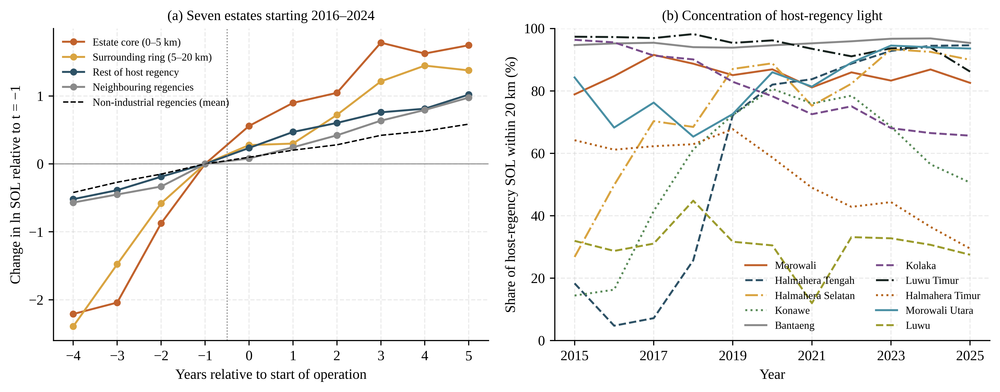

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
ax = axes[0]
color_z = {"core_0_5km": COLOR_INDUSTRIAL, "ring_5_20km": "#D9A441", "rest_of_host": COLOR_NONINDUSTRIAL, "neighbours": "#8A8A8A"}
label_z = {"core_0_5km": "Estate core (0–5 km)", "ring_5_20km": "Surrounding ring (5–20 km)",
           "rest_of_host": "Rest of host regency", "neighbours": "Neighbouring regencies"}
for zname in z_list:
    ax.plot(prof_s.index, prof_s[f"idx_{zname}"], "o-", color=color_z[zname], ms=4, lw=1.4, label=label_z[zname])
ax.plot(prof_s.index, prof_s["idx_control"], "--", color="black", lw=1.0, label="Non-industrial regencies (mean)")
ax.axvline(-0.5, color="gray", ls=":", lw=0.8); ax.axhline(0, color="gray", lw=0.6)
ax.set_xticks(range(-4, 6)); ax.set_xlabel("Years relative to start of operation")
ax.set_ylabel("Change in ln SOL relative to t = −1")
ax.set_title("(a) Seven estates starting 2016–2024", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left")
ax = axes[1]
line_styles = ["-", "--", "-.", ":", "-", "--", "-.", ":", "-", "--"]
line_colors = ["#C1622D", "#2E5266", "#D9A441", "#5B8C5A", "#8A8A8A", "#7A4E8C", "#182420", "#B5651D", "#4A90A4", "#9C9C2E"]
for k, (fid, s) in enumerate(ms.sort_values("year").groupby("fid")):
    ax.plot(s["year"], s["core_ring_share_host"], line_styles[k], color=line_colors[k], lw=1.4, label=s["host"].iloc[0])
ax.set_ylim(0, 100); ax.set_xticks(range(2015, 2026, 2))
ax.set_xlabel("Year"); ax.set_ylabel("Share of host-regency SOL within 20 km (%)")
ax.set_title("(b) Concentration of host-regency light", fontsize=10)
ax.legend(fontsize=7.5, loc="lower right", ncol=2)
for a in axes:
    a.tick_params(labelsize=10); a.xaxis.label.set_size(10); a.yaxis.label.set_size(10)
fig.tight_layout()
save_figure(fig, "Figure_8")
plt.show()

### Sensitivity to the ring radii (Table 17)

In [62]:
r2 = pd.read_csv(FILE_RING)
r2["year"] = r2["year"].astype(int)
host_sol = ring.groupby(["fid", "year"])["sol"].sum().rename("host_sol").reset_index()
w2 = (r2.pivot_table(index=["spec", "fid", "host", "year"], columns="zone", values="sol").reset_index()
      .merge(host_sol, on=["fid", "year"]))
w2["ring"] = w2["host_sol"] - w2["core"] - w2["rest_of_host"]
w2["neighbours"] = [sum(sol_panel[(n, t)] for n in neighbours_[h]) for h, t in zip(w2["host"], w2["year"])]
w2["start"] = [int(FACILITY_START.get(f, start_year_[h])) for f, h in zip(w2["fid"], w2["host"])]
w2["within_outer"] = 100 * (w2["core"] + w2["ring"]) / w2["host_sol"]
w2["core_share"] = 100 * w2["core"] / w2["host_sol"]
y25 = w2[w2["year"] == 2025]
new2 = w2[(w2["start"] > 2015) & (w2["start"] <= 2024)].copy()
new2["e"] = new2["year"] - new2["start"]
base2 = new2[new2["e"] == -1].set_index(["spec", "fid"])
for zname in ["core", "ring", "rest_of_host", "neighbours"]:
    new2[f"idx_{zname}"] = np.log(new2[zname]) - np.log([base2.loc[(s, f), zname] for s, f in zip(new2["spec"], new2["fid"])])
new2 = new2.replace([np.inf, -np.inf], np.nan)
e3 = new2[new2["e"] == 3].groupby("spec")[["idx_core", "idx_ring", "idx_rest_of_host", "idx_neighbours"]].mean()
table_a9 = (y25.groupby("spec")[["within_outer", "core_share"]].agg(["median", "min", "max"]))
table_a9.columns = [f"{a}_{b}" for a, b in table_a9.columns]
table_a9 = table_a9.join(e3).loc[["c3_r20", "c5_r20", "c10_r20", "c5_r30"]]
print("Table 17. Sensitivity to the ring radii, ten sites (shares in 2025; changes from t-1 to t+3, estates starting 2016-2024):")
print(table_a9.round(2).to_string())
print(f"Non-industrial regencies over the same years: {new2[new2['e'] == 3].drop_duplicates('fid')['year'].map(compare_t).sub((new2[new2['e'] == 3].drop_duplicates('fid')['start'] - 1).map(compare_t)).mean():.2f}")

Table 17. Sensitivity to the ring radii, ten sites (shares in 2025; changes from t-1 to t+3, estates starting 2016-2024):
         within_outer_median  within_outer_min  within_outer_max  core_share_median  core_share_min  core_share_max  idx_core  idx_ring  idx_rest_of_host  idx_neighbours
spec                                                                                                                                                                     
c3_r20                 84.38             27.50             95.37              12.69            3.76           67.83      1.71      1.57              0.76            0.64
c5_r20                 84.38             27.50             95.37              27.20            8.89           83.04      1.78      1.21              0.76            0.64
c10_r20                84.38             27.50             95.37              53.70           13.78           88.09      1.94      0.80              0.76            0.64
c5_r30                 87.82

## 12t. Local linkages and spillovers

In [63]:
LINK = ["F", "G", "H", "I"]
s17t = s17[["regency", "year", "B", "C"] + KAT17].copy()
s17t = s17t.loc[:, ~s17t.columns.duplicated()]
s17t["tot17"] = s17t[KAT17].sum(axis=1, min_count=17)
s17t["log_nonBC17"] = np.log((s17t["tot17"] - s17t["B"] - s17t["C"]) / 1000)
s17t["log_link17"] = np.log(s17t[LINK].sum(axis=1) / 1000)
s17t["log_A17"] = np.log(s17t["A"] / 1000)

cs_host = df_cs_original.merge(s17t[["regency", "year", "log_nonBC17", "log_link17", "log_A17"]],
                           on=["regency", "year"], how="left")
cs_host = cs_host[cs_host["year"] <= 2024]
assert cs_host[["log_nonBC17", "log_link17", "log_A17"]].notna().all().all()
rows_t = []
t_results = {}
for y, lab in [("log_nonBC17", "Host: ln GRDP excl. B+C"),
               ("log_link17", "Host: ln GRDP of construction, trade, transport, accommodation"),
               ("log_A17", "Host: ln GRDP of agriculture")]:
    r = cs_structure(cs_host, y); t_results[y] = r
    rows_t.append(dict(outcome=lab, n_treated=15, **summary_cs(r)))

start_new = start_year_[(start_year_ > 2015) & (start_year_ <= 2024)]
non_ind = sorted(panel.loc[panel["industrial_dummy"] == 0, "regency"].unique())
g_nb = {}
for k in non_ind:
    year_nb = [start_new[n] for n in neighbours_.get(k, []) if n in start_new.index]
    g_nb[k] = int(min(year_nb)) if year_nb else 0
dt = df.loc[df["regency"].isin(non_ind)].copy()
dt["log_ntl"] = dt["viirs_mean_radiance"]
dt = dt.merge(s17t[["regency", "year", "log_nonBC17"]], on=["regency", "year"], how="left")
dt["g"] = dt["regency"].map(g_nb).astype(int)
dt["id"] = pd.factorize(dt["regency"])[0] + 1
dt = dt[dt["year"] <= 2024]
n_nb = int((pd.Series(g_nb) > 0).sum())
print(f"Non-industrial regencies/cities bordering a new estate: {n_nb}; never-treated comparison: "
      f"{int((pd.Series(g_nb) == 0).sum())}")
print("  ", {k: v for k, v in g_nb.items() if v > 0})
for y, lab in [("log_grdp_current", "Neighbours: ln GRDP"), ("log_nonBC17", "Neighbours: ln GRDP excl. B+C"),
               ("log_ntl", "Neighbours: ln SOL")]:
    r = cs_structure(dt, y); t_results["nb_" + y] = r
    rows_t.append(dict(outcome=lab, n_treated=n_nb, **summary_cs(r)))
table_t = pd.DataFrame(rows_t)
print("\nCallaway-Sant'Anna (never-treated, 2015-2024):")
print(table_t.round(4).to_string(index=False))

Non-industrial regencies/cities bordering a new estate: 25; never-treated comparison: 17
   {'Barru': 2018, 'Bolaang Mongondow Timur': 2020, 'Bulukumba': 2018, 'Buton Selatan': 2022, 'Buton Utara': 2022, 'Enrekang': 2018, 'Gowa': 2018, 'Halmahera Barat': 2023, 'Kepulauan Sula': 2018, 'Kolaka Timur': 2019, 'Kota Baubau': 2022, 'Kota Kendari': 2019, 'Kota Palopo': 2024, 'Kota Parepare': 2018, 'Kota Tidore Kepulauan': 2020, 'Minahasa': 2020, 'Minahasa Tenggara': 2020, 'Muna': 2022, 'Parigi Moutong': 2021, 'Sigi': 2017, 'Sinjai': 2018, 'Soppeng': 2018, 'Tana Toraja': 2024, 'Tojo Una-Una': 2016, 'Wajo': 2018}



Callaway-Sant'Anna (never-treated, 2015-2024):
                                                       outcome  n_treated     ATT     SE      p  pre_band_excl_0
                                       Host: ln GRDP excl. B+C         15 -0.0198 0.0288 0.4913                0
Host: ln GRDP of construction, trade, transport, accommodation         15 -0.0012 0.0602 0.9840                0
                                  Host: ln GRDP of agriculture         15 -0.0476 0.0191 0.0128                1
                                           Neighbours: ln GRDP         25 -0.0055 0.0114 0.6293                0
                                 Neighbours: ln GRDP excl. B+C         25 -0.0015 0.0117 0.8949                0
                                            Neighbours: ln SOL         25 -0.0817 0.0684 0.2323                0


## 12u. Geographic concentration of mining and manufacturing

In [64]:
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())

rows_u = []
for t in [2015, 2020, 2024, 2025]:
    s = s17t[s17t["year"] == t].dropna(subset=["tot17"])
    bc = (s["B"] + s["C"]).values; tot = s["tot17"].values
    order = np.sort(bc)[::-1]
    nickel = s["regency"].isin(["Morowali", "Morowali Utara", "Konawe", "Kolaka", "Luwu Timur", "Bantaeng",
                                              "Halmahera Tengah", "Halmahera Selatan", "Halmahera Timur", "Luwu"])
    rows_u.append(dict(year=t, n=len(s), top5_share_BC=100 * order[:5].sum() / bc.sum(),
                        nickel10_share_BC=100 * bc[nickel.values].sum() / bc.sum(),
                        nickel10_share_GRDP=100 * tot[nickel.values].sum() / tot.sum(),
                        gini_BC=gini(bc), gini_GRDP=gini(tot)))
table_u = pd.DataFrame(rows_u)
print(table_u.round(3).to_string(index=False))

 year  n  top5_share_BC  nickel10_share_BC  nickel10_share_GRDP  gini_BC  gini_GRDP
 2015 79         49.152             26.505               13.274    0.688      0.504
 2020 79         55.202             41.292               16.969    0.725      0.522
 2024 79         58.662             58.981               25.161    0.784      0.544
 2025 78         59.082             61.444               26.977    0.789      0.550


### Results file

In [65]:
import json
def _r(x, k=3):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), k)
revision_summary = {
    "o": table_o.to_dict(orient="records"),
    "ci_table5": pd.DataFrame(ci_table5).to_dict(orient="records"),
    "diag": table_diag.to_dict(orient="records"),
    "vif": {k: _r(v, 2) for k, v in vif.items()},
    "q": table_q.to_dict(orient="records"),
    "dec": {k: _r(v, 4) for k, v in dec.items()},
    "dec_ci": {k: [_r(np.percentile(boot_q[k], 2.5), 4), _r(np.percentile(boot_q[k], 97.5), 4)]
               for k in ["gap_observed", "contribution_BC", "contribution_nonBC", "gap_predicted"]},
    "r_group": {f"{a}|{b}|{t}": _r(ring_r.loc[t, (a, b)]) for t in [2015, 2020, 2025] for (a, b) in ring_r.columns},
    "r_cs": table_r.to_dict(orient="records"),
    "s_table": table_s.reset_index().to_dict(orient="records"),
    "s_profile": prof_s.reset_index().to_dict(orient="records"),
    "s_dlog_non": dlog_non,
    "t": table_t.to_dict(orient="records"),
    "t_neigh": {k: v for k, v in g_nb.items() if v > 0},
    "u": table_u.to_dict(orient="records"),
}
with open("revision_results.json", "w") as f:
    json.dump(revision_summary, f, indent=1, default=float)
print("Saved: revision_results.json")

Saved: revision_results.json


## 13. Nowcasting 2025 and forecasting 2026

### 13a. Dynamic nowcast

In [66]:
from sklearn.model_selection import ParameterGrid

def make_pipeline(estimator, scale):
    steps = [("scaler", StandardScaler())] if scale else []
    steps.append(("model", estimator))
    return Pipeline(steps)

def smape(actual, prediction):
    a, f = np.asarray(actual, float), np.asarray(prediction, float)
    return 100 * np.mean(2 * np.abs(f - a) / (np.abs(a) + np.abs(f)))

dyn = panel.sort_values(["regency", "year"]).copy()
dyn["ly"] = np.log(dyn["grdp_current_bn"])
dyn["ntl"] = np.log(dyn["viirs_mean_radiance"])
dyn["dens"] = np.log(dyn["pop_density_per_km2"])
dyn["prec"] = np.log(dyn["precip_annual_mm"])
gk = dyn.groupby("regency")
dyn["ly_lag"] = gk["ly"].shift(1)
dyn["growth"] = dyn["ly"] - dyn["ly_lag"]
dyn["growth_lag"] = gk["growth"].shift(1)
dyn["growth_mean_past"] = gk["growth"].transform(lambda s: s.shift(1).expanding().mean())
for c in ["ntl", "dens", "prec", "tmin_mean_C", "tmax_mean_C"]:
    dyn[f"d_{c}"] = dyn[c] - gk[c].shift(1)
dyn["d_ntl_x_ind"] = dyn["d_ntl"] * dyn["industrial_dummy"]
dyn["d_ntl_yearmean"] = dyn.groupby("year")["d_ntl"].transform("mean")
dyn["ntl_lag"] = gk["ntl"].shift(1)
dyn["d_ntl_lag"] = gk["d_ntl"].shift(1)
dyn["d_ntl_lag_x_ind"] = dyn["d_ntl_lag"] * dyn["industrial_dummy"]
dyn["dens_lag"] = gk["dens"].shift(1)
dyn["crops_lag"] = gk["crops_frac_mean"].shift(1)

FEATURES_NOWCAST = ["d_ntl", "ntl", "d_ntl_x_ind", "industrial_dummy", "d_dens", "dens", "d_prec",
                 "d_tmin_mean_C", "d_tmax_mean_C", "crops_frac_mean", "growth_lag",
                 "growth_mean_past", "d_ntl_yearmean"]
FEATURES_FORECAST = ["d_ntl_lag", "ntl_lag", "d_ntl_lag_x_ind", "industrial_dummy", "dens_lag",
                  "crops_lag", "growth_lag", "growth_mean_past"]
without_ntl = lambda features: [f for f in features if "ntl" not in f]

CV_YEARS_DYN = [2020, 2021, 2022, 2023, 2024]
TEST_YEAR = 2025

GRID_DYN = {
    "Ridge Regression": (make_pipeline(Ridge(), scale=True), {"model__alpha": [1, 10, 100, 1000, 5000]}),
    "K-Nearest Neighbours": (make_pipeline(KNeighborsRegressor(), scale=True),
                              {"model__n_neighbors": [20, 40, 80, 120]}),
    "Random Forest": (make_pipeline(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), scale=False),
                       {"model__max_depth": [2, 3, 5], "model__min_samples_leaf": [10, 20, 40]}),
    "Support Vector Machine": (make_pipeline(SVR(), scale=True),
                                {"model__C": [0.01, 0.1, 1], "model__epsilon": [0.01, 0.05]}),
    "Artificial Neural Network": (make_pipeline(MLPRegressor(solver="lbfgs", max_iter=3000, random_state=42), scale=True),
                                   {"model__hidden_layer_sizes": [(8,), (16,)], "model__alpha": [1.0, 10.0, 50.0]}),
}
if HAS_XGB:
    GRID_DYN["XGBoost"] = (make_pipeline(XGBRegressor(random_state=42, verbosity=0, subsample=0.8, n_jobs=4), scale=False),
                           {"model__n_estimators": [100, 300], "model__max_depth": [1, 2],
                            "model__learning_rate": [0.03, 0.1], "model__min_child_weight": [10, 20]})

def rolling_prediction(estimator, features, data, year_list):
    excl = []
    for T in year_list:
        train_, test = data[data["year"] < T], data[data["year"] == T]
        m = clone(estimator).fit(train_[features], train_["growth"])
        excl.append(test.assign(g_hat=m.predict(test[features])))
    return pd.concat(excl)

def smape_from(pred, cols_g="g_hat"):
    return smape(np.exp(pred["ly"]), np.exp(pred["ly_lag"] + pred[cols_g]))

def mse_from(pred, cols_g="g_hat"):
    return float(np.mean((pred["ly"] - pred["ly_lag"] - pred[cols_g]) ** 2))

def tuning_rolling(features, data):
    results, best = [], {}
    for name, (pipe, grid) in GRID_DYN.items():
        score_min, param_min = np.inf, None
        for prm in ParameterGrid(grid):
            P = rolling_prediction(clone(pipe).set_params(**prm), features, data, CV_YEARS_DYN)
            s = mse_from(P)
            if s < score_min:
                score_min, param_min, smape_min = s, prm, smape_from(P)
        best[name] = clone(pipe).set_params(**param_min)
        results.append(dict(algorithm=name, cv_mse_log=score_min, cv_smape=smape_min, best_params=str(param_min)))
    return pd.DataFrame(results).sort_values("cv_mse_log").reset_index(drop=True), best

data_nowcast = dyn.dropna(subset=FEATURES_NOWCAST + ["growth"]).copy()
print("dynamic model rows (nowcast):", len(data_nowcast), "| years:", sorted(data_nowcast["year"].unique()))

dynamic model rows (nowcast): 711 | years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [67]:
from sklearn.model_selection import ParameterGrid

table_tuning_ntl, model_dyn_ntl = tuning_rolling(FEATURES_NOWCAST, data_nowcast)
table_tuning_nontl, model_dyn_nontl = tuning_rolling(without_ntl(FEATURES_NOWCAST), data_nowcast)

def cv_candidates(model_dict, features, data, label):
    rows, pred_cache = [], {}
    for name, est in model_dict.items():
        P = rolling_prediction(est, features, data, CV_YEARS_DYN)
        pred_cache[name] = P
        rows.append(dict(candidates=f"{name} [{label}]", cv_mse_log=mse_from(P),
                          cv_r2_growth=r2_score(P["growth"], P["g_hat"]), cv_smape=smape_from(P)))
        Pk = P.assign(g_comb=(P["g_hat"] + P["growth_mean_past"]) / 2)
        rows.append(dict(candidates=f"{name} + drift (avg) [{label}]", cv_mse_log=mse_from(Pk, "g_comb"),
                          cv_r2_growth=r2_score(Pk["growth"], Pk["g_comb"]), cv_smape=smape_from(Pk, "g_comb")))
    return rows, pred_cache

rows_ntl, cache_ntl = cv_candidates(model_dyn_ntl, FEATURES_NOWCAST, data_nowcast, "with NTL")
rows_nontl, cache_nontl = cv_candidates(model_dyn_nontl, without_ntl(FEATURES_NOWCAST), data_nowcast, "without NTL")

def rows_naive_from(data):
    cv = data[data["year"].isin(CV_YEARS_DYN)].assign(g_rw=0.0)
    excl = []
    for name, col_ in [("Naive: random walk", "g_rw"), ("Naive: drift (past mean growth)", "growth_mean_past")]:
        excl.append(dict(candidates=name, cv_mse_log=mse_from(cv, col_),
                           cv_r2_growth=r2_score(cv["growth"], cv[col_]), cv_smape=smape_from(cv, col_)))
    return excl

rows_naive = rows_naive_from(data_nowcast)
table_nowcast_candidates = (pd.DataFrame(rows_ntl + rows_nontl + rows_naive)
                          .sort_values("cv_mse_log").reset_index(drop=True))
print("Tuning by algorithm (rolling origin 2020-2024, criterion MSE of ln GRDP, with NTL):")
print(table_tuning_ntl.to_string(index=False))
print("\n=== All nowcast candidates, sorted by CV MSE of ln GRDP (selection rule fixed before seeing 2025) ===")
print(table_nowcast_candidates.round(5).to_string(index=False))

NOWCAST_CANDIDATES = table_nowcast_candidates.iloc[0]["candidates"]
print(f"\n>>> Selected nowcast candidate (lowest CV MSE): {NOWCAST_CANDIDATES}")

Tuning by algorithm (rolling origin 2020-2024, criterion MSE of ln GRDP, with NTL):
                algorithm  cv_mse_log  cv_smape                                                                                                     best_params
         Ridge Regression    0.006140  4.646283                                                                                             {'model__alpha': 1}
                  XGBoost    0.006444  4.462141 {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__min_child_weight': 20, 'model__n_estimators': 300}
     K-Nearest Neighbours    0.006448  4.217250                                                                                      {'model__n_neighbors': 20}
Artificial Neural Network    0.006877  4.331073                                                      {'model__alpha': 10.0, 'model__hidden_layer_sizes': (16,)}
            Random Forest    0.007054  4.555291                                                          {'model__ma

In [68]:
def candidate_prediction(candidates, train_, test, model_ntl, model_nontl, features_ntl, features_nontl):
    if candidates.startswith("Naive: random walk"):
        return np.zeros(len(test))
    if candidates.startswith("Naive: drift"):
        return test["growth_mean_past"].values
    use_ntl = "[with NTL]" in candidates
    name = candidates.split(" [")[0].replace(" + drift (avg)", "")
    est = (model_ntl if use_ntl else model_nontl)[name]
    features = features_ntl if use_ntl else features_nontl
    g = clone(est).fit(train_[features], train_["growth"]).predict(test[features])
    if "+ drift (avg)" in candidates:
        g = (g + test["growth_mean_past"].values) / 2
    return g

train_nc = data_nowcast[data_nowcast["year"] < TEST_YEAR]
test_nc = data_nowcast[data_nowcast["year"] == TEST_YEAR].copy()
args_nc = (model_dyn_ntl, model_dyn_nontl, FEATURES_NOWCAST, without_ntl(FEATURES_NOWCAST))

test_nc["g_selected"] = candidate_prediction(NOWCAST_CANDIDATES, train_nc, test_nc, *args_nc)
test_nc["g_drift"] = test_nc["growth_mean_past"]
test_nc["g_rw"] = 0.0
if "[with NTL]" in NOWCAST_CANDIDATES:
    ABLATION_CANDIDATES = NOWCAST_CANDIDATES.replace("[with NTL]", "[without NTL]")
    test_nc["g_ablation"] = candidate_prediction(ABLATION_CANDIDATES, train_nc, test_nc, *args_nc)
else:
    ABLATION_CANDIDATES = None

for k in ["selected", "drift", "rw"] + (["ablation"] if ABLATION_CANDIDATES else []):
    test_nc[f"grdp_{k}"] = np.exp(test_nc["ly_lag"] + test_nc[f"g_{k}"])

def summary(sub, k):
    return dict(r2_log=r2_score(sub["ly"], sub["ly_lag"] + sub[f"g_{k}"]),
                mse_log=float(np.mean((sub["ly"] - sub["ly_lag"] - sub[f"g_{k}"]) ** 2)),
                smape=smape(sub["grdp_current_bn"], sub[f"grdp_{k}"]),
                r2_growth=r2_score(sub["growth"], sub[f"g_{k}"]),
                mae_bn=(sub[f"grdp_{k}"] - sub["grdp_current_bn"]).abs().mean())

label_k = {"selected": f"Selected: {NOWCAST_CANDIDATES}", "ablation": f"Same, without NTL: {ABLATION_CANDIDATES}",
           "drift": "Naive: drift (past mean growth)", "rw": "Naive: random walk"}
rows = []
for k in ["selected", "ablation", "drift", "rw"]:
    if f"grdp_{k}" not in test_nc:
        continue
    for grp, lab in [(None, "All (79)"), (1, f"Industrial ({int(dyn.groupby('regency')['industrial_dummy'].first().sum())})"),
                 (0, f"Non-industrial ({79 - int(dyn.groupby('regency')['industrial_dummy'].first().sum())})")]:
        sub = test_nc if grp is None else test_nc[test_nc["industrial_dummy"] == grp]
        rows.append(dict(model=label_k[k], group=lab, **summary(sub, k)))
table_nowcast_dyn = pd.DataFrame(rows)
print(f"=== Final nowcast test {TEST_YEAR} (used once, not used for model selection) ===")
print(table_nowcast_dyn.round(5).to_string(index=False))

err = lambda k: np.abs(test_nc["ly"] - (test_nc["ly_lag"] + test_nc[f"g_{k}"]))
if NOWCAST_CANDIDATES.startswith("Naive"):
    print("\nThe selected candidate is a naive benchmark -> test against naive not applicable.")
else:
    stat, p_w = scipy_stats.wilcoxon(err("selected"), err("drift"))
    print(f"\nWilcoxon signed-rank |error| selected vs drift: p = {p_w:.4f} "
          f"(median difference = {np.median(err('selected') - err('drift')):+.5f} log points)")
    if ABLATION_CANDIDATES:
        stat2, p_w2 = scipy_stats.wilcoxon(err("selected"), err("ablation"))
        print(f"Wilcoxon signed-rank |error| with vs without NTL: p = {p_w2:.4f}")

=== Final nowcast test 2025 (used once, not used for model selection) ===
                                                          model               group  r2_log  mse_log    smape  r2_growth     mae_bn
            Selected: Ridge Regression + drift (avg) [with NTL]            All (79) 0.99671  0.00306  2.70604    0.38712  941.09755
            Selected: Ridge Regression + drift (avg) [with NTL]     Industrial (37) 0.99318  0.00617  4.13095    0.36939 1813.40756
            Selected: Ridge Regression + drift (avg) [with NTL] Non-industrial (42) 0.99950  0.00031  1.45077   -0.79580  172.63397
Same, without NTL: Ridge Regression + drift (avg) [without NTL]            All (79) 0.99672  0.00305  2.38114    0.38828  859.31702
Same, without NTL: Ridge Regression + drift (avg) [without NTL]     Industrial (37) 0.99302  0.00632  3.89934    0.35477 1686.16148
Same, without NTL: Ridge Regression + drift (avg) [without NTL] Non-industrial (42) 0.99972  0.00017  1.04368   -0.00134  130.90642
  

In [69]:
if ABLATION_CANDIDATES:
    algo_name = NOWCAST_CANDIDATES.split(" [")[0].replace(" + drift (avg)", "")
    comb = "+ drift (avg)" in NOWCAST_CANDIDATES
    Pn, Pt = cache_ntl[algo_name].copy(), cache_nontl[algo_name].copy()
    if comb:
        Pn["g_hat"] = (Pn["g_hat"] + Pn["growth_mean_past"]) / 2
        Pt["g_hat"] = (Pt["g_hat"] + Pt["growth_mean_past"]) / 2
    rows = []
    for grp, lab in [(1, "Industrial"), (0, "Non-industrial")]:
        a, b = Pn[Pn["industrial_dummy"] == grp], Pt[Pt["industrial_dummy"] == grp]
        rows.append(dict(group=lab, smape_with_ntl=smape_from(a), smape_without_ntl=smape_from(b),
                          relative_improvement_pct=100 * (smape_from(b) - smape_from(a)) / smape_from(b)))
    table_group_ablation = pd.DataFrame(rows)
    print("NTL ablation by group (rolling origin 2020-2024, SMAPE of levels):")
    print(table_group_ablation.round(3).to_string(index=False))
    print("relative_improvement_pct > 0 means NTL REDUCES the nowcast error in that group.")

per_year = []
for T in CV_YEARS_DYN + [TEST_YEAR]:
    lt, ut = data_nowcast[data_nowcast["year"] < T], data_nowcast[data_nowcast["year"] == T]
    g_sel = candidate_prediction(NOWCAST_CANDIDATES, lt, ut, *args_nc)
    per_year.append(dict(year=T,
                          selected=smape(np.exp(ut["ly"]), np.exp(ut["ly_lag"] + g_sel)),
                          drift=smape(np.exp(ut["ly"]), np.exp(ut["ly_lag"] + ut["growth_mean_past"])),
                          random_walk=smape(np.exp(ut["ly"]), np.exp(ut["ly_lag"]))))
table_per_year = pd.DataFrame(per_year)
print("\nSMAPE by year (%):")
print(table_per_year.round(3).to_string(index=False))

NTL ablation by group (rolling origin 2020-2024, SMAPE of levels):
         group  smape_with_ntl  smape_without_ntl  relative_improvement_pct
    Industrial           5.360              5.467                     1.969
Non-industrial           2.891              3.016                     4.152
relative_improvement_pct > 0 means NTL REDUCES the nowcast error in that group.

SMAPE by year (%):
 year  selected  drift  random_walk
 2020     7.776  8.383        3.340
 2021     3.227  3.145        9.089
 2022     3.709  4.045       12.120
 2023     3.472  2.689        8.796
 2024     2.052  2.356        7.780
 2025     2.706  2.433        9.471


#### Forecast 2026

In [70]:
data_fc = dyn.dropna(subset=FEATURES_FORECAST + ["growth"]).copy()
table_tuning_fc, model_fc = tuning_rolling(FEATURES_FORECAST, data_fc)
table_tuning_fc_nontl, model_fc_nontl = tuning_rolling(without_ntl(FEATURES_FORECAST), data_fc)
b1, _ = cv_candidates(model_fc, FEATURES_FORECAST, data_fc, "with NTL")
b2, _ = cv_candidates(model_fc_nontl, without_ntl(FEATURES_FORECAST), data_fc, "without NTL")
b3 = rows_naive_from(data_fc)
table_fc_candidates = pd.DataFrame(b1 + b2 + b3).sort_values("cv_mse_log").reset_index(drop=True)
FC_CANDIDATES = table_fc_candidates.iloc[0]["candidates"]
print("Forecast candidates (top 5, CV MSE of ln GRDP):")
print(table_fc_candidates.head(5).round(5).to_string(index=False))
print(f">>> Selected forecast candidate: {FC_CANDIDATES}")

args_fc = (model_fc, model_fc_nontl, FEATURES_FORECAST, without_ntl(FEATURES_FORECAST))
test_fc = data_fc[data_fc["year"] == TEST_YEAR].copy()
g25 = candidate_prediction(FC_CANDIDATES, data_fc[data_fc["year"] < TEST_YEAR], test_fc, *args_fc)
smape_fc25 = smape(test_fc["grdp_current_bn"], np.exp(test_fc["ly_lag"] + g25))
smape_fc25_drift = smape(test_fc["grdp_current_bn"], np.exp(test_fc["ly_lag"] + test_fc["growth_mean_past"]))
r2_fc25 = r2_score(test_fc["ly"], test_fc["ly_lag"] + g25)
mse_fc25 = float(np.mean((test_fc["ly"] - test_fc["ly_lag"] - g25) ** 2))
print(f"One-year-ahead forecast check for 2025: R² ln = {r2_fc25:.4f}, MSE ln = {mse_fc25:.5f}, "
      f"SMAPE = {smape_fc25:.3f}% (naive drift SMAPE: {smape_fc25_drift:.3f}%)")

end = dyn[dyn["year"] == 2025].set_index("regency")
gk_all = dyn.groupby("regency")
fc26 = pd.DataFrame({
    "ntl_lag": end["ntl"], "d_ntl_lag": end["d_ntl"],
    "industrial_dummy": end["industrial_dummy"], "dens_lag": end["dens"],
    "crops_lag": end["crops_frac_mean"], "growth_lag": end["growth"],
    "growth_mean_past": gk_all["growth"].mean(),
    "ly_lag": end["ly"], "grdp_2025": end["grdp_current_bn"],
})
fc26["d_ntl_lag_x_ind"] = fc26["d_ntl_lag"] * fc26["industrial_dummy"]
assert fc26[FEATURES_FORECAST].isna().sum().sum() == 0
fc26["g_2026"] = candidate_prediction(FC_CANDIDATES, data_fc, fc26, *args_fc)
fc26["grdp_forecast_2026"] = np.exp(fc26["ly_lag"] + fc26["g_2026"])
fc26["growth_pct"] = 100 * (np.exp(fc26["g_2026"]) - 1)
forecast_2026_results = fc26.reset_index()[["regency", "industrial_dummy", "grdp_2025",
                                          "grdp_forecast_2026", "growth_pct"]] \
    .sort_values("growth_pct", ascending=False)
print("\nForecast GRDP 2026 at current prices (billion Rp), growth summary (%):")
print(forecast_2026_results.groupby("industrial_dummy")["growth_pct"].describe().round(2))
forecast_2026_results.head(10)

Forecast candidates (top 5, CV MSE of ln GRDP):
                                        candidates  cv_mse_log  cv_r2_growth  cv_smape
      Ridge Regression + drift (avg) [without NTL]     0.00609       0.19408   4.11448
Artificial Neural Network + drift (avg) [with NTL]     0.00612       0.18923   4.27530
         Ridge Regression + drift (avg) [with NTL]     0.00620       0.17926   4.12979
               XGBoost + drift (avg) [without NTL]     0.00621       0.17820   4.26193
                    Ridge Regression [without NTL]     0.00621       0.17725   4.47202
>>> Selected forecast candidate: Ridge Regression + drift (avg) [without NTL]
One-year-ahead forecast check for 2025: R² ln = 0.9965, MSE ln = 0.00321, SMAPE = 2.354% (naive drift SMAPE: 2.433%)

Forecast GRDP 2026 at current prices (billion Rp), growth summary (%):
                  count   mean   std   min   25%   50%   75%    max
industrial_dummy                                                   
0                  42.0   7

,regency,industrial_dummy,grdp_2025,grdp_forecast_2026,growth_pct
22,Halmahera Tengah,1,54961.04,77465.370065,40.945968
21,Halmahera Selatan,1,30766.41,38073.892919,23.751497
57,Morowali,1,188862.05,232554.366440,23.134513
23,Halmahera Timur,1,8316.90,9979.260122,19.987737
58,Morowali Utara,1,37856.79,44665.705214,17.985981
33,Konawe,1,24076.60,27570.723532,14.512529
0,Banggai,1,44528.03,49533.282955,11.240679
51,Luwu Utara,1,22042.00,24288.099880,10.190091
34,Konawe Kepulauan,1,2177.84,2389.388439,9.713681
66,Pulau Taliabu,1,2276.72,2497.492228,9.696942


In [71]:
def direction(coef_k):
    return "positive" if coef_k > 0 else "negative"

def signif_text(p):
    return "significant (p<0.05)" if p < 0.05 else "not significant (p>=0.05)"

v = "viirs_mean_radiance"; vi = "viirs_x_industrial"; ind = "industrial_dummy"

ntl_effect = ntl_marginal_effect(res_final, data_final)
rows = []
for effect_name, (est, se, p) in ntl_effect.items():
    rows.append(f"{effect_name}: {direction(est)}, {signif_text(p)} (est={est:.4f}, p={p:.4f})")
rows.append(f"Industrial dummy effect on GRDP: {direction(res_final.params.get(ind, 0))}, "
             f"{signif_text(res_final.pvalues.get(ind, 1))} "
             f"(koef={res_final.params.get(ind, float('nan')):.4f}, "
             f"p={res_final.pvalues.get(ind, float('nan')):.4f})")
rows.append(f"NTL x industrial interaction (core question): "
             f"{signif_text(res_final.pvalues.get(vi, 1))} "
             f"(koef={res_final.params.get(vi, float('nan')):.4f}, "
             f"p={res_final.pvalues.get(vi, float('nan')):.4f})")

print(f"SUMMARY OF RESULTS (main model: two-way CRE Mundlak, specification: {selected_specification})")
print("=" * 90)
for b in rows:
    print("- " + b)
print("\nSpecification curve (Section 12c, share of specifications significant at 5%):")
for h, r in sc_summary.iterrows():
    print(f"- {h}: {r['share_sig_5pct']:.0%} of {int(r['n_specifications'])} specifications "
          f"(at 10%: {r['share_sig_10pct']:.0%}); positive sign in {r['share_positive']:.0%}")

print("\nFurther robustness (Sections 12d-12l):")
if SPATIAL_OK:
    rng_conley = table_conley[table_conley["SE_type"].str.startswith("Conley")] \
        .groupby("hypothesis")["p_value"].agg(["min", "max"])
    for h, r in rng_conley.iterrows():
        print(f"- {h}: p-value with Conley SE (50-500 km) ranges {r['min']:.3f}-{r['max']:.3f}")
    print(f"- Spillover W*NTL (SLX): est={table_slx.iloc[0]['estimate_']:+.3f}, "
          f"p WCR={table_slx.iloc[0]['p_value_wcr_bootstrap']:.3f}")
sens_final = table_sensitivity[table_sensitivity["sample"].str.startswith("D.")]
for _, r in sens_final.iterrows():
    print(f"- {r['hypothesis']} without preliminary figures (N={r['N']}): est={r['estimate_']:+.3f}, "
          f"p WCR={r['p_value_wcr_bootstrap']:.3f}")
r_cs = table_cs[(table_cs["outcome"] == "log_grdp_current") & (table_cs["controls"] == "nevertreated")].iloc[0]
print(f"- Callaway & Sant'Anna, ATT of operation start on log GRDP: {r_cs['ATT_overall']:+.3f} "
      f"(p={r_cs['p_value']:.3f}); pre-treatment band excludes 0: {r_cs['pre_band_excludes_0']} event time")
if SECTOR_OK:
    a = table_sector_validation.iloc[0]
    print(f"- Sectoral validation: median 2015 B+C share, industrial {a['median_industrial']:.1f}% vs "
          f"non-industrial {a['median_non_industrial']:.1f}% (AUC={a['AUC']:.3f}); "
          f"{int(sector_units['consistent'].sum())}/79 regencies/cities consistent with the B+C ranking")
    for _, r in table_sector_definitions[table_sector_definitions["hypothesis"].str.startswith("H3")].iterrows():
        print(f"  H3 with definition '{r['definition']}': est={r['estimate_']:+.3f}, p WCR={r['p_value_wcr_bootstrap']:.3f}")
print("- Section 12i (NTL measure, operating status, sectoral GRDP):")
for _, r in table_v31[table_v31["quantity_"].isin(["H3: NTL x industrial", "NTL x industrial (type)",
                                                     "NTL x active (operating)"])].iterrows():
    print(f"  {r['specification']} | {r['quantity_']}: est={r['estimate_']:+.3f}, p WCR={r['p_value_wcr_bootstrap']:.3f}")
print("- Section 12k: Holm p (4 hypotheses):", table_holm["p_Holm"].round(3).to_dict())
for _, r in table_v21.iterrows():
    print(f"  2015-2021 only (V21) | {r['hypothesis']}: est={r['estimate_']:+.3f}, p WCR={r['p_value_wcr_bootstrap']:.3f}")
for _, r in table_brightness.iterrows():
    print(f"  + NTL x brightness level | {r['quantity_']}: est={r['estimate_']:+.3f}, p WCR={r['p_value_wcr_bootstrap']:.3f}")
for kind, t in table_loo.groupby("kind", sort=False):
    print(f"- Section 12l, dropping one {kind}: H3 {t['H3'].min():+.3f} s.d. {t['H3'].max():+.3f}, "
          f"significant at 5% in {int((t['p_WCR'] < 0.05).sum())}/{len(t)} estimates (max WCR p {t['p_WCR'].max():.3f})")
print(f"- Section 12j (strict industrial definition, {len(industrial_strict)} regencies/cities):")
for _, r in table_strict[table_strict["definition"].str.startswith("S")].iterrows():
    print(f"  {r['definition']} | {r['hypothesis']}: est={r['estimate_']:+.3f}, p WCR={r['p_value_wcr_bootstrap']:.3f}")

if res_final.pvalues.get(vi, 1) < 0.05:
    print(">> CONCLUSION: NTL predicts economic activity DIFFERENTLY in industrial and "
          "non-industrial regencies/cities -- the core hypothesis is SUPPORTED by the data.")
else:
    print(">> CONCLUSION: no sufficient statistical evidence that NTL predicts economic "
          "activity differently in industrial and non-industrial regencies/cities at the 5% level "
          "-- the core hypothesis is NOT supported by the data in this specification.")

SUMMARY OF RESULTS (main model: two-way CRE Mundlak, specification: quadratic_with_urban)
- AME (all regencies/cities): positive, significant (p<0.05) (est=0.2364, p=0.0060)
- Marginal effect, non-industrial: positive, significant (p<0.05) (est=0.1540, p=0.0321)
- Marginal effect, industrial: positive, significant (p<0.05) (est=0.3299, p=0.0019)
- Industrial dummy effect on GRDP: positive, not significant (p>=0.05) (koef=0.5681, p=0.5327)
- NTL x industrial interaction (core question): significant (p<0.05) (koef=0.1017, p=0.0090)

Specification curve (Section 12c, share of specifications significant at 5%):
- H1: 100% of 128 specifications (at 10%: 100%); positive sign in 100%
- H2: 0% of 128 specifications (at 10%: 0%); positive sign in 94%
- H3: 50% of 128 specifications (at 10%: 52%); positive sign in 88%
- H4: 100% of 64 specifications (at 10%: 100%); positive sign in 100%

Further robustness (Sections 12d-12l):
- H1 (AME NTL): p-value with Conley SE (50-500 km) ranges 0.003-0.006
